# mini-vLLM, Part 6: Draft-Model Speculation

**What we will build and measure**

[Stage 6](https://github.com/chizkidd/minivllm/blob/main/05_ngram_speculation.ipynb) built the checking pass: 
>_feed a draft of guessed tokens through the model in one forward pass, keep the longest prefix the model agrees with, and the output is exactly plain greedy decoding. It guessed with **prompt lookup**, an n-gram match against the context, which costs nothing but can only repeat what is already there._

**Stage 7 plugs a small model into the same checker.** A draft model, `Qwen/Qwen2.5-0.5B`, guesses `k` tokens by ordinary greedy decoding, and a larger model of the same family (`Qwen/Qwen2.5-1.5B`, then `Qwen/Qwen2.5-3B`) checks them. The checker, `generate_speculative`, is **not touched**: the draft model is just another `proposer(context, k) -> list of token ids`.

The new question is a cost question. A draft model may well be right more often than an n-gram match on ordinary text (that is the thing to test), but it is not free: every round pays for `k` draft steps on top of the checking pass.

1. **Go or no-go.** Before building anything else, measure the two numbers that decide whether this can pay: `c`, the draft step time over the target step time, and `a`, how often the target agrees with the draft. Decode on this GPU is overhead-bound, so `c` may be close to one even though the draft has far fewer parameters. If so, that is the result.
2. **The proposer.** `DraftModel` keeps its own KV cache, syncs it to the context each round (keep what the target accepted, drop what it rejected) and guesses greedily. A CUDA graph over its single-token step is the fix to test if `c` is near one.
3. **Correctness.** The output equals plain greedy decoding of the target, whatever the draft does, and the two negative controls show what each cache rollback is for.
4. **Acceptance.** How often is the draft right, by workload and draft length?
5. **Speedup.** Measured against what the cost model predicts, and projected to larger batches with the Stage 6 method.
6. **Head to head.** N-gram against draft model on the same prompts, in the same session.

**How to use this notebook.** Same shape as the earlier parts: *Goal, Concept, Code, Result, Takeaway*, with a prediction written down before every benchmark. The predictions are kept as they were written before the run, including the ones that turned out wrong. The "how to read it" notes were rewritten after the run to say what it showed. The numbers in them come from the run committed with this notebook, so a rerun on other hardware will give different ones.

| # | Section | What we learn | Runtime on a Kaggle T4 (the committed run) |
| --- | --- | --- | --- |
| 0 | Setup | Reproducible environment, the whole package | about 20 seconds |
| 1 | The go/no-go gate | `c` (eager, static shapes, CUDA graph) and `a`, then a verdict | about 1 minute (loads two models) |
| 2 | The proposer | `DraftModel`, the cache sync, the static cache and the CUDA graph | seconds |
| 3 | Correctness | Equal to plain greedy, and two negative controls | about 1.5 minutes |
| 4 | Acceptance | `a` and tokens per round by workload and draft length, both targets | the longest part: about 14 minutes for both targets, model loads included |
| 5 | Speedup | Measured vs predicted, and the batch projection | seconds (reuses section 4) |
| 6 | Head to head | N-gram vs draft model | seconds (reuses section 4) |
| 7 | Save and publish | JSON, figure inventory, GitHub | seconds |
| 8 | Lessons | Summary, questions, exercises | seconds |

The whole notebook took about 17 minutes end to end, plus the first-time model downloads.

**Kaggle setup:** Accelerator = GPU T4 x2 (we use only the first GPU), Internet = On. Run top to bottom and restart the kernel before the final run. Set `QUICK = True` in the setup cell for a pass with one target and one draft length (a few minutes).

**Self-contained.** Like the earlier parts, the `%%writefile` cells write the whole `minivllm/` and `bench/` packages and the notebook imports them. `minivllm/draft.py` is new. `bench/metrics.py` gained `acceptance_alpha`, `expected_tokens_per_round`, `predicted_speedup`, `step_time_ms` and `sweep_proposers`, and `bench/plots.py` gained `grouped_bar`. `minivllm/speculative.py` is unchanged and repeated verbatim.

---
## 0. Setup

**Goal:** one imports cell, one environment record, then the package.

- `CUDA_VISIBLE_DEVICES=0` is set *before* importing torch, so "we only use one GPU" is enforced rather than assumed.
- `ENV` records GPU, torch, transformers and python versions, saved with the results.
- `QUICK = True` shrinks the run: one target model, one draft length, fewer prompts and tokens.
- After editing a `%%writefile` cell, re-run it and then restart the kernel (or reload the module), because modules that were already imported keep their old code.

In [1]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # Kaggle T4 x2: use one GPU only

import gc, platform, random

import numpy as np
import pandas as pd
import torch, transformers

for d in ("minivllm", "bench", "results"):
    os.makedirs(d, exist_ok=True)
for pkg in ("minivllm", "bench"):
    open(f"{pkg}/__init__.py", "a").close()

assert torch.cuda.is_available(), "Turn on a GPU accelerator in Kaggle settings"

QUICK = False   # True: one target (1.5B), one draft length, fewer prompts and tokens (a few minutes)
SEED = 0

ENV = {
    "gpu": torch.cuda.get_device_name(0),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "python": platform.python_version(),
}
print(ENV)

{'gpu': 'Tesla T4', 'torch': '2.11.0+cu128', 'transformers': '5.16.1', 'python': '3.13.15'}


### The package

What is new in this part (everything else is repeated verbatim from Part 5, and the files are explained where they first appeared):

| File | New in this part |
| --- | --- |
| `minivllm/draft.py` | **new.** `DraftModel` (a small model as a proposer, with its own synced KV cache), `StaticKVCache` (a fixed-shape cache, so a decode step can be captured in a CUDA graph) and `TimedProposer` (records how long each guess took). Explained in section 2. |
| `bench/metrics.py` | `acceptance_alpha` (the per-token acceptance rate `a`), `expected_tokens_per_round` and `predicted_speedup` (the cost model), `step_time_ms` (the target step time, the denominator of `c`) and `sweep_proposers` (plain decoding against several proposers on named workloads, in one session). |
| `bench/plots.py` | `grouped_bar`: side-by-side bars per category, for the head-to-head comparison. |

`minivllm/speculative.py` is **not edited**: `generate_speculative(model, prompt, max_new, k, proposer)` already accepts any callable `proposer(context, k)`, which is exactly the interface a draft model implements.

In [2]:
%%writefile minivllm/model.py
import torch
import torch.nn.functional as F

def rms_norm(x, weight, eps):
    xf = x.float()
    xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + eps)
    return weight * xf.to(x.dtype)

def rotate_half(x):
    h = x.shape[-1] // 2
    return torch.cat((-x[..., h:], x[..., :h]), dim=-1)

def apply_rope(x, cos, sin):
    return x * cos + rotate_half(x) * sin

class MiniQwen:
    def __init__(self, hf_model, max_pos=2048):
        cfg = hf_model.config
        self.n_layers = cfg.num_hidden_layers
        self.n_heads = cfg.num_attention_heads
        self.n_kv = cfg.num_key_value_heads
        self.hd = getattr(cfg, "head_dim", None) or cfg.hidden_size // self.n_heads
        self.n_rep = self.n_heads // self.n_kv
        self.eps = cfg.rms_norm_eps

        m = hf_model.model
        self.embed = m.embed_tokens.weight
        self.norm_w = m.norm.weight
        self.lm_head = hf_model.lm_head.weight
        self.device, self.dtype = self.embed.device, self.embed.dtype
        self.layers = []
        for l in m.layers:
            a, mlp = l.self_attn, l.mlp
            self.layers.append(dict(
                ln1=l.input_layernorm.weight, ln2=l.post_attention_layernorm.weight,
                q_w=a.q_proj.weight, q_b=a.q_proj.bias,
                k_w=a.k_proj.weight, k_b=a.k_proj.bias,
                v_w=a.v_proj.weight, v_b=a.v_proj.bias,
                o_w=a.o_proj.weight,
                gate=mlp.gate_proj.weight, up=mlp.up_proj.weight, down=mlp.down_proj.weight,
            ))

        theta = getattr(cfg, "rope_theta", None)
        if theta is None:
            theta = cfg.rope_parameters["rope_theta"]
        inv = 1.0 / (theta ** (torch.arange(0, self.hd, 2, device=self.device).float() / self.hd))
        t = torch.arange(max_pos, device=self.device).float()
        emb = torch.cat([torch.outer(t, inv)] * 2, dim=-1)
        self.cos, self.sin = emb.cos().to(self.dtype), emb.sin().to(self.dtype)

    @torch.no_grad()
    def forward(self, ids, cache=None, positions=None, attn_mask=None, all_logits=False):
        """
        ids: [B, T]. Returns logits for the LAST position only: [B, vocab].
        Batching of sequences with different lengths (Stage 3) adds two optional inputs:
          positions: [B, T] RoPE position of every token (default: consecutive from the cache length).
          attn_mask: bool [B, 1, T, L], True = this query may attend to this key, where L is the
                     number of keys after the cache update (default: causal, no padding).
        Speculative decoding (Stage 6) adds all_logits: return the logits of every position, [B, T, vocab], so
        one pass can check several drafted tokens. Feeding T > 1 tokens on top of a non-empty cache (the checking
        pass) needs an explicit attn_mask, because the default causal mask assumes an empty cache.
        """
        B, T = ids.shape
        pos0 = cache.length if cache is not None else 0
        assert not (cache is not None and T > 1 and pos0 > 0 and attn_mask is None), \
            "several tokens on a non-empty cache need an explicit attn_mask"
        if positions is None:
            assert pos0 + T <= self.cos.shape[0], "sequence longer than RoPE table"
            cos = self.cos[pos0:pos0 + T][None, None]
            sin = self.sin[pos0:pos0 + T][None, None]
        else:
            cos = self.cos[positions][:, None]   # [B, 1, T, head_dim]
            sin = self.sin[positions][:, None]

        x = F.embedding(ids, self.embed)
        for i, L in enumerate(self.layers):
            h = rms_norm(x, L["ln1"], self.eps)
            q = F.linear(h, L["q_w"], L["q_b"]).view(B, T, self.n_heads, self.hd).transpose(1, 2)
            k = F.linear(h, L["k_w"], L["k_b"]).view(B, T, self.n_kv, self.hd).transpose(1, 2)
            v = F.linear(h, L["v_w"], L["v_b"]).view(B, T, self.n_kv, self.hd).transpose(1, 2)
            q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
            if cache is not None:
                k, v = cache.update(i, k, v)
            # Expand KV heads to match query heads (GQA). Wasteful, a known optimization target.
            k = k.repeat_interleave(self.n_rep, dim=1)
            v = v.repeat_interleave(self.n_rep, dim=1)
            a = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
                                               is_causal=(attn_mask is None and T > 1))
            a = a.transpose(1, 2).reshape(B, T, -1)
            x = x + F.linear(a, L["o_w"])
            h = rms_norm(x, L["ln2"], self.eps)
            x = x + F.linear(F.silu(F.linear(h, L["gate"])) * F.linear(h, L["up"]), L["down"])
        if cache is not None:
            cache.advance(T)
        x = rms_norm(x if all_logits else x[:, -1], self.norm_w, self.eps)
        return F.linear(x, self.lm_head)

Writing minivllm/model.py


In [3]:
%%writefile minivllm/batching.py
import torch

def left_pad(seqs, pad_id, device, pad_to=None):
    """
    Stack variable-length token lists into one [B, T] tensor, padding on the LEFT so that the
    last column is a real token for every sequence (generation reads the last position).
    Returns (ids [B, T], lens [B]) where lens are the real prompt lengths. `pad_to` forces a
    longer T than the longest prompt (e.g. to round up to a multiple of 8). 
    
    If you use `pad_to`, build the matching `Layout(..., T=ids.shape[1])` too: Layout assumes 
    the longest prompt otherwise, and its positions and masks would not fit the tensor.
    """
    lens = [len(s) for s in seqs]
    T = max(lens + [pad_to or 0])
    ids = torch.full((len(seqs), T), pad_id, dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, T - len(s):] = torch.as_tensor(s, dtype=torch.long)
    return ids.to(device), torch.tensor(lens, device=device)

class Layout:
    """
    Positions and attention masks for one wave of left-padded sequences.
    
      column:   0 1 2 3 4 5 | 6 7 8 ...      T = longest prompt, then generated tokens follow
      seq A:    . . A A A A | g g g          (. = padding, A = prompt token, g = generated)
      seq B:    . B B B B B | g g g
    
    Every sequence shares the same cache columns, so the cache stays a single rectangle. Padding
    columns are never attended to, and RoPE positions count only real tokens (A starts at 0).
    """                                                                         
    def __init__(self, lens, max_new, device, T=None):
        self.lens = lens.to(device)                         # [B] real prompt lengths
        self.T = T or int(self.lens.max())                  # padded prompt length (columns)
        self.device = device
        self.pad = self.T - self.lens                       # [B] padding columns per sequence
        cols = torch.arange(self.T + max_new, device=device)
        self.key_real = cols[None, :] >= self.pad[:, None]  # [B, T + max_new]: True on real tokens

    def prefill(self):
        """positions [B, T] and mask [B, 1, T, T] for the prompt pass."""
        T, dev = self.T, self.device
        cols = torch.arange(T, device=dev)
        positions = (cols[None, :] - self.pad[:, None]).clamp(min=0)
        causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=dev))
        mask = causal[None] & self.key_real[:, None, :T]
        # A padding query would otherwise have no key to attend to. A fully masked row makes the
        # softmax NaN, and 0 * NaN is NaN, so it would poison real tokens. Let it see itself.
        mask = mask | torch.eye(T, dtype=torch.bool, device=dev)[None]
        return positions, mask[:, None]

    def decode(self, j):
        """
        positions [B, 1] and mask [B, 1, 1, L] for the step that consumes generated token j
        (j = 1 is the token the prompt pass produced). It sits in cache column T + j - 1.
        """
        positions = (self.lens + (j - 1))[:, None]
        mask = self.key_real[:, None, None, :self.T + j]
        return positions, mask

Writing minivllm/batching.py


In [4]:
%%writefile minivllm/block_allocator.py
from collections import deque


class BlockAllocator:
    """
    A pool of `num_blocks` fixed-size KV blocks, handed out and taken back by id.

    The allocator knows nothing about tensors or tokens: it only tracks which block ids are free. A sequence
    that needs `n` blocks gets a list of `n` ids (its block table) and gives them back when it finishes, so
    memory freed by one request is immediately usable by the next, whatever their lengths.

    Free ids are kept in a FIFO queue. That is not required for correctness, but it recycles blocks in
    release order, so after some churn a sequence's blocks are scattered over the pool instead of forming one
    contiguous run, which is exactly the situation a block table exists to handle.
    """
    def __init__(self, num_blocks):
        assert num_blocks > 0
        self.num_blocks = num_blocks
        self._free = deque(range(num_blocks))
        self._in_use = [False] * num_blocks

    @property
    def num_free(self):
        return len(self._free)

    @property
    def num_used(self):
        return self.num_blocks - len(self._free)

    def can_allocate(self, n):
        return n <= len(self._free)

    def allocate(self, n):
        """Take `n` free blocks. Returns their ids; raises if the pool cannot supply them."""
        if not self.can_allocate(n):
            raise MemoryError(f"need {n} blocks, only {len(self._free)} free")
        ids = [self._free.popleft() for _ in range(n)]
        for b in ids:
            self._in_use[b] = True
        return ids

    def free(self, ids):
        """Give blocks back. Freeing a block that is not in use is a bug (a double free), so it raises."""
        for b in ids:
            if not self._in_use[b]:
                raise ValueError(f"block {b} is not in use")
            self._in_use[b] = False
            self._free.append(b)

Writing minivllm/block_allocator.py


In [5]:
%%writefile minivllm/kv_cache.py
import torch
import torch.nn.functional as F

from .block_allocator import BlockAllocator

class KVCache:
    """
    Contiguous, preallocated cache for a batch of sequences.
    Each tensor has shape [n_layers, batch, n_kv_heads, max_len, head_dim].
    """
    def __init__(self, n_layers, batch, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, batch, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.length = 0
        self.max_len = max_len

    def update(self, layer, k, v):
        """k, v: [batch, n_kv_heads, T, head_dim]. Returns everything cached so far."""
        T = k.shape[2]
        end = self.length + T
        assert end <= self.max_len, "KV cache overflow"
        self.k[layer, :, :, self.length:end] = k
        self.v[layer, :, :, self.length:end] = v
        return self.k[layer, :, :, :end], self.v[layer, :, :, :end]

    def advance(self, T):
        """Called once per forward pass, after all layers have written."""
        self.length += T

    def truncate(self, length):
        """Forget everything after the first `length` tokens (Stage 6: drop the rejected draft tokens).
        The old keys stay in memory but are never read, and the next write overwrites them."""
        assert 0 <= length <= self.length, "can only truncate to a shorter length"
        self.length = length

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()

    @staticmethod
    def bytes_per_token(n_layers, n_kv_heads, head_dim, dtype_bytes=2):
        return 2 * n_layers * n_kv_heads * head_dim * dtype_bytes


class SlotCache:
    """
    A fixed pool of `slots` sequence slots, each with room for `max_len` tokens, for continuous batching.
    Shape [n_layers, slots, n_kv_heads, max_len, head_dim], like KVCache, but every slot has its OWN length
    (`lens`). A finished sequence frees its slot at once and a waiting request is prefilled into it, while
    the other slots keep decoding. Each slot is still one contiguous worst-case rectangle (Stage 5 replaces
    that with blocks).

    model.forward only needs `length`, `update` and `advance`, so two small views plug the pool into it:
      prefill_view(slot): one new prompt (batch 1, no padding) written into one free slot.
      decode_view():      one token for EVERY slot at its own column. Slots that are free decode a dummy
                          token that is masked and overwritten later, which keeps the batch shape fixed.
    """
    def __init__(self, n_layers, slots, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, slots, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.slots, self.max_len, self.device = slots, max_len, device
        self.lens = [0] * slots     # tokens stored per slot; plain ints, so reading them never syncs the GPU

    def prefill_view(self, slot):
        return _PrefillView(self, slot)

    def decode_view(self):
        return _DecodeView(self)

    def free(self, slot):
        self.lens[slot] = 0

    @property
    def used_tokens(self):
        return sum(self.lens)

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()


class _PrefillView:
    length = 0   # forward() reads this only to start positions at 0, and a prefill starts from an empty slot

    def __init__(self, cache, slot):
        assert cache.lens[slot] == 0, "slot is not free"
        self.c, self.slot = cache, slot

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]."""
        T = k.shape[2]
        assert T <= self.c.max_len, "KV slot overflow"
        self.c.k[layer, self.slot, :, :T] = k[0]
        self.c.v[layer, self.slot, :, :T] = v[0]
        return self.c.k[layer, self.slot:self.slot + 1, :, :T], self.c.v[layer, self.slot:self.slot + 1, :, :T]

    def advance(self, T):
        self.c.lens[self.slot] = T


class _DecodeView:
    length = 0   # positions are passed in explicitly, so forward() never needs the shared length

    def __init__(self, cache):
        self.c = cache
        self.rows = torch.arange(cache.slots, device=cache.device)
        self.cols = torch.tensor(cache.lens, device=cache.device)   # the column each slot writes its new token to
        self.end = max(cache.lens) + 1                               # columns that can matter this step
        assert self.end <= cache.max_len, "KV slot overflow"

    def update(self, layer, k, v):
        """k, v: [slots, n_kv_heads, 1, head_dim]. Returns the first `end` columns of every slot."""
        self.c.k[layer, self.rows, :, self.cols] = k[:, :, 0]
        self.c.v[layer, self.rows, :, self.cols] = v[:, :, 0]
        return self.c.k[layer, :, :, :self.end], self.c.v[layer, :, :, :self.end]

    def advance(self, T):
        pass     # the scheduler advances only the slots that are actually running


class PagedCache:
    """
    A KV cache made of fixed-size blocks drawn from one shared pool (Stage 5).
    Each tensor has shape [n_layers, num_blocks, n_kv_heads, block_size, head_dim]. A sequence does not own a
    rectangle: it owns a list of block ids (its block table) and a length, and token t of the sequence lives in
    block table[t // block_size] at offset t % block_size. Blocks are handed out by a BlockAllocator when a
    sequence is added and returned the moment it is freed, so a request holds memory for the tokens it needs,
    not for the longest request the server might ever see.

    Sequences are named by any hashable id (we use the request id). `add(seq, tokens)` reserves enough blocks
    for the whole request, `tokens` = prompt + generated tokens that will be stored, so a running sequence can
    never run out of blocks half way (Stage 5 keeps admission simple; reserving lazily needs preemption,
    which is exercise 1).

    model.forward only needs `length`, `update` and `advance`, so two views plug the pool into it, as for SlotCache:
      prefill_view(seq):  one new prompt (batch 1, no padding) written into the sequence's blocks.
      decode_view(seqs):  one token for each listed sequence, each written at its own position. The keys and
                          values of those sequences are gathered through their block tables into one dense
                          tensor, then ordinary attention runs on it.
    """
    def __init__(self, n_layers, num_blocks, block_size, n_kv_heads, head_dim, device, dtype):
        shape = (n_layers, num_blocks, n_kv_heads, block_size, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.num_blocks, self.block_size, self.device = num_blocks, block_size, device
        self.n_kv_heads, self.head_dim = n_kv_heads, head_dim
        self.allocator = BlockAllocator(num_blocks)
        self.tables = {}     # seq -> list of block ids
        self.lens = {}       # seq -> tokens stored (plain ints, so reading them never syncs the GPU)
        self.cap = {}        # seq -> tokens reserved for it

    def blocks_for(self, tokens):
        return -(-tokens // self.block_size)

    def can_admit(self, tokens):
        return self.allocator.can_allocate(self.blocks_for(tokens))

    def add(self, seq, tokens):
        """Reserve blocks for a sequence that will store up to `tokens` tokens."""
        assert seq not in self.tables, "sequence already in the cache"
        self.tables[seq] = self.allocator.allocate(self.blocks_for(tokens))
        self.lens[seq], self.cap[seq] = 0, tokens

    def free(self, seq):
        """Give the sequence's blocks back to the pool. Their contents are not erased, only forgotten."""
        self.allocator.free(self.tables.pop(seq))
        del self.lens[seq], self.cap[seq]

    def prefill_view(self, seq):
        return _PagedPrefillView(self, seq)

    def decode_view(self, seqs):
        return _PagedDecodeView(self, list(seqs))

    @property
    def used_tokens(self):
        """Tokens actually stored."""
        return sum(self.lens.values())

    @property
    def reserved_tokens(self):
        """Tokens the running sequences will have stored when they finish."""
        return sum(self.cap.values())

    @property
    def allocated_tokens(self):
        """Token capacity of the blocks handed out (reserved tokens rounded up to whole blocks)."""
        return self.allocator.num_used * self.block_size

    @property
    def bytes_per_block(self):
        return 2 * self.k.shape[0] * self.k[0, 0].numel() * self.k.element_size()

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()


class _PagedPrefillView:
    length = 0   # forward() reads this only to start positions at 0, and a prefill starts from an empty sequence

    def __init__(self, cache, seq):
        assert cache.lens[seq] == 0, "sequence already has tokens"
        self.c, self.seq = cache, seq

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]. Writes them block by block and returns them unchanged."""
        c, T = self.c, k.shape[2]
        assert T <= c.cap[self.seq], "KV reservation overflow"
        nb = c.blocks_for(T)
        blocks = torch.tensor(c.tables[self.seq][:nb], device=c.device)
        pad = nb * c.block_size - T
        for cache_t, x in ((c.k, k), (c.v, v)):
            # [n_kv, T, hd] -> pad the last block with zeros -> [nb, n_kv, block_size, hd]
            x = F.pad(x[0], (0, 0, 0, pad)).view(c.n_kv_heads, nb, c.block_size, c.head_dim).transpose(0, 1)
            cache_t[layer, blocks] = x
        return k, v   # a prefill attends to the prompt it just computed, so there is nothing to gather

    def advance(self, T):
        self.c.lens[self.seq] = T


class _PagedDecodeView:
    length = 0   # positions are passed in explicitly, so forward() never needs the shared length

    def __init__(self, cache, seqs):
        self.c = cache
        bs = cache.block_size
        lens = [cache.lens[s] for s in seqs]
        assert all(l < cache.cap[s] for s, l in zip(seqs, lens)), "KV reservation overflow"
        self.end = max(lens) + 1                      # columns that can matter this step
        nb = cache.blocks_for(self.end)
        # Block table of the batch, [n, nb]. A sequence with fewer blocks is padded with block 0: those columns
        # lie beyond its position, so the attention mask hides whatever they hold.
        table = [(cache.tables[s] + [0] * nb)[:nb] for s in seqs]
        self.table = torch.tensor(table, device=cache.device)
        self.wblk = torch.tensor([cache.tables[s][l // bs] for s, l in zip(seqs, lens)], device=cache.device)
        self.woff = torch.tensor([l % bs for l in lens], device=cache.device)

    def update(self, layer, k, v):
        """k, v: [n, n_kv_heads, 1, head_dim]. Returns the first `end` columns of every sequence, gathered."""
        c = self.c
        c.k[layer, self.wblk, :, self.woff] = k[:, :, 0]
        c.v[layer, self.wblk, :, self.woff] = v[:, :, 0]
        n, nb = self.table.shape
        out = []
        for cache_t in (c.k, c.v):
            g = cache_t[layer][self.table]                                    # [n, nb, n_kv, block_size, hd]
            g = g.permute(0, 2, 1, 3, 4).reshape(n, c.n_kv_heads, nb * c.block_size, c.head_dim)
            out.append(g[:, :, :self.end])
        return out[0], out[1]

    def advance(self, T):
        pass     # the scheduler advances only the sequences that are actually running

Writing minivllm/kv_cache.py


In [6]:
%%writefile minivllm/speculative.py
import time
import torch
from .kv_cache import KVCache


def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()


class PromptLookup:
    """
    A draft that needs no model: look for an earlier place in the context where the last few tokens occurred
    before, and propose the tokens that followed them there. It works when the output repeats the input
    (copying, quoting, code that repeats itself) and proposes nothing when it does not.

    Longer n-grams are tried first (the most recent match of the longest one that matches wins), down to
    `ngram_min`. `__call__(context, k)` returns up to `k` token ids, or [] if nothing matches.
    """
    def __init__(self, ngram_max=3, ngram_min=1):
        assert 1 <= ngram_min <= ngram_max
        self.ngram_max, self.ngram_min = ngram_max, ngram_min

    def __call__(self, context, k):
        n_ctx = len(context)
        if k <= 0:
            return []
        for n in range(min(self.ngram_max, n_ctx - 1), self.ngram_min - 1, -1):
            tail = context[-n:]
            for i in range(n_ctx - n - 1, -1, -1):       # most recent earlier occurrence first
                if context[i] == tail[0] and context[i:i + n] == tail:
                    return list(context[i + n:i + n + k])  # not empty: i + n <= n_ctx - 1
        return []


@torch.no_grad()
def generate_speculative(model, prompt_ids, max_new, k=4, proposer=None, rollback=True):
    """
    Greedy generation of one sequence, several tokens per forward pass when the draft is right.

    Each iteration the draft proposes up to k tokens. One forward pass feeds the last generated token and the
    draft, [last, d1, ..., dk], on top of the cache, with a causal mask over the cache, and returns the model's
    own greedy choice after every one of them: c0 (after last), c1 (after d1), ... The draft is accepted while it
    agrees with the model: d1 is right if c0 == d1, d2 is right if c1 == d2, and so on. If `a` drafts are right,
    the pass has produced a + 1 tokens (c0 .. ca, the last one is a free "bonus"), and the cache keeps the first
    a + 1 of the fed tokens. Because every token comes from the model's own greedy choice, the output is the same
    as plain greedy decoding, just in fewer passes. If the draft is empty or wrong, the pass is an ordinary
    decode step.

    rollback=False skips the cache truncation, which makes the output wrong as soon as a draft is rejected. It
    exists only for the negative control in the notebook.

    prompt_ids: list of token ids. Returns (generated token ids, stats), stats = {"ttft": seconds,
    "steps": [{"drafted": n, "accepted": a, "step_s": seconds} per pass after the prefill]}.
    """
    proposer = proposer or PromptLookup()
    device = model.device
    ids = torch.tensor([list(prompt_ids)], device=device)
    P = ids.shape[1]
    room = k + 1 if rollback else max_new * (k + 1)       # without rollback the rejected tokens pile up in the cache
    cache = KVCache(model.n_layers, 1, model.n_kv, P + max_new + room, model.hd, device, model.dtype)
    t0 = _tick()
    tokens = [int(model.forward(ids, cache).argmax(-1))]
    ttft = _tick() - t0
    steps = []
    while len(tokens) < max_new:
        remaining = max_new - len(tokens)
        draft = proposer(list(prompt_ids) + tokens, min(k, remaining - 1)) if remaining > 1 else []
        feed = torch.tensor([[tokens[-1]] + draft], device=device)
        pos0, T = cache.length, feed.shape[1]
        mask = None
        if T > 1:    # query j sits at position pos0 + j and may attend to every key up to and including its own
            mask = (torch.arange(pos0 + T, device=device)[None, :] <= (pos0 + torch.arange(T, device=device))[:, None])[None, None]
        t1 = _tick()
        choice = model.forward(feed, cache, attn_mask=mask, all_logits=True).argmax(-1)[0].tolist()
        dt = _tick() - t1
        a = 0
        while a < len(draft) and choice[a] == draft[a]:
            a += 1
        tokens += choice[:a + 1]
        if rollback:
            cache.truncate(pos0 + a + 1)
        steps.append(dict(drafted=len(draft), accepted=a, step_s=dt))
    return tokens[:max_new], {"ttft": ttft, "steps": steps}

Writing minivllm/speculative.py


In [7]:
%%writefile minivllm/draft.py
import statistics
import time
import torch
from .kv_cache import KVCache


def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()


class StaticKVCache:
    """
    A KV cache whose tensors never change shape: [n_layers, 1, n_kv_heads, max_len, head_dim], one sequence.
    A forward pass writes its new keys at explicit positions (a device tensor set with `set_write`) and returns
    the WHOLE buffer, so the attention mask, not a slice, decides which keys count. That is what lets a decode
    step be captured in a CUDA graph: every shape, and every address, is the same on every step. `length` is a
    plain Python int that the owner keeps up to date, because the model's own length bookkeeping is not used.
    """
    def __init__(self, n_layers, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, 1, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.max_len = max_len
        self.length = 0
        self.pos = None

    def set_write(self, positions):
        """positions: long tensor [T], where the next forward pass writes its T new keys."""
        self.pos = positions

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]. Writes at the positions set by set_write, returns every key."""
        self.k[layer].index_copy_(2, self.pos, k)
        self.v[layer].index_copy_(2, self.pos, v)
        return self.k[layer], self.v[layer]

    def advance(self, T):
        pass     # the owner moves `length`

    def truncate(self, length):
        assert 0 <= length <= self.length, "can only truncate to a shorter length"
        self.length = length


class DraftModel:
    """
    A small model used as the guesser of speculative decoding (Stage 7). It has the same interface as
    PromptLookup, `proposer(context, k) -> list of up to k token ids`, so generate_speculative can use either.

    The draft model keeps its own KV cache of the context it has seen. On each call:
      1. SYNC. The context grew since the last call (the target accepted some drafts and added a bonus token),
         so the draft's cache is truncated to the longest prefix it shares with the new context, never longer
         than len(context) - 1, so there is always at least one new token to feed and fresh logits to read.
         The keys of drafted tokens the target accepted are kept (no recompute), the rest are dropped.
      2. FEED the tokens of the context the cache does not have yet (the whole prompt on the first call, then
         the bonus token, or the last drafted token and the bonus after a fully accepted draft) in ONE pass,
         and read the logits after the last one: that is the first guess.
      3. GUESS k - 1 more tokens greedily, one single-token step each, feeding each guess back in.
    So a call costs k draft forward passes, the unit the cost model of Stage 7 uses.

    mode:
      "eager":  an ordinary KVCache and one forward pass per step, as the target runs.
      "static": the same steps over a StaticKVCache (fixed shapes), run eagerly. It exists so the benefit of
                a CUDA graph can be told apart from the cost of the fixed-shape path.
      "graph":  the single-token step is captured once in a CUDA graph and replayed, which removes the
                per-kernel launch cost that dominates a small model's step. Needs a CUDA device. If capture is
                not possible the model falls back to "static" and `graph_error` says why.
    sync=False is the negative control: it does not truncate (it forgets to roll back after a rejection), so the
    stale keys of rejected guesses stay in the cache and its guesses get worse. The target still checks every
    token, so the OUTPUT stays correct, only the acceptance collapses.
    """
    def __init__(self, model, max_len, mode="eager", sync=True):
        assert mode in ("eager", "static", "graph")
        self.model, self.max_len, self.sync = model, max_len, sync
        self.device, self.mode = model.device, mode
        self.graph_error, self._graph = None, None
        self.tokens = []                 # the context tokens whose keys are in the cache (sync=True)
        self._ctx_fed = 0                # sync=False only: how much of the context has been fed
        if mode == "eager":
            self.cache = KVCache(model.n_layers, 1, model.n_kv, max_len, model.hd, self.device, model.dtype)
        else:
            self.cache = StaticKVCache(model.n_layers, model.n_kv, max_len, model.hd, self.device, model.dtype)
            self._tok = torch.zeros((1, 1), dtype=torch.long, device=self.device)
            self._posv = torch.zeros((1,), dtype=torch.long, device=self.device)
            self._cols = torch.arange(max_len, device=self.device)
        if mode == "graph":
            self._try_capture()

    # ---- the single-token step over the static cache, the part a CUDA graph captures ---------------------------
    def _step(self):
        """Feed self._tok at position self._posv, write its keys, and leave the next guess in self._tok."""
        self.cache.set_write(self._posv)
        mask = (self._cols[None, :] <= self._posv[:, None])[None, None]            # [1, 1, 1, max_len]
        logits = self.model.forward(self._tok, self.cache, positions=self._posv[None, :], attn_mask=mask)
        nxt = logits.argmax(-1, keepdim=True)
        self._tok.copy_(nxt)
        self._posv.add_(1)
        return nxt

    def _try_capture(self):
        if self.device.type != "cuda" or not torch.cuda.is_available():
            self.graph_error, self.mode = "CUDA graphs need a CUDA device", "static"
            return
        try:
            stream = torch.cuda.Stream()
            stream.wait_stream(torch.cuda.current_stream())
            with torch.cuda.stream(stream):
                for _ in range(3):                      # warm-up on a side stream, as CUDA graph capture requires
                    self._posv.zero_()
                    self._tok.zero_()
                    self._step()
            torch.cuda.current_stream().wait_stream(stream)
            torch.cuda.synchronize()
            graph = torch.cuda.CUDAGraph()
            self._posv.zero_()
            self._tok.zero_()
            with torch.cuda.graph(graph):
                self._step()
            self._graph = graph
            self.cache.k.zero_()                        # the warm-up wrote junk at the first positions
            self.cache.v.zero_()
        except Exception as e:                          # capture can fail for reasons that depend on the torch build
            self._graph = None
            self.graph_error, self.mode = f"{type(e).__name__}: {e}", "static"

    # ---- feeding tokens ------------------------------------------------------------------------------------
    def _feed(self, new):
        """Append the tokens `new` (a list) to the cache and return the logits after the last one, [1, vocab]."""
        T, n0 = len(new), self.cache.length
        assert n0 + T <= self.max_len, f"the draft cache holds {self.max_len} tokens, needs {n0 + T}"
        ids = torch.tensor([new], device=self.device)
        if self.mode == "eager":
            mask = None
            if T > 1 and n0 > 0:     # several tokens on top of a non-empty cache need an explicit causal mask
                mask = (torch.arange(n0 + T, device=self.device)[None, :]
                        <= (n0 + torch.arange(T, device=self.device))[:, None])[None, None]
            return self.model.forward(ids, self.cache, attn_mask=mask)
        positions = torch.arange(n0, n0 + T, device=self.device)
        self.cache.set_write(positions)
        mask = (self._cols[None, :] <= positions[:, None])[None, None]            # [1, 1, T, max_len]
        logits = self.model.forward(ids, self.cache, positions=positions[None, :], attn_mask=mask)
        self.cache.length = n0 + T
        return logits

    # ---- the proposer interface ----------------------------------------------------------------------------
    @torch.no_grad()
    def __call__(self, context, k):
        context = list(context)
        n_ctx = len(context)
        if k <= 0 or n_ctx == 0:
            return []
        assert n_ctx + k <= self.max_len, f"the draft cache holds {self.max_len} tokens, needs {n_ctx + k}"
        if self.sync:
            lcp, limit = 0, min(len(self.tokens), n_ctx - 1)
            while lcp < limit and self.tokens[lcp] == context[lcp]:
                lcp += 1
            self.cache.truncate(lcp)
            self.tokens = self.tokens[:lcp]
            new = context[lcp:]
            self.tokens += new
        else:                                   # the broken control: never roll back, only append what is new
            new = context[self._ctx_fed:] or context[-1:]
            self._ctx_fed = n_ctx
        logits = self._feed(new)
        if self.mode == "eager":
            guesses = [int(logits.argmax(-1))]
            for _ in range(k - 1):
                logits = self.model.forward(torch.tensor([[guesses[-1]]], device=self.device), self.cache)
                guesses.append(int(logits.argmax(-1)))
        else:
            self._tok.copy_(logits.argmax(-1, keepdim=True))
            self._posv.fill_(self.cache.length)
            picked = [self._tok.clone()]
            for _ in range(k - 1):
                if self._graph is not None:
                    self._graph.replay()
                else:
                    self._step()
                picked.append(self._tok.clone())
            self.cache.length += k - 1
            guesses = torch.cat(picked, dim=1)[0].tolist()                        # one sync for the whole draft
        if self.sync:
            self.tokens += guesses[:-1]         # the last guess was never fed, so it has no keys
        return guesses

    def reset(self):
        """Forget everything cached (a new unrelated sequence). Not needed between calls: the sync handles it."""
        self.cache.length = 0
        self.tokens, self._ctx_fed = [], 0

    # ---- cost ----------------------------------------------------------------------------------------------
    @torch.no_grad()
    def time_step(self, context_len, iters=20, warmup=3):
        """
        Milliseconds (median) of one single-token draft step, argmax included, on top of `context_len` cached
        tokens (whatever the cache holds there, which does not change the work), in this model's own mode. This is
        the numerator of c, the draft step time over the target step time. The cache is left exactly as it was.
        """
        assert context_len < self.max_len, "the draft cache has no room for a step at this length"
        saved = (self.cache.length, self.tokens, self._ctx_fed)
        slot = (self.cache.k[..., context_len, :].clone(), self.cache.v[..., context_len, :].clone())   # the only keys a step here writes
        times = []
        for i in range(warmup + iters):
            self.cache.length = context_len
            if self.mode == "eager":
                tok = torch.zeros((1, 1), dtype=torch.long, device=self.device)
                t0 = _tick()
                int(self.model.forward(tok, self.cache).argmax(-1))
            else:
                self._tok.zero_()
                self._posv.fill_(context_len)
                t0 = _tick()
                if self._graph is not None:
                    self._graph.replay()
                else:
                    self._step()
            dt = _tick() - t0
            if i >= warmup:
                times.append(dt)
        self.cache.length, self.tokens, self._ctx_fed = saved
        self.cache.k[..., context_len, :] = slot[0]
        self.cache.v[..., context_len, :] = slot[1]
        return 1000 * statistics.median(times)


class TimedProposer:
    """Wraps any proposer and records the wall time of every call, so the cost of guessing can be separated from
    the cost of checking. Works the same for PromptLookup and DraftModel."""
    def __init__(self, proposer):
        self.proposer, self.times = proposer, []

    def __call__(self, context, k):
        t0 = _tick()
        out = self.proposer(context, k)
        self.times.append(_tick() - t0)
        return out

Writing minivllm/draft.py


In [8]:
%%writefile minivllm/scheduler.py
import time
from collections import deque
from dataclasses import dataclass, field
import torch
from .kv_cache import KVCache, SlotCache, PagedCache
from .batching import left_pad, Layout

def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

@dataclass
class Request:
    id: int
    prompt_ids: list      # token ids of the prompt
    max_new: int          # tokens to generate (stands in for "until EOS" with synthetic prompts)
    arrival_s: float = 0.0   # when the request arrives, seconds from run start (Stage 4 load; Stage 3 uses 0 for all)

@dataclass
class RequestResult:
    id: int
    wave: int
    prompt_len: int
    max_new: int
    tokens: list          # the max_new generated token ids
    first_token_s: float  # seconds from run start to the first token
    finish_s: float       # seconds from run start to this request's own last token
    release_s: float      # seconds from run start until its wave ends and the batch returns

@dataclass
class StaticRun:
    results: list
    waves: list           # one dict per wave (see run_static)
    total_s: float

@torch.no_grad()
def run_static(model, requests, batch_size, pad_id=0):
    """
    Static batching: take the next `batch_size` requests, left-pad them into one batch, prefill
    once, then decode until the LONGEST request in the batch is done. A request that finishes
    early keeps its slot and keeps being computed (wasted work) until the whole batch ends.
    All requests arrive at t = 0 and waves run back to back.
    """
    results, waves = [], []
    bpt = KVCache.bytes_per_token(model.n_layers, model.n_kv, model.hd,
                                  torch.empty((), dtype=model.dtype).element_size())
    t_run = _tick()
    for w, start in enumerate(range(0, len(requests), batch_size)):
        wave = requests[start:start + batch_size]
        B = len(wave)
        max_new = max(r.max_new for r in wave)
        ids, lens = left_pad([r.prompt_ids for r in wave], pad_id, model.device)
        T = ids.shape[1]
        assert T + max_new <= model.cos.shape[0], "wave longer than the RoPE table"
        layout = Layout(lens, max_new, model.device)
        # The last generated token is never fed back in, so it is never stored: T + max_new - 1 columns.
        cache = KVCache(model.n_layers, B, model.n_kv, T + max_new - 1, model.hd, model.device, model.dtype)

        t0 = _tick()
        positions, mask = layout.prefill()
        nxt = model.forward(ids, cache, positions=positions, attn_mask=mask).argmax(-1, keepdim=True)
        prev = _tick()
        ttft = prev - t0
        out, step_times = [nxt], []
        for j in range(1, max_new):
            positions, mask = layout.decode(j)
            nxt = model.forward(nxt, cache, positions=positions, attn_mask=mask).argmax(-1, keepdim=True)
            now = _tick()
            step_times.append(now - prev)
            prev = now
            out.append(nxt)
        toks = torch.cat(out, dim=1).cpu()
        t_end = _tick()

        # When did each request produce its own last token?
        cum = [ttft]
        for s in step_times:
            cum.append(cum[-1] + s)
        for i, r in enumerate(wave):
            results.append(RequestResult(
                id=r.id, wave=w, prompt_len=len(r.prompt_ids), max_new=r.max_new,
                tokens=toks[i, :r.max_new].tolist(),
                first_token_s=(t0 - t_run) + ttft,
                finish_s=(t0 - t_run) + cum[r.max_new - 1],
                release_s=t_end - t_run))
        lens_l = [len(r.prompt_ids) for r in wave]
        waves.append(dict(
            wave=w, B=B, T=T, max_new=max_new,
            prompt_real=sum(lens_l), prompt_slots=B * T,
            decode_slot_steps=B * (max_new - 1),
            decode_useful=sum(r.max_new - 1 for r in wave),
            useful_tokens=sum(r.max_new for r in wave),
            ttft_s=ttft, step_times=step_times, wave_s=t_end - t0,
            kv_alloc_bytes=cache.nbytes,
            kv_used_bytes=bpt * sum(l + r.max_new - 1 for l, r in zip(lens_l, wave))))   # real tokens actually stored
    return StaticRun(results=results, waves=waves, total_s=_tick() - t_run)


# ---------------------------------------------------------------------------------------------
# Stage 4: requests arrive over time, and the server either batches them statically or continuously.
# Both policies run on a virtual clock: it advances by the measured GPU time of each step and jumps
# over idle gaps, so a low-load run takes seconds, not minutes, and latency is still exact.

@dataclass
class OnlineResult:
    id: int
    prompt_len: int
    max_new: int
    arrival_s: float       # when the request arrived
    admit_s: float         # when its prefill (or its batch) started: arrival to admit is queueing
    first_token_s: float   # when its first token existed
    finish_s: float        # when its own last token existed
    release_s: float       # when the caller got the answer (static: its batch ended; continuous: finish_s)
    tokens: list

@dataclass
class OnlineRun:
    results: list          # one OnlineResult per request, ordered by request id
    steps: list            # continuous: one dict per decode step (start_s, step_s, active, kv_tokens, gap_s); paged adds
                           # kv_alloc_tokens, kv_need_tokens, waiting, mem_blocked; static: empty
    prefills: list         # continuous: one dict per prefill (id, start_s, prefill_s, prompt_len); static: empty
    makespan_s: float      # virtual time when the last request was released
    busy_s: float          # time the GPU was working (makespan minus idle gaps)
    policy: str
    slots: int             # concurrency limit: batch size (static), slot count (continuous) or max sequences (paged)
    max_len: int = 0       # tokens each slot can hold (continuous)
    pool_tokens: int = 0   # token capacity of the whole KV pool (paged: blocks * block_size)
    block_size: int = 0    # tokens per block (paged)

@torch.no_grad()
def run_static_online(model, requests, batch_size, pad_id=0):
    """
    Static batching under arrivals. Whenever the GPU is free it takes the requests that have already
    arrived, up to `batch_size` (it does not wait for a full batch), and runs them as one static wave
    exactly as run_static does. If nothing is waiting it idles until the next arrival.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    results, now, busy = [], 0.0, 0.0
    while pending:
        now = max(now, pending[0].arrival_s)                       # idle until someone arrives
        wave = []
        while pending and pending[0].arrival_s <= now and len(wave) < batch_size:
            wave.append(pending.popleft())
        sub = run_static(model, wave, batch_size=len(wave), pad_id=pad_id)
        for r, res in zip(wave, sub.results):
            results.append(OnlineResult(
                id=r.id, prompt_len=res.prompt_len, max_new=r.max_new, arrival_s=r.arrival_s, admit_s=now,
                first_token_s=now + res.first_token_s, finish_s=now + res.finish_s,
                release_s=now + res.release_s, tokens=res.tokens))
        now += sub.total_s
        busy += sub.total_s
    results.sort(key=lambda x: x.id)
    return OnlineRun(results=results, steps=[], prefills=[], makespan_s=now, busy_s=busy,
                     policy="static", slots=batch_size)

@torch.no_grad()
def run_continuous(model, requests, slots, pad_id=0, max_prefills=None):
    """
    Continuous (iteration-level) batching with a pool of `slots` sequence slots. Every iteration:
      1. requests that have arrived join a FIFO queue,
      2. free slots are filled from the queue: each new request is prefilled alone into its slot (no
         padding), up to `max_prefills` per iteration (None = fill every free slot),
      3. one decode step runs for all slots, each at its own position,
      4. a request that reached its max_new is released at once and its slot is free for step 2.
    So nothing waits for a stranger's long answer, and no slot idles while someone is queued.
    Free slots decode a dummy token that is masked out, which keeps the batch shape fixed.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    max_len = max(len(r.prompt_ids) + r.max_new - 1 for r in pending)
    assert max_len + 1 <= model.cos.shape[0], "a request is longer than the RoPE table"
    cache = SlotCache(model.n_layers, slots, model.n_kv, max_len, model.hd, model.device, model.dtype)
    waiting, running = deque(), {}                 # running: slot -> state of the request in it
    last = [pad_id] * slots                        # the token each slot feeds into its next decode step
    results, steps, prefills = {}, [], []
    now, busy = 0.0, 0.0
    prev_end, prev_running = 0.0, 0     # end time of the last decode step, and how many requests it left running

    def finish(slot, st, t):
        r = st["req"]
        results[r.id] = OnlineResult(
            id=r.id, prompt_len=len(r.prompt_ids), max_new=r.max_new, arrival_s=r.arrival_s,
            admit_s=st["admit_s"], first_token_s=st["first_token_s"], finish_s=t, release_s=t, tokens=st["tokens"])
        cache.free(slot)
        last[slot] = pad_id
        running.pop(slot, None)

    while pending or waiting or running:
        while pending and pending[0].arrival_s <= now:
            waiting.append(pending.popleft())
        if not running and not waiting:
            now = pending[0].arrival_s             # idle until the next arrival
            continue

        admitted = 0
        for slot in range(slots):
            if not waiting or (max_prefills is not None and admitted >= max_prefills):
                break
            if slot in running:
                continue
            r = waiting.popleft()
            ids = torch.tensor([r.prompt_ids], device=model.device)
            t0 = _tick()
            tok = int(model.forward(ids, cache.prefill_view(slot)).argmax(-1))     # int() waits for the GPU
            dt = _tick() - t0
            prefills.append(dict(id=r.id, start_s=now, prefill_s=dt, prompt_len=len(r.prompt_ids)))
            st = dict(req=r, admit_s=now, first_token_s=now + dt, tokens=[tok])
            now += dt
            busy += dt
            admitted += 1
            if r.max_new == 1:
                finish(slot, st, now)
            else:
                running[slot] = st
                last[slot] = tok

        if running:
            t0 = _tick()
            lens = list(cache.lens)
            view = cache.decode_view()
            positions = torch.tensor(lens, device=model.device)[:, None]                        # [slots, 1]
            mask = (torch.arange(view.end, device=model.device)[None, :] <= positions)[:, None, None, :]
            nxt = model.forward(torch.tensor(last, device=model.device)[:, None], view,
                                positions=positions, attn_mask=mask).argmax(-1).tolist()      # .tolist() waits
            dt = _tick() - t0
            # gap_s: what a request that was already running sees between two tokens, i.e. this step plus any
            # prefills that ran in between (None if nothing was running after the previous step)
            steps.append(dict(start_s=now, step_s=dt, active=len(running), kv_tokens=sum(lens) + len(running),
                              gap_s=(now + dt - prev_end) if prev_running else None))
            now += dt
            busy += dt
            prev_end = now
            for slot, st in list(running.items()):
                cache.lens[slot] += 1
                st["tokens"].append(nxt[slot])
                last[slot] = nxt[slot]
                if len(st["tokens"]) == st["req"].max_new:
                    finish(slot, st, now)
            prev_running = len(running)

    return OnlineRun(results=[results[i] for i in sorted(results)], steps=steps, prefills=prefills,
                     makespan_s=now, busy_s=busy, policy="continuous", slots=slots, max_len=max_len)


@torch.no_grad()
def run_paged(model, requests, num_blocks, block_size=16, max_seqs=32, pad_id=0, max_prefills=None):
    """
    Continuous batching on a paged KV cache (Stage 5). It is run_continuous with two differences:
      memory:  there are no slots. A request is admitted when a free block can hold everything it will store
               (prompt + max_new - 1 tokens), and its blocks go back to the pool when it finishes. The head of
               the queue waits for memory and nobody jumps ahead of it (first come, first served).
      batch:   a decode step runs only the sequences that are running, gathering their keys and values through
               their block tables, so there are no dummy rows. `max_seqs` caps how many run at once.
    Everything else (virtual clock, prefill per request, release at once) is as in run_continuous.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    need = {r.id: len(r.prompt_ids) + r.max_new - 1 for r in pending}
    assert max(need.values()) + 1 <= model.cos.shape[0], "a request is longer than the RoPE table"
    cache = PagedCache(model.n_layers, num_blocks, block_size, model.n_kv, model.hd, model.device, model.dtype)
    assert cache.blocks_for(max(need.values())) <= num_blocks, "the pool cannot hold the largest request"
    waiting, running = deque(), {}                 # running: request id -> state (insertion order = admission order)
    results, steps, prefills = {}, [], []
    now, busy = 0.0, 0.0
    prev_end, prev_running = 0.0, 0

    def finish(seq, st, t):
        r = st["req"]
        results[r.id] = OnlineResult(
            id=r.id, prompt_len=len(r.prompt_ids), max_new=r.max_new, arrival_s=r.arrival_s,
            admit_s=st["admit_s"], first_token_s=st["first_token_s"], finish_s=t, release_s=t, tokens=st["tokens"])
        cache.free(seq)
        running.pop(seq, None)

    while pending or waiting or running:
        while pending and pending[0].arrival_s <= now:
            waiting.append(pending.popleft())
        if not running and not waiting:
            now = pending[0].arrival_s             # idle until the next arrival
            continue

        admitted = 0
        while (waiting and len(running) < max_seqs and (max_prefills is None or admitted < max_prefills)
               and cache.can_admit(need[waiting[0].id])):
            r = waiting.popleft()
            cache.add(r.id, need[r.id])
            ids = torch.tensor([r.prompt_ids], device=model.device)
            t0 = _tick()
            tok = int(model.forward(ids, cache.prefill_view(r.id)).argmax(-1))      # int() waits for the GPU
            dt = _tick() - t0
            prefills.append(dict(id=r.id, start_s=now, prefill_s=dt, prompt_len=len(r.prompt_ids)))
            st = dict(req=r, admit_s=now, first_token_s=now + dt, tokens=[tok])
            now += dt
            busy += dt
            admitted += 1
            if r.max_new == 1:
                finish(r.id, st, now)
            else:
                running[r.id] = st

        if running:
            t0 = _tick()
            seqs = list(running)
            lens = [cache.lens[s] for s in seqs]
            view = cache.decode_view(seqs)
            positions = torch.tensor(lens, device=model.device)[:, None]                         # [n, 1]
            mask = (torch.arange(view.end, device=model.device)[None, :] <= positions)[:, None, None, :]
            last = torch.tensor([running[s]["tokens"][-1] for s in seqs], device=model.device)[:, None]
            nxt = model.forward(last, view, positions=positions, attn_mask=mask).argmax(-1).tolist()   # waits
            dt = _tick() - t0
            steps.append(dict(start_s=now, step_s=dt, active=len(seqs), kv_tokens=sum(lens) + len(seqs),
                              kv_alloc_tokens=cache.allocated_tokens, kv_need_tokens=cache.reserved_tokens,
                              waiting=len(waiting),
                              mem_blocked=bool(waiting) and len(running) < max_seqs and not cache.can_admit(need[waiting[0].id]),
                              gap_s=(now + dt - prev_end) if prev_running else None))
            now += dt
            busy += dt
            prev_end = now
            for seq, tok in zip(seqs, nxt):
                st = running[seq]
                cache.lens[seq] += 1
                st["tokens"].append(tok)
                if len(st["tokens"]) == st["req"].max_new:
                    finish(seq, st, now)
            prev_running = len(running)

    return OnlineRun(results=[results[i] for i in sorted(results)], steps=steps, prefills=prefills,
                     makespan_s=now, busy_s=busy, policy="paged", slots=max_seqs,
                     pool_tokens=num_blocks * block_size, block_size=block_size)

Writing minivllm/scheduler.py


In [9]:
%%writefile minivllm/engine.py
import time
import torch
from .kv_cache import KVCache

def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

@torch.no_grad()
def generate_naive(model, ids, n_new):
    """No cache: recompute the full sequence for every new token."""
    for _ in range(n_new):
        nxt = model.forward(ids).argmax(-1, keepdim=True)
        ids = torch.cat([ids, nxt], dim=1)
    return ids

@torch.no_grad()
def generate_cached(model, ids, n_new, decode_fn=None):
    """
    Prefill once, then decode one token at a time using the cache.
    decode_fn(ids, cache) -> logits replaces model.forward for the decode steps only
    (e.g. a torch.compile'd forward). Prefill always runs eagerly.
    Returns (all_ids, {"ttft": seconds, "itl": [seconds per decode step]}).
    """
    decode = decode_fn or model.forward
    B, T = ids.shape
    cache = KVCache(model.n_layers, B, model.n_kv, T + n_new, model.hd, ids.device, model.dtype)
    t0 = _tick()
    nxt = model.forward(ids, cache).argmax(-1, keepdim=True)
    prev = _tick()
    ttft = prev - t0
    out, itl = [nxt], []
    for _ in range(n_new - 1):
        nxt = decode(nxt, cache).argmax(-1, keepdim=True)
        now = _tick()
        itl.append(now - prev)
        prev = now
        out.append(nxt)
    return torch.cat([ids] + out, dim=1), {"ttft": ttft, "itl": itl}

Writing minivllm/engine.py


In [10]:
%%writefile minivllm/utils.py
def first_mismatch(a, b):
    """Index of the first position where two token lists differ, or None if they match."""
    for i, (x, y) in enumerate(zip(a, b)):
        if x != y:
            return i
    return None

Writing minivllm/utils.py


In [11]:
%%writefile bench/workload.py
import random
from dataclasses import replace

from minivllm.scheduler import Request

# Named workloads. Prompt lengths are drawn from `prompt_lens`; each request is "long" with
# probability p_long (output length drawn from long_out) and "short" otherwise (from short_out).
WORKLOADS = {
    "equal": dict(prompt_lens=(128,), short_out=(64, 64), long_out=(64, 64), p_long=0.0),
    "mixed": dict(prompt_lens=(32, 64, 128, 256, 512), short_out=(16, 48), long_out=(128, 256), p_long=0.25),
}

def spread_prompt_lens(base, factor, k=5):
    """
    k prompt lengths spread geometrically from base to base * factor (factor 1 = all equal).
    Lengths are rounded to integers, so with a small base or factor several can collide and the
    result has fewer than k distinct lengths (spread_prompt_lens(10, 1.2) gives 3 values).
    """
    assert k >= 2, "need at least two lengths to spread between base and base * factor"
    return tuple(sorted({round(base * factor ** (i / (k - 1))) for i in range(k)}))

def make_requests(n, seed=0, vocab=(1000, 20000), **spec):
    """
    `spec` is a WORKLOADS entry (or the same keys); returns n Requests with random token ids.
    Fixed seeds make every run (and every batch size) see the same requests.
    Careful with the bounds: `vocab` is a half-open range (the upper id is excluded), while the
    `short_out` and `long_out` ranges for max_new are inclusive on both ends.
    """
    rng = random.Random(seed)
    reqs = []
    for i in range(n):
        plen = rng.choice(spec["prompt_lens"])
        out = spec["long_out"] if rng.random() < spec["p_long"] else spec["short_out"]
        reqs.append(Request(i, [rng.randrange(*vocab) for _ in range(plen)], rng.randint(*out)))
    return reqs

def padding_pct(spread, seed, batch=8, base=64, n_new=64):
    """
    Padding share (in %) of the prompt slots of ONE static batch of `batch` requests drawn with this seed:
    100 * (1 - real prompt tokens / (batch * longest prompt)). CPU only: it needs prompt lengths, not a model.
    It builds the requests exactly like the benchmark does, so seed=SEED reproduces the measured batch.
    """
    reqs = make_requests(batch, seed=seed, prompt_lens=spread_prompt_lens(base, spread),
                         short_out=(n_new, n_new), long_out=(n_new, n_new), p_long=0.0)
    lens = [len(r.prompt_ids) for r in reqs]
    return 100 * (1 - sum(lens) / (len(lens) * max(lens)))


def poisson_arrivals(n, rate, seed=0):
    """
    n arrival times (seconds from run start) of a Poisson process with `rate` requests per second.
    The gaps are exponential, so arrivals are bursty the way real traffic is. Fixed seed, same trace every time.
    """
    rng = random.Random(seed)
    t, times = 0.0, []
    for _ in range(n):
        t += rng.expovariate(rate)
        times.append(t)
    return times


def with_arrivals(requests, rate, seed=0):
    """
    The same requests with Poisson arrival times, in request order. Use the same trace for every policy
    you compare, so the only difference between runs is the scheduler.
    """
    times = poisson_arrivals(len(requests), rate, seed)
    return [replace(r, arrival_s=t) for r, t in zip(requests, times)]

Writing bench/workload.py


In [12]:
%%writefile bench/texts.py
"""Small hand-written text workloads for speculative decoding (Stage 6).

Prompt-lookup drafting only helps when the output repeats something that is already in the context, so how much it
helps depends on the text. Three workloads with a different amount of repetition, all ending where the model has to
continue:
  copy: the prompt contains a passage and the model is asked to repeat it, so the output is a copy of the context.
  code: code that repeats its own patterns (similar functions, similar tests), continued in the same style.
  open: open-ended writing, where the context offers little to copy.
The acceptance rate and the speedup are measured, not assumed: these are only the inputs.
"""

_PASSAGES = [
    "The harbor town of Veldmark sits at the mouth of a narrow river. Every morning the fishing boats leave before "
    "sunrise and return in the afternoon with their nets full of herring and cod. The market opens as soon as the "
    "first crates are unloaded, and by noon most of the catch has been sold to restaurants and families from the "
    "surrounding villages. In winter the harbor freezes at the edges, and the town council pays for a small ice "
    "breaker to keep the channel open for the larger ships that bring grain and timber from the north.",
    "A compiler turns source code into something a machine can run. It reads the text, checks that it follows the "
    "rules of the language, and builds an internal tree that describes what the program means. Then it simplifies "
    "that tree, removes work that is not needed, and finally writes instructions for a particular processor. Good "
    "compilers report errors in plain words, point at the exact line that caused them, and never silently change "
    "what a correct program does.",
    "To make a simple tomato soup, start by softening a chopped onion in olive oil over low heat. Add two cloves of "
    "garlic, a spoonful of tomato paste, and a tin of whole tomatoes with their juice. Pour in a cup of vegetable "
    "stock, season with salt and pepper, and let everything simmer for twenty minutes. Blend the soup until it is "
    "smooth, taste it, and add a pinch of sugar if it is too sharp. Serve hot with bread and a little cream.",
    "The library on Mill Street was built in 1904 and has been extended twice since then. The reading room on the "
    "ground floor is open to everyone, while the archive in the basement can only be visited by appointment. Last "
    "year the volunteers catalogued more than three thousand letters written by local families, and the oldest of "
    "them describes the arrival of the first railway in the valley. The catalogue is now searchable from any "
    "computer in the building.",
]

_CODE = [
    '''def area_square(side):
    return side * side


def area_rectangle(width, height):
    return width * height


def area_triangle(base, height):
    return base * height / 2


def perimeter_square(side):
    return 4 * side


def perimeter_rectangle(width, height):
    return 2 * (width + height)


def perimeter_triangle(a, b, c):
    return a + b + c


def area_circle(radius):''',
    '''class Config:
    def __init__(self, path):
        self.path = path
        self.values = {}

    def get_name(self):
        return self.values["name"]

    def get_port(self):
        return self.values["port"]

    def get_host(self):
        return self.values["host"]

    def get_user(self):
        return self.values["user"]

    def get_password(self):''',
    '''def test_add():
    assert add(1, 2) == 3
    assert add(-1, 1) == 0
    assert add(0, 0) == 0


def test_subtract():
    assert subtract(3, 2) == 1
    assert subtract(1, 1) == 0
    assert subtract(0, 5) == -5


def test_multiply():
    assert multiply(2, 3) == 6
    assert multiply(-1, 4) == -4
    assert multiply(0, 9) == 0


def test_divide():''',
    '''import json


def load_users(path):
    with open(path) as f:
        return json.load(f)


def load_orders(path):
    with open(path) as f:
        return json.load(f)


def load_products(path):
    with open(path) as f:
        return json.load(f)


def load_reviews(path):''',
]

_OPEN = [
    "The best way to spend a quiet rainy afternoon is",
    "In the early days of aviation, pilots had to",
    "One surprising fact about the deep ocean is that",
    "When I first learned to program, the hardest part was",
]


def workloads():
    """{name: [prompt text, ...]} for the three workloads."""
    copy = [f"Copy the text below exactly, word for word.\n\nText:\n{p}\n\nExact copy:\n" for p in _PASSAGES]
    return {"copy": copy, "code": list(_CODE), "open": list(_OPEN)}

Writing bench/texts.py


In [13]:
%%writefile bench/metrics.py
import time, statistics
import torch

def sync_time(fn, warmup=1, iters=3):
    for _ in range(warmup):
        fn()
    times = []
    for _ in range(iters):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        fn()
        torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
    return statistics.median(times)

def pct(xs, q):
    xs = sorted(xs)
    return xs[min(len(xs) - 1, int(q / 100 * len(xs)))]

def bench_cached(generate_cached, model, ids, n_new, runs=3):
    """
    generate_cached: the engine's generate_cached function (passed in, not imported,
    to avoid a circular import between bench/ and minivllm/).
    """
    generate_cached(model, ids, n_new)  # warm-up
    ttfts, itls, totals = [], [], []
    for _ in range(runs):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        _, m = generate_cached(model, ids, n_new)
        torch.cuda.synchronize()
        totals.append(time.perf_counter() - t0)
        ttfts.append(m["ttft"])
        itls.extend(m["itl"])
    return {
        "n_new": n_new,
        "cached_s": statistics.median(totals),
        "cached_tok_s": n_new / statistics.median(totals),
        "ttft_ms": 1000 * statistics.median(ttfts),
        "itl_p50_ms": 1000 * pct(itls, 50),
        "itl_p99_ms": 1000 * pct(itls, 99),
    }


def bench_naive(generate_naive, model, ids, n_new, iters=3):
    t = sync_time(lambda: generate_naive(model, ids, n_new), warmup=1, iters=iters)
    return {"n_new": n_new, "naive_s": t, "naive_tok_s": n_new / t}


def sweep_lengths(model, ids, n_new_list, naive_iters=3, cached_runs=3, verbose=True):
    """
    Naive vs cached generation over several output lengths, one DataFrame row per length.
    Columns: n_new, naive_s, naive_tok_s, cached_s, cached_tok_s, ttft_ms, itl_p50_ms,
    itl_p99_ms, speedup_x (= naive_s / cached_s).
    """
    import pandas as pd
    from minivllm.engine import generate_naive, generate_cached
    rows = []
    for n_new in n_new_list:
        t0 = time.perf_counter()
        row = bench_naive(generate_naive, model, ids, n_new, iters=naive_iters)
        row.update(bench_cached(generate_cached, model, ids, n_new, runs=cached_runs))
        row["speedup_x"] = row["naive_s"] / row["cached_s"]
        if verbose:
            print(f"  n_new={n_new}: naive {row['naive_tok_s']:.1f} tok/s, "
                  f"cached {row['cached_tok_s']:.1f} tok/s, speedup {row['speedup_x']:.3f}x "
                  f"[{time.perf_counter() - t0:.1f}s]")
        rows.append(row)
    return pd.DataFrame(rows)


def sweep_prompts(model, prompt_lens, bytes_per_token, n_new=16, runs=3):
    """
    TTFT (prefill latency) and decode ITL vs prompt length on random token ids.
    Columns: prompt_len, ttft_ms, itl_p50_ms, ttft_s, prefill_tok_s, kv_mib.
    """
    import pandas as pd
    from minivllm.engine import generate_cached
    rows = []
    for pl in prompt_lens:
        ids = torch.randint(1000, 20000, (1, pl), device=model.device)
        generate_cached(model, ids, n_new)  # warm-up
        ms = [generate_cached(model, ids, n_new)[1] for _ in range(runs)]
        ttfts = [m["ttft"] for m in ms]
        itls = [x for m in ms for x in m["itl"]]   # flatten per-step latencies
        rows.append({"prompt_len": pl,
                     "ttft_ms": 1000 * statistics.median(ttfts),
                     "itl_p50_ms": 1000 * pct(itls, 50)})
    df = pd.DataFrame(rows)
    df["ttft_s"] = df["ttft_ms"] / 1000
    df["prefill_tok_s"] = df["prompt_len"] / df["ttft_s"]
    df["kv_mib"] = df["prompt_len"] * bytes_per_token / 2**20
    return df


def bench_batch(model, B, prompt_len, n_new, runs=3, seed=0):
    """
    Batch of B equal-length prompts (no padding), n_new tokens each, all decoded together.
    Aggregate decode tok/s is B / ITL: one step produces one token for each of the B sequences.
    """
    from minivllm.scheduler import Request, run_static
    g = torch.Generator().manual_seed(seed)
    reqs = [Request(i, torch.randint(1000, 20000, (prompt_len,), generator=g).tolist(), n_new)
            for i in range(B)]
    run_static(model, reqs, B)  # warm-up
    ttfts, itls, kv = [], [], 0
    for _ in range(runs):
        w = run_static(model, reqs, B).waves[0]
        ttfts.append(w["ttft_s"])
        itls.extend(w["step_times"])
        kv = w["kv_alloc_bytes"]
    itl = statistics.median(itls)
    return {
        "B": B,
        "ttft_ms": 1000 * statistics.median(ttfts),
        "itl_p50_ms": 1000 * itl,
        "itl_p99_ms": 1000 * pct(itls, 99),
        "agg_tok_s": B / itl,
        "per_req_tok_s": 1 / itl,
        "kv_mib": kv / 2**20,
    }


def sweep_batch_sizes(model, batch_sizes, prompt_len, n_new, runs=3, verbose=True):
    """
    One row per batch size. scaling_eff = aggregate tok/s / (B x aggregate tok/s at B = 1),
    so 1.0 means perfect linear scaling. Stops cleanly at the first out-of-memory batch size.
    """  
    import pandas as pd
    oom = getattr(torch.cuda, "OutOfMemoryError", RuntimeError)
    rows = []
    for B in batch_sizes:
        try:
            row = bench_batch(model, B, prompt_len, n_new, runs=runs)
        except oom:
            torch.cuda.empty_cache()
            if verbose:
                print(f"  B={B}: out of memory, stopping the sweep")
            break
        if verbose:
            print(f"  B={B}: ITL p50 {row['itl_p50_ms']:.1f} ms, {row['agg_tok_s']:.0f} tok/s aggregate")
        rows.append(row)
    df = pd.DataFrame(rows)
    base = df.loc[df["B"] == 1, "agg_tok_s"]
    df["scaling_eff"] = df["agg_tok_s"] / (df["B"] * base.iloc[0]) if len(base) else float("nan")
    df["ideal_tok_s"] = df["B"] * (base.iloc[0] if len(base) else float("nan"))
    return df

def summarize_static(run, short_max_new=48):
    """
    Reduce a minivllm.scheduler.StaticRun to the numbers the notebook reports.
    All times are seconds from run start; "short" means max_new <= short_max_new.
      n_requests:      total requests served in this run
      n_waves:         number of batches the requests were split into
      makespan_s:      wall time from run start until the last wave is released
      goodput_tok_s:   useful tokens (each request's own max_new) per second of wall time
      raw_tok_s:       tokens computed per second, including slots that were already finished
      pad_frac:        share of prompt slots that are padding (PREFILL PAD %)
      idle_frac:       share of decode slot-steps spent on already-finished requests (DECODE WASTE %)
      kv_util:         KV bytes actually used / KV bytes allocated
      lat_p50_s/p99_s: latency (median/tail) a caller sees (release_s), includes queueing behind earlier waves
      short_mean_s:    mean release_s of short requests (max_new <= short_max_new); NaN if there are none
      long_mean_s:     mean release_s of long requests (max_new > short_max_new)
      short_blocked_s: mean time a short request sat finished, waiting for its batch to end
      finish_mean_s:   mean latency if every answer were returned the moment it was ready
    """
    res, waves = run.results, run.waves
    useful = sum(w["useful_tokens"] for w in waves)
    slots = sum(w["B"] * w["max_new"] for w in waves)
    dec_slots = sum(w["decode_slot_steps"] for w in waves)
    dec_useful = sum(w["decode_useful"] for w in waves)
    lat = [r.release_s for r in res]
    short = [r.release_s for r in res if r.max_new <= short_max_new]
    long = [r.release_s for r in res if r.max_new > short_max_new]
    blocked = [r.release_s - r.finish_s for r in res if r.max_new <= short_max_new]
    mean = lambda xs: statistics.fmean(xs) if xs else float("nan")
    return {
        "n_requests": len(res),
        "n_waves": len(waves),
        "makespan_s": run.total_s,
        "goodput_tok_s": useful / run.total_s,
        "raw_tok_s": slots / run.total_s,
        "pad_frac": 1 - sum(w["prompt_real"] for w in waves) / sum(w["prompt_slots"] for w in waves),
        "idle_frac": 1 - dec_useful / dec_slots if dec_slots else 0.0,
        "kv_util": sum(w["kv_used_bytes"] for w in waves) / sum(w["kv_alloc_bytes"] for w in waves),
        "lat_p50_s": pct(lat, 50),
        "lat_p99_s": pct(lat, 99),
        "short_mean_s": mean(short),
        "long_mean_s": mean(long),
        "short_blocked_s": mean(blocked),
        "finish_mean_s": mean([r.finish_s for r in res]),
    }


def summarize_online(run, short_max_new=48):
    """
    Reduce a minivllm.scheduler.OnlineRun (requests arriving over time) to the numbers the notebook reports.
    All times are seconds on the run's virtual clock; "span" runs from the first arrival to the last release.
      req_s / goodput_tok_s: requests, and useful tokens (each request's own max_new), served per second of span
      utilization:           share of the span the GPU was working (the rest was idle, waiting for arrivals)
      lat_*_s:               response time the caller sees, release_s - arrival_s (mean, median, tail)
      ttft_*_s:              time to first token, first_token_s - arrival_s
      queue_mean_s:          arrival until the request's prefill (or batch) starts
      tpot_*_s:              time per output token the caller sees, (release - first token) / (max_new - 1)
      blocked_mean_s:        finished but not yet released (static batching only; continuous releases at once)
      short_lat_mean_s:      mean response time of short (max_new <= short_max_new) requests
      long_lat_mean_s:       mean response time of long (max_new > short_max_new) requests

    Continuous and paged runs add: 
      slot_occupancy:        mean running sequences / slots (paged: / max_seqs)
      mean_running:          mean running sequences per decode step
      kv_slot_util:          KV tokens in use / token capacity of the slot pool, averaged over decode steps
                             (paged runs: None, see kv_fill)
      kv_peak_tokens:        the most KV tokens in use at once
      slot_max_len:          tokens one slot can hold
      itl_p[50/99]_ms:       decode step time
      prefill_share:         share of GPU time spent in prefills
      gap_p[50/99/max]_ms:   the time a running request actually waits between tokens, which includes prefills that ran in between
    They are None for static runs. Runs that report the KV pool (continuous and paged) also add, as means over
    decode steps, in tokens:
      kv_stored_mean:        tokens actually stored
      kv_alloc_mean:         tokens of memory handed to sequences (slots: the whole pool; paged: whole blocks held)
      kv_need_mean:          tokens the running sequences will hold when they finish (paged only)
      pool_tokens:           token capacity of the pool
      kv_fill:               kv_stored_mean / kv_alloc_mean, the share of handed-out memory that holds tokens
      mem_blocked_frac:      share of decode steps where the first waiting request was held back by memory (paged only)
    """
    res = run.results
    first_arrival = min(r.arrival_s for r in res)
    span = run.makespan_s - first_arrival
    lat = [r.release_s - r.arrival_s for r in res]
    ttft = [r.first_token_s - r.arrival_s for r in res]
    tpot = [(r.release_s - r.first_token_s) / (r.max_new - 1) for r in res if r.max_new > 1]
    mean = lambda xs: statistics.fmean(xs) if xs else float("nan")
    out = {
        "n_requests": len(res),
        "span_s": span,
        "busy_s": run.busy_s,
        "utilization": run.busy_s / span if span > 0 else 1.0,
        "req_s": len(res) / span,
        "goodput_tok_s": sum(r.max_new for r in res) / span,
        "lat_mean_s": mean(lat), "lat_p50_s": pct(lat, 50), "lat_p99_s": pct(lat, 99),
        "ttft_mean_s": mean(ttft), "ttft_p50_s": pct(ttft, 50), "ttft_p99_s": pct(ttft, 99),
        "queue_mean_s": mean([r.admit_s - r.arrival_s for r in res]),
        "tpot_p50_s": pct(tpot, 50) if tpot else float("nan"), "tpot_p99_s": pct(tpot, 99) if tpot else float("nan"),
        "blocked_mean_s": mean([r.release_s - r.finish_s for r in res]),
        "short_lat_mean_s": mean([r.release_s - r.arrival_s for r in res if r.max_new <= short_max_new]),
        "long_lat_mean_s": mean([r.release_s - r.arrival_s for r in res if r.max_new > short_max_new]),
        "slot_occupancy": None, "kv_slot_util": None, "kv_peak_tokens": None, "slot_max_len": None,
        "itl_p50_ms": None, "itl_p99_ms": None,
        "gap_p50_ms": None, "gap_p99_ms": None, "gap_max_ms": None, "prefill_share": None,
        "mean_running": None, "kv_stored_mean": None, "kv_alloc_mean": None, "kv_need_mean": None,
        "pool_tokens": None, "kv_fill": None, "mem_blocked_frac": None,
    }
    if run.steps:
        paged = run.policy == "paged"
        out["slot_occupancy"] = mean([s["active"] for s in run.steps]) / run.slots
        out["mean_running"] = mean([s["active"] for s in run.steps])
        out["kv_peak_tokens"] = max(s["kv_tokens"] for s in run.steps)
        out["slot_max_len"] = run.max_len or None
        pool = run.pool_tokens or run.slots * run.max_len
        alloc = mean([s["kv_alloc_tokens"] for s in run.steps]) if paged else float(pool)
        out["kv_stored_mean"] = mean([s["kv_tokens"] for s in run.steps])
        out["kv_alloc_mean"] = alloc
        out["pool_tokens"] = pool
        out["kv_fill"] = out["kv_stored_mean"] / alloc
        if paged:
            out["kv_need_mean"] = mean([s["kv_need_tokens"] for s in run.steps])
            out["mem_blocked_frac"] = mean([1.0 if s["mem_blocked"] else 0.0 for s in run.steps])
        else:
            out["kv_slot_util"] = out["kv_fill"]
        out["itl_p50_ms"] = 1000 * pct([s["step_s"] for s in run.steps], 50)
        out["itl_p99_ms"] = 1000 * pct([s["step_s"] for s in run.steps], 99)
        gaps = [s["gap_s"] for s in run.steps if s["gap_s"] is not None]
        if gaps:
            out["gap_p50_ms"], out["gap_p99_ms"], out["gap_max_ms"] = (1000 * pct(gaps, 50), 1000 * pct(gaps, 99), 1000 * max(gaps))
        out["prefill_share"] = sum(p["prefill_s"] for p in run.prefills) / run.busy_s if run.busy_s else 0.0
    return out


def sweep_load(model, requests, rates, static_batch, slots, pad_id=0, arrival_seed=1, verbose=True):
    """
    The same requests under Poisson arrivals at each rate (requests per second), served by static batching
    (batches of up to `static_batch`) and by continuous batching (`slots` slots). Both policies see the same
    arrival trace at each rate, so the only difference is the scheduler. Returns one summary dict per
    (rate, policy), with the keys of summarize_online plus "rate" and "policy", and "offered_req_s", the arrival
    rate the random trace actually realized (it scatters around the nominal rate, by roughly 1/sqrt(n)).
    """
    from bench.workload import with_arrivals
    from minivllm.scheduler import run_continuous, run_static_online
    rows = []
    for rate in rates:
        reqs = with_arrivals(requests, rate, seed=arrival_seed)
        arrivals = [r.arrival_s for r in reqs]
        offered = len(reqs) / (max(arrivals) - min(arrivals)) if max(arrivals) > min(arrivals) else float("nan")
        for policy, run in (("static", lambda: run_static_online(model, reqs, static_batch, pad_id)),
                            ("continuous", lambda: run_continuous(model, reqs, slots, pad_id))):
            s = summarize_online(run())
            rows.append({"rate": rate, "policy": policy, "offered_req_s": offered, **s})
            if verbose:
                print(f"rate {rate:5.2f}/s  {policy:10s} p50 {s['lat_p50_s']:6.1f} s  p99 {s['lat_p99_s']:6.1f} s  "
                      f"served {s['req_s']:.2f}/s")
    return rows


def sweep_memory(model, requests, budgets, block_size, max_seqs, pad_id=0, rate=None, arrival_seed=1, verbose=True):
    """
    The same requests served from the same amount of KV memory by two caches, for each memory budget.
    A budget is given in "worst-case slots": `b` slots of the largest request the requests can produce
    (prompt + max_new - 1 tokens), so the memory is b * max_len tokens whichever cache uses it.
      "contiguous": b slots (run_continuous), each reserving max_len tokens whatever the request needs.
      "paged":      the same memory cut into blocks of `block_size` tokens (run_paged), at most `max_seqs` running.
    `rate` None: every request arrives at t = 0 (a closed batch). Otherwise requests arrive as a Poisson process
    at `rate` requests per second, the same trace for both caches. Returns one summary dict per (budget, policy),
    with the keys of summarize_online plus "budget_slots", "policy", "pool_mib" (the memory the budget stands for),
    "num_blocks", "rate" and "offered_req_s" (the arrival rate the random trace actually realized; None if closed).
    """
    from bench.workload import with_arrivals
    from minivllm.kv_cache import KVCache
    from minivllm.scheduler import run_continuous, run_paged
    reqs = requests if rate is None else with_arrivals(requests, rate, seed=arrival_seed)
    max_len = max(len(r.prompt_ids) + r.max_new - 1 for r in reqs)
    arrivals = [r.arrival_s for r in reqs]
    offered = len(reqs) / (max(arrivals) - min(arrivals)) if max(arrivals) > min(arrivals) else None
    bpt = KVCache.bytes_per_token(model.n_layers, model.n_kv, model.hd, torch.empty((), dtype=model.dtype).element_size())
    rows = []
    for b in budgets:
        num_blocks = b * max_len // block_size
        for policy, run in (("contiguous", lambda: run_continuous(model, reqs, b, pad_id)),
                            ("paged", lambda: run_paged(model, reqs, num_blocks, block_size, max_seqs, pad_id))):
            s = summarize_online(run())
            rows.append({"budget_slots": b, "policy": policy, "pool_mib": b * max_len * bpt / 2**20,
                         "num_blocks": num_blocks if policy == "paged" else None,
                         "rate": rate, "offered_req_s": offered, **s})
            if verbose:
                print(f"memory = {b:2d} worst-case slots  {policy:10s} {s['span_s']:6.1f} s  goodput {s['goodput_tok_s']:6.0f} tok/s  "
                      f"running {s['mean_running']:4.1f}  fill {s['kv_fill']:.2f}")
    return rows


def _sync_clock():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()


def verify_cost(model, batch_sizes, tokens_per_seq, context_len, iters=5):
    """
    How much does a forward pass cost when every sequence feeds `t` new tokens instead of one? That is what
    speculative decoding does when it checks a draft. For each batch size and each t in `tokens_per_seq`,
    time one forward pass on top of `context_len` cached tokens (the cache is not filled with real keys, which
    does not change the work). Returns one dict per (batch, tokens_per_seq): ms (median of `iters`),
    rel_to_one_token (ms divided by the ms of t = 1 at the same batch size, so 1.0 means the extra tokens
    were free) and ms_per_token (ms / (batch * t)).
    """
    from minivllm.kv_cache import KVCache
    rows = []
    for B in batch_sizes:
        base = None
        for t in tokens_per_seq:
            cache = KVCache(model.n_layers, B, model.n_kv, context_len + t + 1, model.hd, model.device, model.dtype)
            ids = torch.randint(0, min(1000, model.embed.shape[0]), (B, t), device=model.device)
            mask = None
            if t > 1:
                L = context_len + t
                mask = (torch.arange(L, device=model.device)[None, :]
                        <= (context_len + torch.arange(t, device=model.device))[:, None])[None, None].expand(B, 1, t, L)
            times = []
            for i in range(iters + 1):                      # the first pass is a warm-up
                cache.length = context_len
                t0 = _sync_clock()
                model.forward(ids, cache, attn_mask=mask)
                times.append(_sync_clock() - t0)
            ms = 1000 * statistics.median(times[1:])
            base = ms if base is None else base
            rows.append({"batch": B, "tokens_per_seq": t, "ms": ms, "rel_to_one_token": ms / base,
                         "ms_per_token": ms / (B * t), "context_len": context_len})
            del cache
    return rows


def sweep_speculative(model, prompts, max_new, ks, proposer=None, verbose=True):
    """
    Plain greedy decoding against speculative decoding with prompt lookup, for several draft lengths k, on named
    workloads. `prompts` is {workload name: [list of token ids, ...]}. Every number covers the whole workload
    (all its prompts, prefill included, wall time including the draft). One dict per (workload, k), k = 0 being
    plain greedy decoding (generate_cached):
      tok_s, speedup_x:    generated tokens per second, and that over the k = 0 row of the same workload
      tokens_per_step:     tokens produced per forward pass after the prefill (1.0 = no gain)
      acceptance:          accepted draft tokens / drafted tokens (0 when nothing was drafted)
      draft_found_frac:    share of passes in which the draft proposed anything
      step_ms:             mean time of a forward pass after the prefill (k = 0: a plain decode step)
      exact, n_exact:      every output equals the k = 0 output (it must, up to fp16 near-ties), and for how many prompts
    """
    from minivllm.engine import generate_cached
    from minivllm.speculative import generate_speculative
    rows = []
    for name, plist in prompts.items():
        # warm-up, so the first timed run does not pay for kernel selection
        generate_cached(model, torch.tensor([plist[0]], device=model.device), 4)
        generate_speculative(model, plist[0], 4, k=max(ks), proposer=proposer)
        truth, t_plain, itl = [], 0.0, []
        for ids in plist:
            t0 = _sync_clock()
            full, st = generate_cached(model, torch.tensor([ids], device=model.device), max_new)
            t_plain += _sync_clock() - t0
            truth.append(full[0, len(ids):].tolist())
            itl += st["itl"]
        n_tok = sum(len(o) for o in truth)
        rows.append({"workload": name, "k": 0, "tok_s": n_tok / t_plain, "speedup_x": 1.0, "tokens_per_step": 1.0,
                     "acceptance": 0.0, "draft_found_frac": 0.0, "step_ms": 1000 * statistics.fmean(itl) if itl else float("nan"),
                     "exact": True, "n_exact": len(plist), "n_prompts": len(plist), "n_tokens": n_tok})
        for k in ks:
            t_spec, steps, n_exact = 0.0, [], 0
            for ids, ref in zip(plist, truth):
                t0 = _sync_clock()
                out, stats = generate_speculative(model, ids, max_new, k=k, proposer=proposer)
                t_spec += _sync_clock() - t0
                steps += stats["steps"]
                n_exact += (out == ref)
            drafted = sum(s["drafted"] for s in steps)
            rows.append({"workload": name, "k": k, "tok_s": n_tok / t_spec, "speedup_x": t_plain / t_spec,
                         "tokens_per_step": (n_tok - len(plist)) / max(1, len(steps)),
                         "acceptance": sum(s["accepted"] for s in steps) / drafted if drafted else 0.0,
                         "draft_found_frac": sum(1 for s in steps if s["drafted"]) / max(1, len(steps)),
                         "step_ms": 1000 * statistics.fmean(s["step_s"] for s in steps) if steps else float("nan"),
                         "exact": n_exact == len(plist), "n_exact": n_exact, "n_prompts": len(plist), "n_tokens": n_tok})
            if verbose:
                r = rows[-1]
                print(f"{name:6s} k={k}: {r['tok_s']:6.1f} tok/s ({r['speedup_x']:.2f}x)  {r['tokens_per_step']:.2f} tokens/step  "
                      f"acceptance {r['acceptance']:.2f}  exact {r['exact']}")
    return rows


# ---- Stage 7: draft-model speculation ---------------------------------------------------------------------------

def acceptance_alpha(steps):
    """
    The per-token acceptance rate a of a draft, from the steps of generate_speculative. A round with k drafted
    tokens and `accepted` right ones examined accepted + 1 positions (the first wrong one ends it) unless every
    draft was right, so a = accepted / examined. This is the maximum-likelihood estimate when each position is
    accepted independently with probability a, the assumption behind expected_tokens_per_round. (The plain ratio
    accepted / drafted underestimates it, because positions after the first wrong draft are never examined.)
    """
    acc = sum(s["accepted"] for s in steps)
    examined = sum(s["accepted"] + (1 if s["accepted"] < s["drafted"] else 0) for s in steps if s["drafted"])
    return acc / examined if examined else 0.0


def expected_tokens_per_round(a, k):
    """Tokens produced by one round of speculation with k drafted tokens and per-token acceptance a: the accepted
    prefix plus the one token the checking pass adds, (1 - a^(k+1)) / (1 - a) (Leviathan et al.)."""
    return k + 1.0 if abs(1.0 - a) < 1e-9 else (1.0 - a ** (k + 1)) / (1.0 - a)


def predicted_speedup(a, k, c, v=1.0):
    """
    Speedup of speculative over plain decoding predicted from the three quantities that determine it:
    tokens per round / cost per round, in units of one plain target step. A round costs k draft steps (each c
    target steps, c = draft step time / target step time) plus one checking pass (v target steps, v = 1 if feeding
    k + 1 tokens costs the same as feeding one, a little more in practice).
    """
    return expected_tokens_per_round(a, k) / (k * c + v)


def step_time_ms(model, context_len, iters=20, warmup=3):
    """Milliseconds (median) of one single-token eager decode step with argmax on top of `context_len` cached
    tokens: the plain target step, the denominator of c."""
    from minivllm.kv_cache import KVCache
    cache = KVCache(model.n_layers, 1, model.n_kv, context_len + 2, model.hd, model.device, model.dtype)
    tok = torch.zeros((1, 1), dtype=torch.long, device=model.device)
    times = []
    for i in range(warmup + iters):
        cache.length = context_len
        t0 = _sync_clock()
        int(model.forward(tok, cache).argmax(-1))
        dt = _sync_clock() - t0
        if i >= warmup:
            times.append(dt)
    return 1000 * statistics.median(times)


def sweep_proposers(model, prompts, max_new, ks, proposers, verbose=True):
    """
    Plain greedy decoding against speculative decoding with several guessers, on named workloads, in one session.
    `prompts` is {workload: [token id lists]} and `proposers` is {name: proposer}, each a callable
    proposer(context, k) (PromptLookup, DraftModel, ...). Plain decoding (k = 0, proposer "plain") is timed once per
    workload and is the baseline of every row of that workload. One dict per (workload, proposer, k):
      tok_s, speedup_x:     generated tokens per second over the whole workload (prefill, guessing and checking
                            included) and that over the plain baseline
      tokens_per_step:      tokens per checking pass after the prefill
      alpha:                per-token acceptance rate (acceptance_alpha); expected_tokens: the tokens per round
                            that alpha predicts if positions were accepted independently
      acceptance:           accepted / drafted tokens, draft_found_frac: share of rounds with a non-empty draft
      target_ms:            mean time of a checking pass; guess_ms: mean time the guesser took per round
      exact, n_exact:       outputs identical to the plain output (they must be, up to fp16 near-ties)
    """
    from minivllm.draft import TimedProposer
    from minivllm.engine import generate_cached
    from minivllm.speculative import generate_speculative
    rows = []
    for name, plist in prompts.items():
        generate_cached(model, torch.tensor([plist[0]], device=model.device), 4)       # warm-up
        for prop in proposers.values():
            generate_speculative(model, plist[0], 4, k=max(ks), proposer=prop)
        truth, t_plain, itl = [], 0.0, []
        for ids in plist:
            t0 = _sync_clock()
            full, st = generate_cached(model, torch.tensor([ids], device=model.device), max_new)
            t_plain += _sync_clock() - t0
            truth.append(full[0, len(ids):].tolist())
            itl += st["itl"]
        n_tok = sum(len(o) for o in truth)
        rows.append({"workload": name, "proposer": "plain", "k": 0, "tok_s": n_tok / t_plain, "speedup_x": 1.0,
                     "tokens_per_step": 1.0, "alpha": 0.0, "expected_tokens": 1.0, "acceptance": 0.0, "draft_found_frac": 0.0,
                     "target_ms": 1000 * statistics.fmean(itl) if itl else float("nan"), "guess_ms": 0.0,
                     "exact": True, "n_exact": len(plist), "n_prompts": len(plist), "n_tokens": n_tok})
        for pname, prop in proposers.items():
            for k in ks:
                timed = TimedProposer(prop)
                t_spec, steps, n_exact = 0.0, [], 0
                for ids, ref in zip(plist, truth):
                    t0 = _sync_clock()
                    out, stats = generate_speculative(model, ids, max_new, k=k, proposer=timed)
                    t_spec += _sync_clock() - t0
                    steps += stats["steps"]
                    n_exact += (out == ref)
                drafted = sum(s["drafted"] for s in steps)
                alpha = acceptance_alpha(steps)
                rows.append({"workload": name, "proposer": pname, "k": k, "tok_s": n_tok / t_spec,
                             "speedup_x": t_plain / t_spec, "tokens_per_step": (n_tok - len(plist)) / max(1, len(steps)),
                             "alpha": alpha, "expected_tokens": expected_tokens_per_round(alpha, k),
                             "acceptance": sum(s["accepted"] for s in steps) / drafted if drafted else 0.0,
                             "draft_found_frac": sum(1 for s in steps if s["drafted"]) / max(1, len(steps)),
                             "target_ms": 1000 * statistics.fmean(s["step_s"] for s in steps) if steps else float("nan"),
                             "guess_ms": 1000 * sum(timed.times) / max(1, len(steps)),
                             "exact": n_exact == len(plist), "n_exact": n_exact, "n_prompts": len(plist), "n_tokens": n_tok})
                if verbose:
                    r = rows[-1]
                    print(f"{name:5s} {pname:12s} k={k}: {r['tok_s']:6.1f} tok/s ({r['speedup_x']:.2f}x)  a={r['alpha']:.2f}  "
                          f"{r['tokens_per_step']:.2f} tokens/round  guess {r['guess_ms']:.1f} ms + check {r['target_ms']:.1f} ms  exact {r['exact']}")
    return rows

Writing bench/metrics.py


In [14]:
%%writefile bench/roofline.py
import time
import torch

SPEC_BW_GBPS = {"T4": 320, "P100": 732, "L4": 300, "A100": 1555, "H100": 3350}

def spec_bandwidth():
    name = torch.cuda.get_device_name(0)
    for key, bw in SPEC_BW_GBPS.items():
        if key in name:
            return name, bw
    return name, None

def measure_bandwidth(n_bytes=512 * 2**20, iters=20):
    """Achievable device memory bandwidth via a big copy (counts read + write)."""
    x = torch.empty(n_bytes // 2, dtype=torch.float16, device="cuda")
    y = torch.empty_like(x)
    for _ in range(3):
        y.copy_(x)
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(iters):
        y.copy_(x)
    torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    return 2 * n_bytes * iters / dt / 1e9

def weight_bytes(hf_model):
    """parameters() de-duplicates tied weights, so the embedding is counted once."""
    return sum(p.numel() * p.element_size() for p in hf_model.parameters())

def decode_tok_s_ceiling(bw_gbps, weight_b, kv_b=0):
    """Batch-1 decode reads all weights (plus the KV cache) once per token."""
    return bw_gbps * 1e9 / (weight_b + kv_b)


# Peak FP16 tensor-core TFLOP/s (dense). A ceiling, not something real kernels sustain.
FP16_TFLOPS = {"T4": 65.1, "P100": 18.7, "L4": 121.0, "A100": 312.0, "H100": 989.0}

def compute_peak_tflops(gpu_name):
    for gpu, peak in FP16_TFLOPS.items():
        if gpu in gpu_name:
            return peak
    return None

def pct_of(x, ceiling):
    return 100 * x / ceiling if ceiling else None

def decode_flops_per_token(model, ctx_len):
    """
    FLOPs for one decode token (1 multiply + 1 add = 2 FLOPs): every linear layer
    once (q/k/v/o, SwiGLU gate/up/down, lm_head) plus QK^T and AV over ctx_len keys.
    """
    linear_params = sum(L[name].numel() for L in model.layers
                        for name in ("q_w", "k_w", "v_w", "o_w", "gate", "up", "down"))
    linear_flops = 2 * (linear_params + model.lm_head.numel())
    attention_flops = 4 * model.n_layers * model.n_heads * ctx_len * model.hd
    return linear_flops + attention_flops

def roofline_point(model, ctx_len, weight_b, kv_b, gpu_name, spec_bw, meas_bw,
                   eager_tok_s, compiled_tok_s):
    """
    Everything needed to place batch-1 decode on a roofline chart.
    spec_bw and the compute peak may be None (unknown GPU); dependent fields are then None.
    """
    flops = decode_flops_per_token(model, ctx_len)
    nbytes = weight_b + kv_b
    ai = flops / nbytes
    compute_peak = compute_peak_tflops(gpu_name)
    if compute_peak is None:
        raise ValueError(
            f"No FP16 compute roof registered for GPU: {gpu_name}. "
            "Add its peak TFLOP/s to FP16_COMPUTE_TFLOPS."
        )
    ridge_meas = compute_peak * 1000 / meas_bw if compute_peak else None
    ridge_spec = compute_peak * 1000 / spec_bw if compute_peak and spec_bw else None
    return {
        "decode_flops": flops, 
        "decode_bytes": nbytes, 
        "arithmetic_intensity": ai,
        "eager_tflops": eager_tok_s * flops / 1e12,
        "compiled_tflops": compiled_tok_s * flops / 1e12,
        "compute_peak_tflops": compute_peak,
        "ridge_measured": ridge_meas, 
        "ridge_spec": ridge_spec,
        "bw_roof_measured_tflops": ai * meas_bw / 1000,
        "bw_roof_spec_tflops": ai * spec_bw / 1000 if spec_bw else None,
        "ai_over_measured_ridge": ai / ridge_meas if ridge_meas else None,
        "ai_over_spec_ridge": ai / ridge_spec if ridge_spec else None,
    }

def print_roofline_summary(pt, gpu_name, ctx_len, spec_bw, meas_bw):
    def f(v, spec):
        return "n/a" if v is None else format(v, spec)
    print("Roofline summary\n----------------")
    print(f"GPU:                    {gpu_name}")
    print(f"Context length:         {ctx_len}")
    print(f"Decode FLOPs/token:     {pt['decode_flops']/1e9:.2f} GFLOPs")
    print(f"Decode bytes/token:     {pt['decode_bytes']/2**20:.2f} MiB")
    print(f"Arithmetic intensity:   {pt['arithmetic_intensity']:.2f} FLOPs/byte")
    print(f"Measured bandwidth:     {meas_bw:.1f} GB/s")
    print(f"Spec bandwidth:         {spec_bw} GB/s")
    print(f"Measured BW roof:       {pt['bw_roof_measured_tflops']:.3f} TFLOP/s")
    print(f"Spec BW roof:           {f(pt['bw_roof_spec_tflops'], '.3f')} TFLOP/s")
    print(f"Compute roof:           {f(pt['compute_peak_tflops'], '.1f')} TFLOP/s")
    print(f"Eager achieved:         {pt['eager_tflops']:.4f} TFLOP/s")
    print(f"Compiled achieved:      {pt['compiled_tflops']:.4f} TFLOP/s")
    print(f"Measured ridge:         {f(pt['ridge_measured'], '.1f')} FLOPs/byte")
    print(f"Spec ridge:             {f(pt['ridge_spec'], '.1f')} FLOPs/byte")
    if pt["ai_over_measured_ridge"] is not None:
        print(f"AI / measured ridge AI: {pt['ai_over_measured_ridge']:.3%}")
    if pt["ai_over_spec_ridge"] is not None:
        print(f"AI / spec ridge AI:     {pt['ai_over_spec_ridge']:.3%}")


def decode_step_bytes(weight_b, kv_bytes_per_token, ctx_len, batch):
    """One decode step reads the weights ONCE plus every sequence's own KV cache."""
    return weight_b + batch * ctx_len * kv_bytes_per_token

def batch_roofline_points(model, ctx_len, weight_b, kv_bytes_per_token, meas_bw, itl_s_by_batch):
    """
    One roofline point per batch size. itl_s_by_batch maps B -> measured p50 step time (s).
    Arithmetic intensity grows with B because the weight bytes are shared by every sequence.
    ceiling_agg_tok_s is the bandwidth-bound limit: B tokens per (bytes / bandwidth).
    """
    rows = []
    for B, itl in sorted(itl_s_by_batch.items()):
        flops = B * decode_flops_per_token(model, ctx_len)
        nbytes = decode_step_bytes(weight_b, kv_bytes_per_token, ctx_len, B)
        ceiling = B / (nbytes / (meas_bw * 1e9))
        rows.append({
            "B": B,
            "arithmetic_intensity": flops / nbytes,
            "achieved_tflops": flops / itl / 1e12,
            "agg_tok_s": B / itl,
            "ceiling_agg_tok_s": ceiling,
            "pct_of_ceiling": 100 * (B / itl) / ceiling,
        })
    return rows

def print_batch_roofline_summary(points, gpu_name, ctx_len, spec_bw, meas_bw, compute_peak):
    ridge = compute_peak * 1000 / meas_bw
    print("Batched roofline summary\n------------------------")
    print(f"GPU:                 {gpu_name}")
    print(f"Context length:      {ctx_len}")
    print(f"Measured bandwidth:  {meas_bw:.1f} GB/s (spec {spec_bw} GB/s)")
    print(f"FP16 compute peak:   {compute_peak:.1f} TFLOP/s, ridge {ridge:.0f} FLOPs/byte")
    print(f"\n{'B':>4} {'FLOPs/byte':>11} {'TFLOP/s':>8} {'tok/s':>8} {'ceiling':>9} {'% ceiling':>10} {'AI/ridge':>9}")
    for p in points:
        print(f"{p['B']:>4} {p['arithmetic_intensity']:>11.2f} {p['achieved_tflops']:>8.3f} "
              f"{p['agg_tok_s']:>8.0f} {p['ceiling_agg_tok_s']:>9.0f} {p['pct_of_ceiling']:>9.1f}% "
              f"{p['arithmetic_intensity'] / ridge:>9.1%}")

# KV cache geometry of a few models, to project how many sequences fit (analytic, not measured).
KV_GEOMETRY = {
    "Qwen2.5-0.5B": dict(layers=24, kv_heads=2, head_dim=64),
    "Qwen2.5-7B": dict(layers=28, kv_heads=4, head_dim=128),
    "Llama-2-7B (MHA)": dict(layers=32, kv_heads=32, head_dim=128),
}

def kv_capacity(geometry, budget_gib, max_ctx, mean_ctx, dtype_bytes=2):
    """
    Sequences that fit in a KV budget when every sequence reserves max_ctx tokens up front
    (contiguous preallocation) vs when it only holds the tokens it actually has (mean_ctx).
    """
    bpt = 2 * geometry["layers"] * geometry["kv_heads"] * geometry["head_dim"] * dtype_bytes
    budget = budget_gib * 2**30
    return {
        "kib_per_token": bpt / 1024,
        "seqs_reserved": int(budget // (max_ctx * bpt)),
        "seqs_actual": int(budget // (mean_ctx * bpt)),
    }

Writing bench/roofline.py


In [15]:
%%writefile bench/plots.py
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import ScalarFormatter, NullFormatter, NullLocator


def _save(fig, save, dpi=150):
    if save:
        fig.savefig(f"results/{save}.png", dpi=dpi, bbox_inches="tight")

def _xaxis(ax, values, logx=False):
    """Linear x with default ticks. With logx: log2 axis, ticks at the measured values (caller labels it)."""
    if logx:
        ax.set_xscale("log", base=2)
        ax.xaxis.set_major_formatter(ScalarFormatter())
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.xaxis.set_minor_locator(NullLocator())
        ax.set_xticks(list(values))

def line(df, x, ys, title, ylabel, save=None, logx=False, logy=False, zero=False):
    fig, ax = plt.subplots(figsize=(6, 4))
    for y in ys:
        ax.plot(df[x], df[y], marker="o", label=y, clip_on=False)
    _xaxis(ax, df[x], logx)
    if logy:
        ax.set_yscale("log")        # log axes cannot show zero, so zero is skipped
    elif zero:
        ax.set_ylim(bottom=0)
    ax.set_xlabel(f"{x} (log2 scale)" if logx else x)
    ax.set_ylabel(f"{ylabel} (log scale)" if logy else ylabel)
    ax.set_title(title)
    if len(ys) > 1:
        ax.legend()
    ax.grid(alpha=0.3, which="both" if logy else "major")
    _save(fig, save)
    plt.show()

def line_stacked(df, x, y1, y2, title, ylabel1, ylabel2, save=None, logx=False, xlabel=None, zero=True):
    """Two panels sharing x (use instead of twin y-axes)."""
    fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(6.5, 6))
    for ax, y, yl, c, m in ((a1, y1, ylabel1, "tab:blue", "o"), (a2, y2, ylabel2, "tab:orange", "s")):
        ax.plot(df[x], df[y], marker=m, color=c, clip_on=False)
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        if zero:
            ax.set_ylim(bottom=0)
    _xaxis(a2, df[x], logx)
    label = xlabel or x
    a2.set_xlabel(f"{label} (log2 scale)" if logx else label)
    a1.set_title(title)
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def line_band(df, x, y, y_hi, title, ylabel, save=None, logx=False, label="p50", label_hi="p99", zero=True):
    """A central line (e.g. p50) with a shaded band up to a higher percentile (e.g. p99).
    zero=True starts the y axis at 0 (legend inside the plot); zero=False zooms to the data (legend below the plot)."""
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(df[x], df[y], marker="o", color="tab:blue", clip_on=False, label=label)
    ax.fill_between(df[x], df[y], df[y_hi], color="tab:blue", alpha=0.2, label=f"{label} to {label_hi}")
    ax.plot(df[x], df[y_hi], linestyle="--", color="tab:blue", alpha=0.6, label=label_hi)
    _xaxis(ax, df[x], logx)
    if zero:
        ax.set_ylim(bottom=0)
    ax.set_xlabel(f"{x} (log2 scale)" if logx else x)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if zero:
        ax.legend()   # the empty space under the data holds it
    else:
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)   # zoomed: keep it off the data
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def line_dual(df, x, y_left, y_right, title, ylabel_left, ylabel_right,
              save=None, logx=False):
    """Plot two series against the same x, each with its own y-axis."""
    c_left, c_right = "tab:blue", "tab:orange"

    fig, ax1 = plt.subplots(figsize=(7, 4.5))
    l1, = ax1.plot(df[x], df[y_left], marker="o", color=c_left, label=y_left)
    ax1.set_xlabel(x)
    ax1.set_ylabel(ylabel_left, color=c_left)
    ax1.tick_params(axis="y", labelcolor=c_left)
    ax1.grid(alpha=0.3)

    ax2 = ax1.twinx()
    l2, = ax2.plot(df[x], df[y_right], marker="s", linestyle="--",
                   color=c_right, label=y_right)
    ax2.set_ylabel(ylabel_right, color=c_right)
    ax2.tick_params(axis="y", labelcolor=c_right)

    if logx:
        ax1.set_xscale("log", base=2)
        ax1.set_xticks(df[x])
        ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())

    ax1.set_title(title)
    ax1.legend(handles=[l1, l2], loc="upper center")  # one combined legend
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def tradeoff_curve(df, x, y, label_col, title, xlabel, ylabel, save=None, label_fmt="B={}"):
    """Parametric curve: one labelled point per row (e.g. per batch size), both axes from 0."""
    d = df.sort_values(label_col)
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.plot(d[x], d[y], marker="o", color="tab:blue", clip_on=False)
    for xv, yv, lab in zip(d[x], d[y], d[label_col]):
        ax.annotate(label_fmt.format(int(lab) if float(lab).is_integer() else lab), (xv, yv),
                    textcoords="offset points", xytext=(-8, 6), ha="right", fontsize=9)
    ax.set_xlim(0, d[x].max() * 1.08)
    ax.set_ylim(0, d[y].max() * 1.1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def bar(labels, values, title, ylabel, save=None):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(labels, values)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

def find_crossover(df, x_col, y_col, target=1.0, log_x=True):
    """Interpolate the x value where y_col crosses target, using the two
    bracketing rows. Returns None if target isn't crossed anywhere."""
    x = df[x_col].to_numpy(dtype=float)
    y = df[y_col].to_numpy(dtype=float)
    for i in range(len(y) - 1):
        if (y[i] - target) * (y[i + 1] - target) <= 0 and y[i] != y[i + 1]:
            x0, x1, y0, y1 = x[i], x[i + 1], y[i], y[i + 1]
            if log_x:
                x0, x1 = np.log2(x0), np.log2(x1)
            frac = (target - y0) / (y1 - y0)
            xc = x0 + frac * (x1 - x0)
            return 2 ** xc if log_x else xc
    return None

def crossover_plot(df, title, cross=None, cross_label="crossover", fits=None, probe=None,
                   fmt="o-", x="n_new", save=None):
    """Naive vs cached tok/s against n_new.
    cross:  x value to mark with a dashed vertical line.
    fits:   (naive_poly, cached_poly), time-vs-n_new polynomials; drawn as tok/s = x / poly(x).
    probe:  optional second DataFrame (e.g. a dense sweep near the crossover) drawn as squares."""
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(df[x], df["naive_tok_s"], fmt, color="C0", label="naive")
    ax.plot(df[x], df["cached_tok_s"], fmt, color="C1", label="cached")
    if probe is not None:
        ax.plot(probe[x], probe["naive_tok_s"], "s", color="C0", alpha=0.6, label="naive (probe)")
        ax.plot(probe[x], probe["cached_tok_s"], "s", color="C1", alpha=0.6, label="cached (probe)")
    if fits is not None:
        xs = np.linspace(df[x].min(), df[x].max(), 100)
        ax.plot(xs, xs / fits[0](xs), "--", color="C0", alpha=0.4, label="naive (fit)")
        ax.plot(xs, xs / fits[1](xs), "--", color="C1", alpha=0.4, label="cached (fit)")
    if cross is not None:
        ax.axvline(cross, color="gray", linestyle="--", alpha=0.7)
        ax.text(cross, ax.get_ylim()[1] * 0.95, f"  {cross_label} ≈ {cross:.0f}",
                va="top", fontsize=9, color="gray")
    ax.set_xlabel(x)
    ax.set_ylabel("tokens/sec")
    ax.set_title(title)
    ax.legend(fontsize=8 if probe is not None else 10)
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def roofline_plot(pt, gpu_name, ctx, spec_bw, meas_bw, annotate=False, save=None):
    """Decode roofline from bench.roofline.roofline_point(...): memory roofs (sloped),
    compute roof (flat), ridge points, and the eager/compiled decode operating points."""
    ai, compute_peak = pt["arithmetic_intensity"], pt["compute_peak_tflops"]
    r_meas, r_spec = pt["ridge_measured"], pt["ridge_spec"]
    ais = np.logspace(-1.5, np.log10(5000), 500)
    fig, ax = plt.subplots(figsize=(9, 6.5)) 
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.03, 5000)
    ax.set_ylim(0.005, 1000)

    # Each memory roof stops at its own ridge; the compute roof starts at the measured one.
    ax.plot(ais, np.where(ais <= (r_meas or np.inf), ais * meas_bw / 1000, np.nan),
            linewidth=2, label=f"Measured bandwidth roof ({meas_bw:.0f} GB/s)")
    if spec_bw:
        ax.plot(ais, np.where(ais <= (r_spec or np.inf), ais * spec_bw / 1000, np.nan),
                "--", linewidth=2, label=f"Spec bandwidth roof ({spec_bw:.0f} GB/s)")
    if compute_peak:
        ax.plot(ais, np.where(ais >= r_meas, compute_peak, np.nan), ":", linewidth=2,
                label=f"FP16 compute roof ({compute_peak:.1f} TFLOP/s)")

    ax.scatter(ai, pt["eager_tflops"], s=90, marker="o", zorder=5,
               label=f"Eager decode ({pt['eager_tflops']:.2f} TFLOP/s)")
    ax.scatter(ai, pt["compiled_tflops"], s=90, marker="s", zorder=5,
               label=f"Compiled decode ({pt['compiled_tflops']:.2f} TFLOP/s)")
    if compute_peak:
        ax.scatter(r_meas, compute_peak, marker="x", s=100, linewidths=2, zorder=6,
                   label=f"Measured ridge ({r_meas:.0f} FLOPs/byte)")
        if annotate:
            ax.annotate(f"Measured ridge\n{r_meas:.0f} FLOPs/byte", xy=(r_meas, compute_peak),
                        xytext=(12, -45), textcoords="offset points", fontsize=12)
    if r_spec:
        ax.scatter(r_spec, compute_peak, marker="+", s=100, linewidths=2, zorder=6,
                   label=f"Spec ridge ({r_spec:.0f} FLOPs/byte)")
        if annotate:
            ax.annotate(f"Spec ridge\n{r_spec:.0f} FLOPs/byte", xy=(r_spec, compute_peak),
                        xytext=(10, 10), textcoords="offset points", fontsize=12)
    ax.axvline(ai, linestyle=":", alpha=0.4)
    ax.set_xlabel("Arithmetic intensity (FLOPs/byte)", fontsize=13)
    ax.set_ylabel("Performance (TFLOP/s)", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.set_title(f"Decode Roofline: {gpu_name}\nContext = {ctx} tokens", fontsize=15)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=11, loc="upper left")
    fig.tight_layout()
    _save(fig, save, dpi=200)
    plt.show()

def stacked_bar(labels, series, title, ylabel, save=None, marks=None, marks_label=None,
                xlabel=None, annotate=False, ylim=None, figsize=None):
    """
    series: {name: values}, stacked in order, one bar per label.
    marks=(lo, hi): optional range drawn at the top of the first series (e.g. a 5th-95th percentile band).
    annotate: print the last series' value (as %) inside its segment; segments under 3 are skipped.
    figsize: (width, height) in inches; default (6.5, 4.5). Widen it when there are many or long labels.
    """
    fig, ax = plt.subplots(figsize=figsize or (6.5, 4.5))
    bottom = np.zeros(len(labels))
    for name, vals in series.items():
        ax.bar(labels, vals, bottom=bottom, label=name)
        last_bottom, last_vals = bottom.copy(), np.asarray(vals, dtype=float)
        bottom += np.asarray(vals, dtype=float)
    if annotate:
        for i, (b, v) in enumerate(zip(last_bottom, last_vals)):
            if v >= 3:
                ax.text(i, b + v / 2, f"{v:.0f}%", ha="center", va="center")
    if marks is not None:
        first = np.asarray(next(iter(series.values())), dtype=float)
        lo, hi = np.asarray(marks[0], dtype=float), np.asarray(marks[1], dtype=float)
        assert (lo <= first).all() and (first <= hi).all(), \
            "marks must bracket the first series (use real-token %, i.e. 100 - padding %)"
        ax.errorbar(labels, first, yerr=[first - lo, hi - first], fmt="none",
                    ecolor="black", capsize=5, label=marks_label)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylim:
        ax.set_ylim(*ylim)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    n_leg = len(series) + (marks is not None and marks_label is not None)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2 if xlabel else -0.12), ncol=n_leg, frameon=False)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

def cdf_plot(series, title, xlabel, save=None):
    """series: {label: list of values}; empirical CDF of each."""
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for name, vals in series.items():
        xs = np.sort(np.asarray(vals, dtype=float))
        ax.step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post", label=name)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("fraction of requests")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def roofline_batch_plot(points, gpu_name, ctx, spec_bw, meas_bw, compute_peak, save=None):
    """Decode roofline with one point per batch size (bench.roofline.batch_roofline_points)."""
    ridge_meas = compute_peak * 1000 / meas_bw
    ais = np.logspace(-0.5, np.log10(1000), 400)
    fig, ax = plt.subplots(figsize=(9, 6.5))
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.plot(ais, np.minimum(ais * meas_bw / 1000, compute_peak), linewidth=2,
            label=f"Roof: measured bandwidth ({meas_bw:.0f} GB/s), FP16 peak ({compute_peak:.0f} TFLOP/s)")
    if spec_bw:
        ax.plot(ais, np.minimum(ais * spec_bw / 1000, compute_peak), "--", linewidth=2,
                label=f"Roof: spec bandwidth ({spec_bw:.0f} GB/s)")
    xs = [p["arithmetic_intensity"] for p in points]
    ys = [p["achieved_tflops"] for p in points]
    ax.set_xlim(0.5, 1000)
    ax.set_ylim(min(ys) / 3, compute_peak * 3)
    ax.axvline(ridge_meas, color="gray", linestyle=":", alpha=0.7)
    ax.text(ridge_meas, min(ys) / 2, f" ridge {ridge_meas:.0f} FLOPs/byte", fontsize=11, color="gray")
    ax.plot(xs, ys, "-o", color="C3", markersize=8, label="Decode, measured (label = batch size)")
    for p in points:
        ax.annotate(f"B={p['B']}", (p["arithmetic_intensity"], p["achieved_tflops"]),
                    xytext=(6, -14), textcoords="offset points", fontsize=11)
    ax.set_xlabel("Arithmetic intensity (FLOPs/byte)", fontsize=13)
    ax.set_ylabel("Performance (TFLOP/s)", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.set_title(f"Batched decode roofline: {gpu_name}\nContext = {ctx} tokens", fontsize=15)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=11, loc="upper left")
    fig.tight_layout()
    _save(fig, save, dpi=200)
    plt.show()

def line_groups(df, x, y, group, title, ylabel, save=None, xlabel=None, zero=True, dashed=("offered load",)):
    """One line per value of `group` (for example a scheduling policy), y against x. Groups named in
    `dashed` are drawn dashed without markers (a reference line such as the offered load)."""
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for i, (name, d) in enumerate(df.groupby(group, sort=False)):
        ref = name in dashed
        ax.plot(d[x], d[y], linestyle="--" if ref else "-", marker=None if ref else "o", color="gray" if ref else f"C{i}",
                label=name, clip_on=False)
    if zero:
        ax.set_ylim(bottom=0)
        ax.set_xlim(left=0)
    ax.set_xlabel(xlabel or x)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def line_groups_stacked(df, x, ys, group, title, ylabels, save=None, xlabel=None, zero=True):
    """One panel per column in `ys`, sharing x, each with one line per value of `group` (legend on the top panel).
    A group with no value in a panel (NaN) simply draws no line there, and keeps its colour in the other panels."""
    n = len(ys)
    fig, axes = plt.subplots(n, 1, sharex=True, figsize=(6.5, 3 * n), squeeze=False)
    axes = axes[:, 0]
    for ax, y, yl in zip(axes, ys, ylabels):
        for i, (name, d) in enumerate(df.groupby(group, sort=False)):
            ax.plot(d[x], d[y], marker="o", color=f"C{i}", label=name, clip_on=False)
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        if zero:
            ax.set_ylim(bottom=0)
    if zero:
        axes[-1].set_xlim(left=0)
    axes[0].legend()
    axes[-1].set_xlabel(xlabel or x)
    axes[0].set_title(title)
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def step_timeline(steps, prefills, title, save=None):
    """Continuous batching, one run: for every decode step, the time a running request waits for its next token
    (dots) against the decode step itself (line), with the prefills that ran in between marked on the x-axis."""
    ends = [s["start_s"] + s["step_s"] for s in steps if s["gap_s"] is not None]
    gaps = [1000 * s["gap_s"] for s in steps if s["gap_s"] is not None]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot([s["start_s"] + s["step_s"] for s in steps], [1000 * s["step_s"] for s in steps], color="C0", linewidth=1,
            label="decode step")
    ax.scatter(ends, gaps, s=10, color="C1", label="gap a running request sees", zorder=3)
    ax.plot([p["start_s"] for p in prefills], [0] * len(prefills), "|", color="C3", markersize=10, label="a prefill starts")
    ax.set_ylim(bottom=0)
    ax.set_xlabel("time since the first arrival (s)")
    ax.set_ylabel("ms")
    ax.set_title(title)
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def grouped_bar(categories, series, title, ylabel, save=None, hline=None, hline_label=None, xlabel=None, figsize=None):
    """series: {name: values}, one bar per category and series, side by side (compare policies per workload).
    hline: a reference value drawn across the plot (for example 1.0 for "no speedup")."""
    n = len(series)
    width = 0.8 / n
    x = np.arange(len(categories))
    fig, ax = plt.subplots(figsize=figsize or (6.5, 4.5))
    for i, (name, vals) in enumerate(series.items()):
        ax.bar(x + (i - (n - 1) / 2) * width, vals, width, label=name, color=f"C{i}")
    if hline is not None:
        ax.axhline(hline, color="gray", linestyle="--", linewidth=1, label=hline_label)
    ax.set_xticks(x)
    ax.set_xticklabels(categories)
    if xlabel:
        ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    n_leg = n + (hline is not None and hline_label is not None)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2 if xlabel else -0.1), ncol=min(n_leg, 4), frameon=False)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

Writing bench/plots.py


In [16]:
%%writefile bench/io.py
import json, os

def _jsonable(o):
    """numpy scalars and arrays are not JSON serializable by default"""
    if hasattr(o, "tolist"):
        return o.tolist()
    raise TypeError(f"not JSON serializable: {type(o)}")

def save_results(path, out):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w") as f:
        json.dump(out, f, indent=2, default=_jsonable)
    print(f"saved {path}")

Writing bench/io.py


In [17]:
%%writefile bench/publish.py
import re
import shutil
import subprocess
from pathlib import Path

REPO = "chizkidd/minivllm"
GIT_NAME = "chizkidd"
GIT_EMAIL = "40410289+chizkidd@users.noreply.github.com"
SECRET_NAME = "minivllm-github-token"   # name of the Kaggle secret that holds a GitHub token


def own_stage(results_dir="results"):
    """
    Highest stage number among the results this notebook wrote: stage1_2.json -> 2, stage3.json -> 3.
    A new stage's notebook always writes its own results/stageN*.json, so nobody has to set this by hand.
    """
    nums = [int(n) for f in Path(results_dir).glob("stage*.json") for n in re.findall(r"\d+", f.stem)]
    if not nums:
        raise FileNotFoundError(f"no stage*.json in {results_dir}: run the save-results cell first")
    return max(nums)


def sync_to_clone(clone, results_dir="results", pkgs=("minivllm", "bench"), force_code=False):
    """
    Copy this notebook's outputs into a clone of the repo.
      results always go in (each stage writes its own stage*.json and plots, so nothing collides).
      code (minivllm/ and bench/) goes in only if this notebook is at least as new as the code
      already in the repo. The repo records that in minivllm/STAGE, so an older notebook rerun
      later publishes results only and cannot overwrite newer code.
    """
    clone = Path(clone)
    stamp = clone / "minivllm" / "STAGE"
    repo_stage = int(stamp.read_text().strip()) if stamp.exists() else 0
    mine = own_stage(results_dir)
    publish_code = force_code or mine >= repo_stage
    shutil.copytree(results_dir, clone / "results", dirs_exist_ok=True)
    if publish_code:
        for pkg in pkgs:
            shutil.copytree(pkg, clone / pkg, dirs_exist_ok=True,
                            ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))
        stamp.parent.mkdir(parents=True, exist_ok=True)
        stamp.write_text(f"{max(mine, repo_stage)}\n")
    info = {"notebook_stage": mine, "repo_code_stage": repo_stage, "published_code": publish_code}
    print(f"notebook stage {mine}, repo code stage {repo_stage}: "
          f"{'publishing code and results' if publish_code else 'publishing results only (the repo code is newer)'}")
    return info


def _run(args, cwd=None, secret=None, show=False):
    """Run a command and return its stdout. Any failure raises RuntimeError with the secret hidden.
    show=True also prints git's own messages (progress, commit summary), with the secret hidden."""
    def hide(text):
        return text.replace(secret, "***") if secret else text
    try:
        r = subprocess.run(args, cwd=cwd, check=True, capture_output=True, text=True)
    except subprocess.CalledProcessError as e:
        raise RuntimeError(f"`{hide(' '.join(args))}` failed:\n{hide((e.stdout or '') + (e.stderr or ''))}") from None
    if show:
        lines = [ln.split("\r")[-1] for ln in hide(r.stdout + r.stderr).splitlines()]   # progress redraws with \r: keep the last
        lines = [ln for ln in lines if ln.strip() and not (re.search(r"\d+%", ln) and not ln.rstrip().endswith("done."))]
        if lines:
            print("\n".join(lines))
    return r.stdout


def publish(token, message, force_code=False, repo=REPO, clone="mini-vllm", results_dir="results",
            name=GIT_NAME, email=GIT_EMAIL, url=None, verbose=True):
    """
    Publish this notebook's outputs to GitHub: clone (if needed), pull, copy, commit, push.
    The pull comes BEFORE the copy, so the stage stamp that decides whether code is published is read
    from the repo's current state, and the push is a fast-forward. Every git step raises on failure
    instead of carrying on, and the token never appears in an error message.
    `url` replaces the GitHub URL (the tests use a local bare repository).
    `verbose`=True prints git's clone, pull, commit and push output.
    """
    clone = Path(clone)
    auth_url = url or f"https://{token}@github.com/{repo}.git"
    plain_url = url or f"https://github.com/{repo}.git"
    def git(*args, show=verbose):
        return _run(["git", *args], cwd=clone, secret=token, show=show)
    if not (clone / ".git").exists():
        _run(["git", "clone", "--progress", auth_url, str(clone)], secret=token, show=verbose)
        git("remote", "set-url", "origin", plain_url)          # do not keep the token in the clone's config
    git("config", "user.email", email)
    git("config", "user.name", name)
    git("pull", "--rebase", "--progress", auth_url, "HEAD")
    info = sync_to_clone(clone, results_dir=results_dir, force_code=force_code)
    git("add", "-A")
    if git("status", "--porcelain", show=False).strip():   
        git("commit", "-m", message)
    else:
        print("nothing new to commit")
    git("push", "--progress", auth_url, "HEAD")             # also pushes a commit left over from a failed earlier push
    info["pushed"] = True
    return info

Writing bench/publish.py


---
## 1. The go/no-go gate

**Goal:** before building the rest of the experiment, measure the two numbers that decide whether a draft model can pay on this GPU, and say so plainly if it cannot.

**Concept.** Speculative decoding with a draft model has three parameters:

- `a`, the **per-token acceptance rate**: the probability that the target's own greedy choice equals the draft's guess at a position, given that the earlier guesses were right,
- `k`, the number of guessed tokens per round,
- `c`, the **cost ratio**: the time of one draft step over the time of one plain target step.

One round produces on average

```
tokens per round  =  1 + a + a^2 + ... + a^k  =  (1 - a^(k+1)) / (1 - a)
```

(the accepted prefix plus the one token the checking pass always adds), and costs `k` draft steps plus one checking pass. Measured in units of one plain target step, a round costs

```
cost per round  =  k * c + v          v = cost of the checking pass, close to 1 while the step is launch-bound (Stage 6 measured it)
speedup         =  tokens per round / cost per round
```

**An illustration of the formula, not a measurement.** With `a = 0.7` and `k = 4` a round yields about 2.8 tokens. If the draft step cost followed the parameter count, `c` would be small, say 0.17, and the speedup would be about 1.65x. If the draft step is as overhead-bound as the target's, `c` is close to one, say 0.8, and the speedup is about 0.66x: a **slowdown**, because each round pays for four expensive draft steps and gains less than it costs. The same acceptance rate gives opposite verdicts depending only on `c`.

> **Predict** (written before running anything below).
>
> - A decode step on this GPU is overhead-bound (Stages 2 and 3): its time is set by the number of kernel launches, which scales with the number of **layers**, not with the number of parameters or bytes. `Qwen2.5-0.5B` has 24 layers, `Qwen2.5-1.5B` has 28 and `Qwen2.5-3B` has 36, so run eagerly the draft step should cost most of a target step: `c` far above the weight ratio, plausibly above 0.5 for the 1.5B target.
> - A **CUDA graph** replays the whole step with one launch, which removes the launch cost. It should lower `c` for the draft. By how much is the thing to measure, because the 0.5B model is still not free once launches are gone.
> - The acceptance rate `a` on open-ended text should be well above zero: a small model of the same family and training data tends to agree with its bigger sibling on common phrasing. How high is the thing to measure.
> - So the gate can come out either way, and the verdict depends on `c`. If it is no-go in eager mode, the CUDA graph decides whether the rest of the notebook is about a win or about explaining a loss. Either is a result.

The gate runs on the 1.5B target, with the draft model in three execution modes:

- **eager:** an ordinary KV cache and an ordinary forward pass per step, as the target runs,
- **static:** the same steps over a fixed-shape cache, still run eagerly. It separates the cost of the fixed-shape path from the benefit of the graph,
- **graph:** the single-token step captured once in a CUDA graph and replayed.

The code that implements them is explained in section 2. Here it is only used.

In [18]:
from transformers import AutoModelForCausalLM, AutoTokenizer
from minivllm.model import MiniQwen
from minivllm.kv_cache import KVCache
from minivllm.engine import generate_cached
from minivllm.speculative import PromptLookup, generate_speculative
from minivllm.draft import DraftModel
from minivllm.utils import first_mismatch
from bench.texts import workloads
from bench.metrics import (verify_cost, step_time_ms, sweep_proposers, acceptance_alpha,
                           expected_tokens_per_round, predicted_speedup)
from bench.plots import line_groups, line_groups_stacked, grouped_bar, stacked_bar, bar
from bench.roofline import weight_bytes
from bench.io import save_results

DRAFT_ID = "Qwen/Qwen2.5-0.5B"
TARGET_IDS = ["Qwen/Qwen2.5-1.5B"] if QUICK else ["Qwen/Qwen2.5-1.5B", "Qwen/Qwen2.5-3B"]
TAGS = {"Qwen/Qwen2.5-1.5B": "1p5b", "Qwen/Qwen2.5-3B": "3b"}          # file-name tags
NAMES = {"1p5b": "1.5B", "3b": "3B"}
TAGS_RUN = [TAGS[m] for m in TARGET_IDS]

device = "cuda"
dtype = torch.float16   # T4 and P100 have no bf16
MAX_POS = 4096          # RoPE table size; every experiment stays well below it
CTX = 256               # context length at which step times are measured (the cache holds zeros there)
DRAFT_MAX_LEN = 512     # capacity of the draft's cache: longest prompt + MAX_NEW + k must fit

MAX_NEW = 48 if QUICK else 128
KS = [4] if QUICK else [2, 4, 8]
N_PROMPTS = 2 if QUICK else 4
VERIFY_BATCHES = [1, 16] if QUICK else [1, 4, 16, 64]
GATE_K, GATE_NEW = 4, 64

tok = AutoTokenizer.from_pretrained(DRAFT_ID)       # the Qwen2.5 sizes share one tokenizer
TEXTS = workloads()
PROMPT_IDS = {name: [tok(t).input_ids for t in texts[:N_PROMPTS]] for name, texts in TEXTS.items()}
longest = max(len(p) for plist in PROMPT_IDS.values() for p in plist)
assert longest + MAX_NEW + max(KS) + 1 <= DRAFT_MAX_LEN, "raise DRAFT_MAX_LEN"
print({name: [len(p) for p in plist] for name, plist in PROMPT_IDS.items()}, "prompt tokens")

draft_hf = AutoModelForCausalLM.from_pretrained(DRAFT_ID, dtype=dtype).to(device).eval()
draft_model = MiniQwen(draft_hf, max_pos=MAX_POS)

_current = {}           # at most one target model in memory at a time (the 3B model needs the room)
def get_target(model_id):
    if _current.get("id") != model_id:
        _current.clear()
        gc.collect(); torch.cuda.empty_cache()
        hf_t = AutoModelForCausalLM.from_pretrained(model_id, dtype=dtype).to(device).eval()
        assert hf_t.config.vocab_size == draft_hf.config.vocab_size, "draft and target must share a vocabulary"
        _current.update(id=model_id, hf=hf_t, model=MiniQwen(hf_t, max_pos=MAX_POS))
        ENV.setdefault("revisions", {})[model_id] = getattr(hf_t.config, "_commit_hash", None)
    return _current["hf"], _current["model"]

hf, target = get_target(TARGET_IDS[0])
ENV["revisions"][DRAFT_ID] = getattr(draft_hf.config, "_commit_hash", None)
ENV["model"] = f"draft {DRAFT_ID}; targets " + ", ".join(TARGET_IDS)
print(f"draft: layers={draft_model.n_layers} kv_heads={draft_model.n_kv} head_dim={draft_model.hd}   "
      f"target {TARGET_IDS[0]}: layers={target.n_layers} kv_heads={target.n_kv} head_dim={target.hd}")
assert tok("The quick brown fox").input_ids == AutoTokenizer.from_pretrained(TARGET_IDS[0])("The quick brown fox").input_ids

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

{'copy': [122, 104, 113, 105], 'code': [91, 81, 135, 65], 'open': [10, 10, 9, 11]} prompt tokens


... (10 outputs left out)

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

### Measure `c`, `v` and `a`

- **`c`** is the draft step time over the target step time, both with argmax included, on top of `CTX` cached tokens, as a median of repeated steps. `DraftModel.time_step` times the draft in its own mode and `step_time_ms` times the target.
- **`v`** is the cost of a checking pass that feeds `k + 1` tokens, relative to one token (Stage 6's `verify_cost`, batch 1).
- **`a`** is measured on the `open` prompts, the workload where an n-gram match has the least to offer, with the eager draft and `k = 4`, by `acceptance_alpha`: accepted tokens over the positions the target actually examined. (The plain ratio accepted over drafted would underestimate `a`, because positions after the first wrong guess are never examined.) It uses a few hundred tokens, so treat it as an estimate.
- The two ratios the prediction talks about, **weights** (bytes of draft over bytes of target) and **layers**, are printed next to `c`.

In [19]:
DRAFT = {mode: DraftModel(draft_model, DRAFT_MAX_LEN, mode=mode) for mode in ("eager", "static", "graph")}
print("graph capture:", "worked" if DRAFT["graph"].graph_error is None else f"not available, using the static path. Reason: {DRAFT['graph'].graph_error}")
PROP_LABEL = {"eager": "draft eager", "graph": f"draft {DRAFT['graph'].mode}"}   # a failed capture is labelled for what actually ran


def measure_cost(model_id):
    # c for every draft mode against one target: draft step time / target step time
    hf_t, target_m = get_target(model_id)
    t_ms = step_time_ms(target_m, CTX)
    w_ratio = weight_bytes(draft_hf) / weight_bytes(hf_t)
    l_ratio = draft_model.n_layers / target_m.n_layers
    rows = []
    for req, d in DRAFT.items():
        ms = d.time_step(CTX)
        rows.append({"target": TAGS[model_id], "requested": req, "mode": d.mode, "graph_error": d.graph_error if req == "graph" else None,
                     "draft_ms": ms, "target_ms": t_ms, "c": ms / t_ms, "weight_ratio": w_ratio, "layer_ratio": l_ratio})
    return rows


gate_cost = measure_cost(TARGET_IDS[0])
gate_vc = pd.DataFrame(verify_cost(target, [1], [1, GATE_K + 1], CTX))
v_gate = float(gate_vc[gate_vc.tokens_per_seq == GATE_K + 1].rel_to_one_token.iloc[0])

steps = []
for ids in PROMPT_IDS["open"]:
    steps += generate_speculative(target, ids, GATE_NEW, k=GATE_K, proposer=DRAFT["eager"])[1]["steps"]
alpha_open = acceptance_alpha(steps)
tokens_round = expected_tokens_per_round(alpha_open, GATE_K)

gate_df = pd.DataFrame(gate_cost)
gate_df["predicted_x"] = [predicted_speedup(alpha_open, GATE_K, c, v_gate) for c in gate_df.c]
print(f"a on the open prompts at k={GATE_K}: {alpha_open:.2f} ({len(steps)} rounds)  ->  {tokens_round:.2f} tokens per round predicted; v = {v_gate:.2f}")
gate_df[["requested", "mode", "draft_ms", "target_ms", "c", "weight_ratio", "layer_ratio", "predicted_x"]].round(3)

graph capture: worked
a on the open prompts at k=4: 0.77 (81 rounds)  ->  3.15 tokens per round predicted; v = 1.11


,requested,mode,draft_ms,target_ms,c,weight_ratio,layer_ratio,predicted_x
0,eager,eager,21.466,26.381,0.814,0.32,0.857,0.722
1,static,static,22.722,26.381,0.861,0.32,0.857,0.692
2,graph,graph,8.981,26.381,0.340,0.32,0.857,1.275


In [20]:
best = gate_df.loc[gate_df.predicted_x.idxmax()]
eager_c = float(gate_df[gate_df.requested == "eager"].c.iloc[0])
print(f"eager draft: c = {eager_c:.2f} (weights ratio {gate_df.weight_ratio.iloc[0]:.2f}, layers ratio {gate_df.layer_ratio.iloc[0]:.2f})")
print(f"best mode: {best.requested} ({best['mode']}), c = {best.c:.2f}, predicted speedup {best.predicted_x:.2f}x on open text at k = {GATE_K}")
if best.predicted_x > 1.0:
    print("GATE: GO. A draft model is predicted to pay on open-ended text in the best mode. Continue.")
else:
    print("GATE: NO-GO on open-ended text for this pair on this GPU (predicted speedup is not above 1 in any mode). "
          "The rest of the notebook still runs and measures how far below or above the prediction the real numbers are.")
if eager_c > 0.5:
    print(f"Note: the eager draft step costs {100 * eager_c:.0f}% of a target step, far above its {100 * gate_df.weight_ratio.iloc[0]:.0f}% share of the weights: "
          "the step is overhead-bound, not bandwidth-bound.")

eager draft: c = 0.81 (weights ratio 0.32, layers ratio 0.86)
best mode: graph (graph), c = 0.34, predicted speedup 1.28x on open text at k = 4
GATE: GO. A draft model is predicted to pay on open-ended text in the best mode. Continue.
Note: the eager draft step costs 81% of a target step, far above its 32% share of the weights: the step is overhead-bound, not bandwidth-bound.


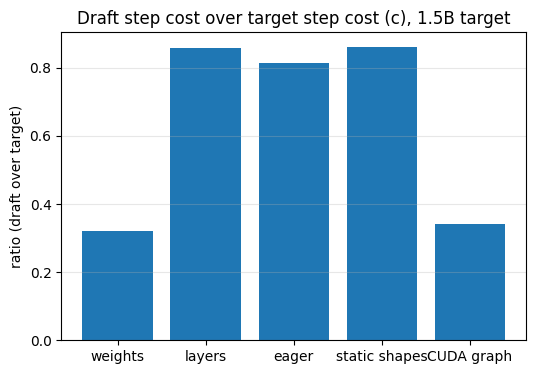

In [21]:
bar(["weights", "layers", "eager", "static shapes", "CUDA graph"],
    [gate_df.weight_ratio.iloc[0], gate_df.layer_ratio.iloc[0]] + gate_df.c.tolist(),
    f"Draft step cost over target step cost (c), {NAMES[TAGS_RUN[0]]} target", "ratio (draft over target)", save="stage7_cost_ratio")

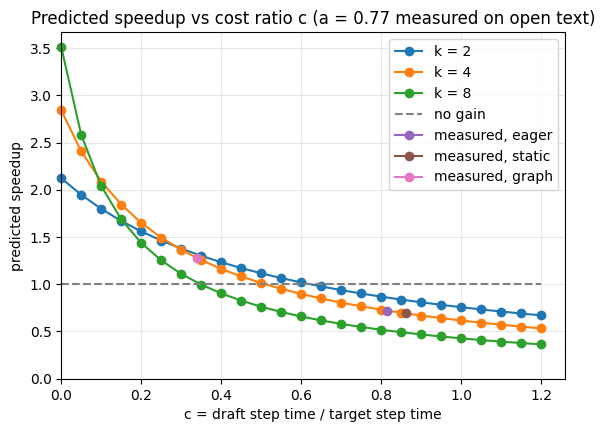

In [22]:
# How the verdict depends on c: predicted speedup against c for the measured acceptance, with the measured c of each mode marked
cs = [round(0.05 * i, 2) for i in range(0, 25)]
curve = pd.concat(
    [pd.DataFrame({"curve": f"k = {k}", "c": cs, "speedup": [predicted_speedup(alpha_open, k, c, v_gate) for c in cs]}) for k in KS]
    + [pd.DataFrame({"curve": "no gain", "c": [0, cs[-1]], "speedup": [1.0, 1.0]})]
    + [pd.DataFrame({"curve": f"measured, {r.requested}", "c": [r.c], "speedup": [r.predicted_x]}) for r in gate_df.itertuples()])
line_groups(curve, "c", "speedup", "curve", f"Predicted speedup vs cost ratio c (a = {alpha_open:.2f} measured on open text)",
            "predicted speedup", xlabel="c = draft step time / target step time", dashed=("no gain",), save="stage7_predicted_vs_c")

**How to read it.**

- **`c` against the two reference ratios.** The eager `c` sat near the layers ratio and far from the weights ratio, for both targets (about 0.84 against 0.86 and 0.32 for the 1.5B target, about 0.62 against 0.67 and 0.16 for the 3B target, from the cost table in section 5). The draft step is paying for kernel launches, not for reading weights, which is the overhead-bound picture of Stages 2 and 3, and the prediction above held.
- **Static shapes cost little and the graph removes most of the step.** The static path was within a few percent of the eager step, so the fixed shapes a graph needs are almost free. The capture worked on this GPU (if it had not, the notebook would have said why), and the graph took the draft step from about 21 ms to under 10 ms: `c` fell to about 0.39 and 0.27, much nearer the weights ratio than the layers ratio.
- **The verdict flipped with the graph.** At the measured acceptance the gate predicted a slowdown for the eager draft (about 0.7x) and a gain for the graph draft (about 1.3x), so whether this was a "no-go" or a "go" depended only on whether the step was captured. Sections 4 to 6 test the prediction. The graph's measured gain came out smaller than predicted, for a reason section 5 finds.
- **Why the curve matters.** The predicted speedup falls steeply as `c` rises. The graph moves the draft from the wrong side of break-even to the right side, but not far from it: a cheaper step (fewer layers, a quantized draft) or a bigger target is what would move it further.

---
## 2. The proposer: `DraftModel`

**Goal:** understand exactly how a draft model keeps its cache in step with a context that the target keeps rewriting.

**Concept.** The target accepts a prefix of the draft and adds its own token, so the context the draft sees next round is *almost* what it saw before: the previous context, plus the accepted guesses, plus one new token. Everything the draft guessed past the first rejection is gone. Recomputing the draft's cache from scratch every round would cost a prefill per round, so `DraftModel` keeps a cache and **syncs** it:

1. **Sync.** Find the longest prefix the new context shares with the tokens the cache holds (never longer than `len(context) - 1`, so at least one token is left to feed and there are fresh logits to read). `truncate` the cache to that length. The keys of guesses the target accepted are kept for free, the rest are dropped.
2. **Feed** the tokens the cache does not have yet in **one** pass: the whole prompt on the first call, then the bonus token, or the last guess and the bonus token after a fully accepted draft. The logits after the last one give the first guess.
3. **Guess** `k - 1` more tokens, one single-token step each, feeding each guess back in. The last guess is never fed (it has no keys yet), so a call costs exactly `k` draft forward passes, the unit the cost model counts.

```
round 1   context  A B C                 cache holds A B C, guesses g1 g2 g3 g4 (g1 g2 g3 fed, g4 not)
target    accepts g1 g2, rejects g3, adds b
round 2   context  A B C g1 g2 b         shares A B C g1 g2 with the cache -> truncate there (g3's keys dropped)
                                         feed [b] -> new guesses h1 h2 h3 h4
```

Why does a failure here not break the output? Because the **target** checks every token. A draft with a stale or wrong cache only guesses worse, which lowers `a` and wastes time; it cannot change what the target accepts. That is why section 3's control for this rollback shows acceptance collapsing while the output stays identical, and why the output-breaking control is the *target's* rollback, which Stage 6 already had.

**Three execution modes.** The `mode` argument chooses how the draft's single-token step runs:

- `"eager"`: an ordinary `KVCache` whose tensors are sliced to the current length, so shapes change every step. Nothing special, but it cannot be captured in a CUDA graph.
- `"static"`: a `StaticKVCache` of fixed shape `[layers, 1, kv_heads, max_len, head_dim]`. New keys are written with `index_copy_` at a position held in a device tensor, the whole buffer is returned, and the attention mask (`column <= position`) decides which keys count. Every shape and every address is the same on every step.
- `"graph"`: the static step (forward, argmax, write the guess back into the input tensor, advance the position tensor) is captured once with `torch.cuda.graph` after a warm-up on a side stream, and each step is then a single `replay()`. If capture fails for any reason (an unsupported op in the torch build, no CUDA) the model falls back to `"static"` and `graph_error` records why.

**The negative control.** `DraftModel(..., sync=False)` never truncates: it only appends what is new, so the keys of rejected guesses stay in its cache and leak into later guesses.

In [23]:
show = lambda xs: [tok.decode([t]) for t in xs]
demo = DraftModel(draft_model, 128)
ctx = tok("The best way to spend a quiet rainy afternoon is").input_ids

g1 = demo(ctx, 4)
print(f"round 1: context {len(ctx)} tokens -> guesses {show(g1)}")
print(f"         cache holds {demo.cache.length} keys = {len(ctx)} context + {len(g1) - 1} fed guesses (the last guess has no keys)\n")

# Suppose the target accepted the first two guesses, rejected the third and chose its own token b
b = tok(" a").input_ids[0]
ctx2 = ctx + g1[:2] + [b]
lcp = next((i for i, (x, y) in enumerate(zip(demo.tokens, ctx2)) if x != y), min(len(demo.tokens), len(ctx2)))
print(f"round 2: context {len(ctx2)} tokens; shares {lcp} tokens with the cache ({len(ctx)} old context + 2 accepted guesses)")
g2 = demo(ctx2, 4)
print(f"         the rejected guess's keys were dropped, {len(ctx2) - lcp} new token fed, cache now holds {demo.cache.length} keys, guesses {show(g2)}\n")

# Now suppose every guess was accepted, and the target added its bonus token
ctx3 = ctx2 + g2 + [b]
lcp = next((i for i, (x, y) in enumerate(zip(demo.tokens, ctx3)) if x != y), min(len(demo.tokens), len(ctx3)))
print(f"round 3: context {len(ctx3)} tokens; shares {lcp}; {len(ctx3) - lcp} new tokens are fed in ONE pass: the last guess (never fed before) and the bonus token")
g3 = demo(ctx3, 4)
print(f"         cache holds {demo.cache.length} keys, guesses {show(g3)}")

round 1: context 10 tokens -> guesses [' to', ' read', ' a', ' book']
         cache holds 13 keys = 10 context + 3 fed guesses (the last guess has no keys)

round 2: context 13 tokens; shares 13 tokens with the cache (10 old context + 2 accepted guesses)
         the rejected guess's keys were dropped, 0 new token fed, cache now holds 16 keys, guesses [' book', '.', ' But', ' what']

round 3: context 18 tokens; shares 16; 2 new tokens are fed in ONE pass: the last guess (never fed before) and the bonus token
         cache holds 21 keys, guesses [' book', ' to', ' read', '?']


**Takeaway.** The sync is a longest-common-prefix truncation plus a small feed. After a rejection the draft re-feeds one token, not the context, so the per-round cost is `k` steps and no prefill. The graph and static modes do exactly the same logical thing over a fixed-shape cache.

---
## 3. Correctness

**Goal:** check that the draft model, in every mode, changes only how many passes the target needs, never what it outputs, and that the two controls break what they should.

1. **Gate 1: the default paths still hold.** Our forward pass matches Hugging Face for both models.
2. **Gate 2: the sync is right.** After any pattern of accepted and rejected guesses, a `DraftModel` proposes exactly its own greedy continuation of the current context (compared with a fresh `generate_cached` of the draft, round by round), in all three modes. A mismatch only costs acceptance, so this is a quality check on the proposer, not on the output.
3. **Gate 3: speculative output equals plain greedy output of the target,** for the n-gram proposer and the draft model in every mode, on prompts of all three kinds.
4. **Gate 4: negative controls.** (a) A draft that skips its rollback (`sync=False`) loses acceptance, but the output stays identical. (b) The *target* skipping its rollback (`rollback=False`) breaks the output. (c) A draft that **is** the target accepts every guess and yields `k + 1` tokens per round, the ceiling of the method.

Reading the results: the checking pass feeds several tokens at once and the draft's static path attends over a masked buffer, so their matrix shapes differ from a plain one-token step and fp16 rounding can differ. A mismatch early in the sequence is a bug; a late one is usually a near-tie flipping, and we count how often it happens.

In [24]:
LOGIT_TOL = 1e-1   # fp16: a different shape changes the matmul kernel, so allow a few ulps at logit magnitude ~20
N = 32
prompt = "The key idea behind speculative decoding in LLM serving is"
ids = tok(prompt, return_tensors="pt").input_ids.to(device)
for name, hf_m, m in (("draft", draft_hf, draft_model), (f"target {NAMES[TAGS_RUN[0]]}", hf, target)):
    with torch.no_grad():
        d1 = (hf_m(ids).logits[:, -1].float() - m.forward(ids).float()).abs().max().item()
    ref = hf_m.generate(ids, attention_mask=torch.ones_like(ids), max_new_tokens=N, do_sample=False, pad_token_id=tok.eos_token_id)[0].tolist()
    mine = generate_cached(m, ids, N)[0][0].tolist()
    print(f"{name:12s} max abs logit diff vs HF: {d1:.4f}, cached vs HF first mismatch: {first_mismatch(ref, mine)}")
    assert d1 < LOGIT_TOL and first_mismatch(ref, mine) is None, f"the default path of the {name} model changed"

draft        max abs logit diff vs HF: 0.0200, cached vs HF first mismatch: None
target 1.5B  max abs logit diff vs HF: 0.0156, cached vs HF first mismatch: None


In [25]:
# Gate 2: the draft's own guesses after random accept / reject patterns, against a fresh greedy decode of the same context
def sync_agreement(d, ctx0, k=4, rounds=12, seed=0):
    rng = random.Random(seed)
    ctx, same, total = list(ctx0), 0, 0
    for _ in range(rounds):
        ref = generate_cached(draft_model, torch.tensor([ctx], device=device), k)[0][0, len(ctx):].tolist()
        got = d(ctx, k)
        same += sum(x == y for x, y in zip(got, ref)); total += k
        a = rng.randint(0, k)                                   # the target accepts a guesses, then adds a token of its own
        ctx = ctx + ref[:a] + [rng.randrange(1000, 20000)]
    return same / total

agree = {req: sync_agreement(d, PROMPT_IDS["open"][0]) for req, d in DRAFT.items()}
print({req: f"{100 * x:.0f}% of guesses equal the draft's own greedy decode" for req, x in agree.items()})
assert all(x >= 0.9 for x in agree.values()), "the draft cache sync is broken: its guesses differ from its own greedy decode"

{'eager': "98% of guesses equal the draft's own greedy decode", 'static': "98% of guesses equal the draft's own greedy decode", 'graph': "98% of guesses equal the draft's own greedy decode"}


In [26]:
# Gate 3: speculative output equals plain greedy output of the target
def plain(m, ids, n):
    return generate_cached(m, torch.tensor([ids], device=device), n)[0][0, len(ids):].tolist()

GATE_PROPS = {"n-gram": PromptLookup(), PROP_LABEL["eager"]: DRAFT["eager"], PROP_LABEL["graph"]: DRAFT["graph"]}
GATE3_NEW = 48
mismatch = {}
for name, plist in PROMPT_IDS.items():
    ids = plist[0]
    ref_out = plain(target, ids, GATE3_NEW)
    for pname, prop in GATE_PROPS.items():
        row = []
        for k in (2, 4, 8):
            out, st = generate_speculative(target, ids, GATE3_NEW, k=k, proposer=prop)
            mismatch[(name, pname, k)] = first_mismatch(ref_out, out)
            row.append(f"k={k}: {(len(out) - 1) / len(st['steps']):4.2f} tok/round, mismatch {mismatch[(name, pname, k)]}")
        print(f"{name:5s} {pname:12s} " + " | ".join(row))
assert all(m is None or m >= 24 for m in mismatch.values()), "speculative decoding changed the result early in the sequence"

copy  n-gram       k=2: 2.94 tok/round, mismatch None | k=4: 4.70 tok/round, mismatch None | k=8: 7.83 tok/round, mismatch None
copy  draft eager  k=2: 2.94 tok/round, mismatch None | k=4: 4.70 tok/round, mismatch None | k=8: 7.83 tok/round, mismatch None
copy  draft graph  k=2: 2.94 tok/round, mismatch None | k=4: 4.70 tok/round, mismatch None | k=8: 7.83 tok/round, mismatch None
code  n-gram       k=2: 1.47 tok/round, mismatch None | k=4: 1.57 tok/round, mismatch None | k=8: 1.62 tok/round, mismatch None
code  draft eager  k=2: 2.76 tok/round, mismatch None | k=4: 3.92 tok/round, mismatch None | k=8: 6.71 tok/round, mismatch None
code  draft graph  k=2: 2.76 tok/round, mismatch None | k=4: 3.92 tok/round, mismatch None | k=8: 6.71 tok/round, mismatch None
open  n-gram       k=2: 1.00 tok/round, mismatch None | k=4: 1.00 tok/round, mismatch None | k=8: 1.00 tok/round, mismatch None
open  draft eager  k=2: 2.24 tok/round, mismatch None | k=4: 2.61 tok/round, mismatch None | k=8: 2.76 t

In [27]:
# Gate 4: negative controls
ids_open = PROMPT_IDS["open"]
CONTROL_NEW = 48
def run_open(make_proposer):
    # a fresh proposer per prompt, so that the broken draft is tested on its missing rollback and not on its missing reset between prompts
    outs, steps = [], []
    for ids in ids_open:
        o, st = generate_speculative(target, ids, CONTROL_NEW, k=GATE_K, proposer=make_proposer())
        outs.append(o); steps += st["steps"]
    return outs, acceptance_alpha(steps), sum(len(o) - 1 for o in outs) / len(steps)

truth_open = [plain(target, ids, CONTROL_NEW) for ids in ids_open]
same = lambda outs: sum(o == t for o, t in zip(outs, truth_open))

# (a) the draft skips its rollback: it only appends, so the keys of rejected guesses stay in its cache
o_ok, a_ok, t_ok = run_open(lambda: DraftModel(draft_model, DRAFT_MAX_LEN))
o_bad, a_bad, t_bad = run_open(lambda: DraftModel(draft_model, 4096, sync=False))
print(f"(a) draft with sync:     a = {a_ok:.2f}, {t_ok:.2f} tokens/round, {same(o_ok)} of {len(ids_open)} outputs equal plain greedy")
print(f"    draft without sync:  a = {a_bad:.2f}, {t_bad:.2f} tokens/round, {same(o_bad)} of {len(ids_open)} outputs equal plain greedy")

# (b) the target skips its rollback. The rollback only matters after a REJECTED guess (when every guess is accepted it keeps everything
# it was fed), so there are two versions: the draft model on open text, where rejections are frequent, shown for information, and a
# proposer that is always wrong, which is rejected in every round and so is guaranteed to need the rollback. The second one asserts.
# Stale keys only change an output that depends on the context they corrupt, so a very repetitive output can survive them: the
# assertion asks for at least one of the three workloads to break, and for the version with the rollback to be exact on all of them.
def rejected_rounds(stats):
    return sum(1 for s in stats["steps"] if s["accepted"] < s["drafted"])

broke, rejected = 0, 0
for ids, truth in zip(ids_open, truth_open):
    o, st = generate_speculative(target, ids, CONTROL_NEW, k=GATE_K, proposer=DRAFT["eager"], rollback=False)
    broke += (o != truth); rejected += rejected_rounds(st)
print(f"(b) draft model on open text, target WITHOUT rollback: {rejected} rejected rounds, {broke} of {len(ids_open)} outputs differ from plain greedy")

def always_wrong(context, k):
    return [(context[-1] + 7 + j) % target.embed.shape[0] for j in range(k)]       # tokens the target will not choose
wrong_runs = {}
for name, plist in PROMPT_IDS.items():
    ids, n_new = plist[0], 32
    truth = plain(target, ids, n_new)
    good, st_good = generate_speculative(target, ids, n_new, k=GATE_K, proposer=always_wrong)
    bad, _ = generate_speculative(target, ids, n_new, k=GATE_K, proposer=always_wrong, rollback=False)
    wrong_runs[name] = (rejected_rounds(st_good), first_mismatch(truth, good), first_mismatch(truth, bad))
    print(f"    always-wrong guesses on {name:5s}: {wrong_runs[name][0]} rejected rounds, first mismatch vs plain with rollback {wrong_runs[name][1]}, without rollback {wrong_runs[name][2]}")

# (c) a draft that is the target: every guess is right, so a round yields k + 1 tokens
o_self, a_self, t_self = run_open(lambda: DraftModel(target, DRAFT_MAX_LEN))
rounds_needed = -(-(CONTROL_NEW - 1) // (GATE_K + 1))                      # the prefill gives the first token, each round gives at most k + 1
ceiling = (CONTROL_NEW - 1) / rounds_needed                                # a partly used last round lowers the average
print(f"(c) draft = target:      a = {a_self:.2f}, {t_self:.2f} tokens/round (the ceiling for {CONTROL_NEW} tokens is {ceiling:.2f}), {same(o_self)} of {len(ids_open)} outputs equal plain greedy")

assert same(o_ok) >= len(ids_open) - 1 and same(o_bad) >= len(ids_open) - 1, "a draft, good or broken, must never change the output (up to fp16 near-ties)"
assert all(r[0] > 0 for r in wrong_runs.values()), "the always-wrong proposer was never rejected, so the rollback control cannot show anything"
assert all(r[1] is None for r in wrong_runs.values()), "with the rollback the output must equal plain greedy decoding"
assert any(r[2] is not None for r in wrong_runs.values()), "skipping the target rollback did not break any output: the control shows nothing"
assert a_self > 0.9, "a draft that is the target should be accepted almost always"

(a) draft with sync:     a = 0.74, 2.94 tokens/round, 4 of 4 outputs equal plain greedy
    draft without sync:  a = 0.35, 1.52 tokens/round, 4 of 4 outputs equal plain greedy
(b) draft model on open text, target WITHOUT rollback: 90 rejected rounds, 4 of 4 outputs differ from plain greedy
    always-wrong guesses on copy : 30 rejected rounds, first mismatch vs plain with rollback None, without rollback 4
    always-wrong guesses on code : 30 rejected rounds, first mismatch vs plain with rollback None, without rollback 2
    always-wrong guesses on open : 29 rejected rounds, first mismatch vs plain with rollback None, without rollback 2
(c) draft = target:      a = 1.00, 4.70 tokens/round (the ceiling for 48 tokens is 4.70), 4 of 4 outputs equal plain greedy


**Reading the results**

| Symptom | Likely cause |
|---|---|
| Gate 1 fails for the draft or the target | The base model path regressed (RoPE, GQA or the cache view), independent of speculation. Fix this before reading the other gates. |
| Gate 2 fails for `eager` only | The sync keeps the wrong prefix (an off-by-one in the longest-common-prefix limit) or feeds the wrong tokens after a rejection. |
| Gate 2 fails for `static` or `graph` only | The fixed-shape path is wrong: the write position, the mask `column <= position`, or the position tensor not being advanced inside the captured step. A graph that replays stale addresses shows up here. |
| Gate 3 fails at the first speculative round | The checking pass has the wrong mask or positions. This is Stage 6's gate and should not regress. |
| Gate 3 fails only late in the sequence | fp16 numerics: a checking pass has a different shape from a one-token step and can flip a near-tie. Benign, but counted (section 4 reports how many outputs match exactly). |
| Control (a): the output changes when the draft skips its sync | It must not: the target checks every token. A change would mean the verifier trusts the draft. |
| Control (a): acceptance does not drop without the sync | Possible if the context is short and the stale keys are few. It says the draft is robust to a little corruption, not that the sync is unneeded. |
| Control (b): no mismatch without the target's rollback | No guess was rejected, so there was nothing to roll back (when every guess is accepted the rollback keeps everything it was fed). That is why the asserting version uses a proposer that is always wrong. Even then a very repetitive output can survive stale keys, so it asks for at least one of the three workloads to break. For the draft model on open text the number of outputs that break depends on the text, so it is shown and not asserted. |
| Control (c): `a` far below one | The draft and the target disagree on near-ties in fp16 (single-token steps against a multi-token pass). Report it. |

---
## 4. Acceptance by workload and draft length

**Goal:** measure `a` and tokens per round for both proposers on all three workloads, for both targets, in one session. This is the long run: every later number in sections 5 and 6 is a view of the table built here.

**Setup.** Three workloads from Stage 6: `copy` (the prompt holds a passage and asks for an exact copy), `code` (repetitive code continued in the same style) and `open` (free-form writing). For each workload plain greedy decoding is timed once and is the baseline of every row. Three proposers run with `k` in `KS`: the **n-gram** proposer (prompt lookup, as in Stage 6, rerun here so it shares the session, the GPU state and the prompts), the **eager draft model** and the **graph draft model** (labelled *static* if the capture was not possible). `MAX_NEW` tokens are generated per prompt and `N_PROMPTS` prompts per workload.

For each target the cell also measures `c` (as in section 1), the checking pass cost `v` for each `k`, and the cost of a plain step and a draft step at each batch size (for the projection in section 5). Targets are loaded one after the other and the first is freed before the second is loaded.

**Concept.** The n-gram proposer can only propose what is in the context, so it wins where the output repeats the input and offers nothing where it does not. The draft model proposes from what it has learned, so it should be right on ordinary prose, at the price of `k` draft steps per round. Longer drafts help only while the extra guesses are still likely right: with acceptance `a`, guess `j` is accepted with probability about `a^j`.

> **Predict** (the story to test, not to assert):
>
> - On `copy`, the n-gram proposer reaches high acceptance for free, so it should be hard to beat. The draft model should also do well, since copying is easy for a small model, but it pays for its draft steps.
> - On `code`, both should accept often.
> - On `open`, Stage 6 found that the n-gram proposer still gained, probably because it also searches the model's own output and a small greedy model repeats itself. The draft model should keep a moderate `a` from agreeing with its bigger sibling. If `a` on `open` is clearly higher for the draft model, the draft is the better *guesser* there, whatever its cost.
> - Whether `a` is higher or lower for the 3B target than for the 1.5B is open: a bigger target is a different distribution from the 0.5B draft, and acceptance can go either way. We measure it.

In [28]:
SWEEP, COST, VCT, VCD = [], [], [], []
hf = target = None      # the sections above are done with the first target; the loop below manages the models from here
PROPOSERS = {"n-gram": PromptLookup(), PROP_LABEL["eager"]: DRAFT["eager"], PROP_LABEL["graph"]: DRAFT["graph"]}

for model_id in TARGET_IDS:
    tag = TAGS[model_id]
    print(f"\n=== target {model_id} ===")
    COST += measure_cost(model_id)
    _, target_m = get_target(model_id)
    ks_tokens = [1] + [k + 1 for k in KS]
    VCT += [{"target": tag, **r} for r in verify_cost(target_m, VERIFY_BATCHES, ks_tokens, CTX)]
    VCD += [{"target": tag, **r} for r in verify_cost(draft_model, VERIFY_BATCHES, [1], CTX)]
    rows = sweep_proposers(target_m, PROMPT_IDS, MAX_NEW, KS, PROPOSERS)
    SWEEP += [{"target": tag, **r} for r in rows]

cost_df, vct_df, vcd_df = pd.DataFrame(COST), pd.DataFrame(VCT), pd.DataFrame(VCD)


=== target Qwen/Qwen2.5-1.5B ===
copy  n-gram       k=2:   62.9 tok/s (1.63x)  a=0.72  1.77 tokens/round  guess 0.0 ms + check 27.8 ms  exact True
copy  n-gram       k=4:   74.5 tok/s (1.93x)  a=0.74  2.07 tokens/round  guess 0.0 ms + check 27.4 ms  exact True
copy  n-gram       k=8:   83.5 tok/s (2.17x)  a=0.76  2.33 tokens/round  guess 0.0 ms + check 27.4 ms  exact True
copy  draft eager  k=2:   36.2 tok/s (0.94x)  a=0.87  2.62 tokens/round  guess 43.9 ms + check 28.2 ms  exact True
copy  draft eager  k=4:   33.8 tok/s (0.88x)  a=0.88  3.88 tokens/round  guess 86.3 ms + check 28.2 ms  exact True
copy  draft eager  k=8:   27.2 tok/s (0.71x)  a=0.88  5.40 tokens/round  guess 169.8 ms + check 29.1 ms  exact True
copy  draft graph  k=2:   41.4 tok/s (1.07x)  a=0.87  2.62 tokens/round  guess 32.9 ms + check 30.0 ms  exact True
copy  draft graph  k=4:   47.5 tok/s (1.23x)  a=0.88  3.88 tokens/round  guess 51.3 ms + check 29.9 ms  exact True
copy  draft graph  k=8:   45.6 tok/s (1.18x)  a=

config.json:   0%|          | 0.00/683 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

copy  n-gram       k=2:   58.4 tok/s (2.41x)  a=0.89  2.30 tokens/round  guess 0.0 ms + check 38.2 ms  exact False
copy  n-gram       k=4:   75.4 tok/s (3.10x)  a=0.91  3.10 tokens/round  guess 0.0 ms + check 39.7 ms  exact True
copy  n-gram       k=8:   96.4 tok/s (3.97x)  a=0.92  4.06 tokens/round  guess 0.0 ms + check 40.3 ms  exact True
copy  draft eager  k=2:   33.5 tok/s (1.38x)  a=0.94  2.79 tokens/round  guess 45.2 ms + check 37.3 ms  exact True
copy  draft eager  k=4:   34.4 tok/s (1.42x)  a=0.94  4.31 tokens/round  guess 86.6 ms + check 37.5 ms  exact False
copy  draft eager  k=8:   31.6 tok/s (1.30x)  a=0.94  6.43 tokens/round  guess 164.6 ms + check 37.6 ms  exact True
copy  draft graph  k=2:   39.4 tok/s (1.62x)  a=0.94  2.79 tokens/round  guess 32.7 ms + check 37.3 ms  exact True
copy  draft graph  k=4:   47.1 tok/s (1.94x)  a=0.94  4.31 tokens/round  guess 52.1 ms + check 37.9 ms  exact False
copy  draft graph  k=8:   50.2 tok/s (2.07x)  a=0.94  6.43 tokens/round  guess 

In [29]:
# Add the cost model's prediction to every draft-model row: expected tokens per round / (k * c + v), and the c seen during the run
sweep_df = pd.DataFrame(SWEEP)
plain_ms = sweep_df[sweep_df.k == 0].set_index(["target", "workload"]).target_ms
pred, c_micro, v_col, c_run = [], [], [], []
for r in sweep_df.itertuples():
    is_draft = r.proposer.startswith("draft") and r.k > 0
    if is_draft:
        c = float(cost_df[(cost_df.target == r.target) & (cost_df.requested == ("eager" if r.proposer == "draft eager" else "graph"))].c.iloc[0])
        v = float(vct_df[(vct_df.target == r.target) & (vct_df.batch == 1) & (vct_df.tokens_per_seq == r.k + 1)].rel_to_one_token.iloc[0])
        pred.append(predicted_speedup(r.alpha, r.k, c, v)); c_micro.append(c); v_col.append(v)
        c_run.append(r.guess_ms / (r.k * plain_ms[(r.target, r.workload)]))
    else:
        pred.append(None); c_micro.append(None); v_col.append(None); c_run.append(None)
sweep_df["c_micro"], sweep_df["v"], sweep_df["predicted_x"], sweep_df["c_run"] = c_micro, v_col, pred, c_run
sweep_df["overhead_x"] = sweep_df.predicted_x / sweep_df.speedup_x            # above 1: the prediction was too optimistic
KREF = 4 if 4 in KS else KS[0]
view = ["target", "workload", "proposer", "k", "alpha", "expected_tokens", "tokens_per_step", "acceptance", "draft_found_frac", "n_exact", "n_prompts"]
sweep_df[sweep_df.k > 0][view].round(2)

,target,workload,proposer,k,alpha,expected_tokens,tokens_per_step,acceptance,draft_found_frac,n_exact,n_prompts
1,1p5b,copy,n-gram,2,0.72,2.23,1.77,0.58,0.67,4,4
2,1p5b,copy,n-gram,4,0.74,3.01,2.07,0.45,0.61,4,4
3,1p5b,copy,n-gram,8,0.76,3.83,2.33,0.32,0.56,4,4
4,1p5b,copy,draft eager,2,0.87,2.63,2.62,0.82,0.99,4,4
5,1p5b,copy,draft eager,4,0.88,3.97,3.88,0.72,1.00,4,4
6,1p5b,copy,draft eager,8,0.88,5.75,5.40,0.57,1.00,4,4
7,1p5b,copy,draft graph,2,0.87,2.63,2.62,0.82,0.99,4,4
8,1p5b,copy,draft graph,4,0.88,3.97,3.88,0.72,1.00,4,4
9,1p5b,copy,draft graph,8,0.88,5.75,5.40,0.57,1.00,4,4
11,1p5b,code,n-gram,2,0.75,2.31,2.01,0.64,0.79,4,4


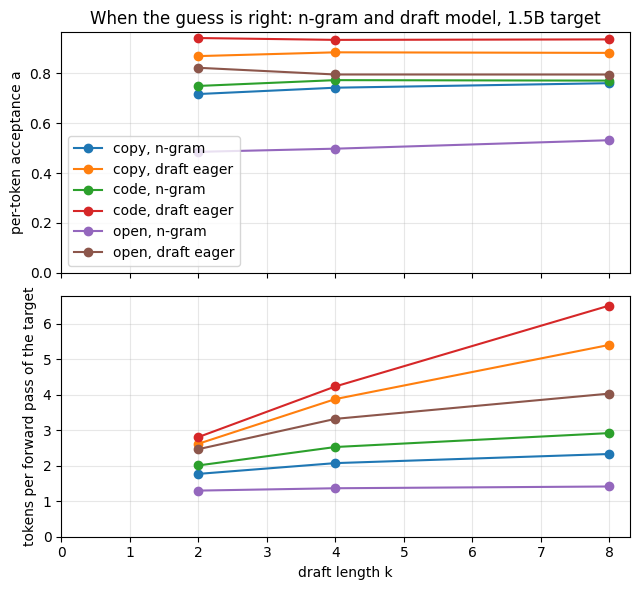

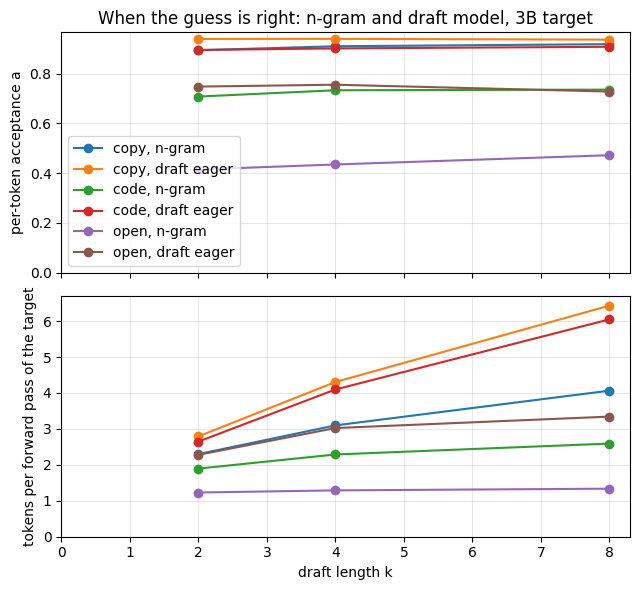

In [30]:
for tag in TAGS_RUN:
    d = sweep_df[(sweep_df.target == tag) & (sweep_df.k > 0) & (sweep_df.proposer != PROP_LABEL["graph"])].copy()
    d["line"] = d.workload + ", " + d.proposer
    line_groups_stacked(d, "k", ["alpha", "tokens_per_step"], "line",
                        f"When the guess is right: n-gram and draft model, {NAMES[tag]} target",
                        ["per-token acceptance a", "tokens per forward pass of the target"],
                        xlabel="draft length k", save=f"stage7_acceptance_{tag}")

**How to read it.**

- **`a` by proposer and workload.** The draft model's `a` was higher than the n-gram lookup's on every workload and target, with the widest gap on open text (about 0.8 against 0.5 with the 1.5B target, about 0.74 against 0.44 with the 3B target). The lookup's `a` is measured only on rounds in which it found a match (`draft_found_frac` is the share of rounds that did). So on ordinary prose the draft is the better guesser, as predicted. Whether it is the better decoder is the question of section 6.
- **`a` is flat in `k`.** The per-token acceptance barely moved as the draft got longer, so the independence assumption of the cost model holds, and the closed-form tokens per round matched the measured tokens per pass for the draft model to within a tenth. For the n-gram lookup the closed form is optimistic: it often proposes fewer than `k` tokens, or none.
- **Tokens per pass** is what the target gets per checking pass. It is what the speedup is built from, before paying for the guesses.
- **`eager` and `graph` drafts guess the same tokens:** the same `a` and the same tokens per pass in the table. They differ only in the time a guess takes (section 5).
- **`n_exact`** counts the prompts whose output equals plain greedy exactly: 201 of 216 over the whole sweep, the exceptions mostly on open text and with the 3B target. As in Stage 6 an fp16 near-tie (a checking pass and a one-token step round differently) is the likely cause, but this notebook does not locate where the differences start.
- Each cell is a single pass over a handful of prompts, so expect noise.

---
## 5. Speedup: against `k`, against the prediction, and against batch size

**Goal:** turn acceptance into time, test the cost model, and project the result to batching.

### 5.1 Speedup against `k`

**Concept.** The measured speedup is wall time of plain decoding over wall time of speculative decoding, prefill and guessing included. For the draft model it should follow the cost model, `tokens per round / (k * c + v)`, with the eager and the graph draft differing only in `c`.

> **Predict:** with `c` from section 1, which of the eager and the graph draft is faster at each `k`, and is there an optimum `k` inside the range? Increasing `k` adds an expensive guess, so the optimum is where the next guess is no longer worth its cost: sooner when `c` is large.

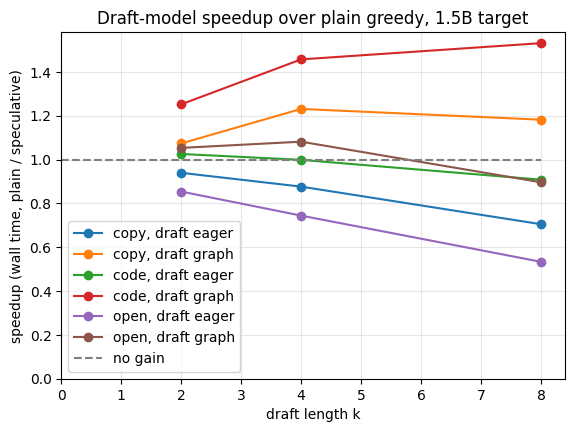

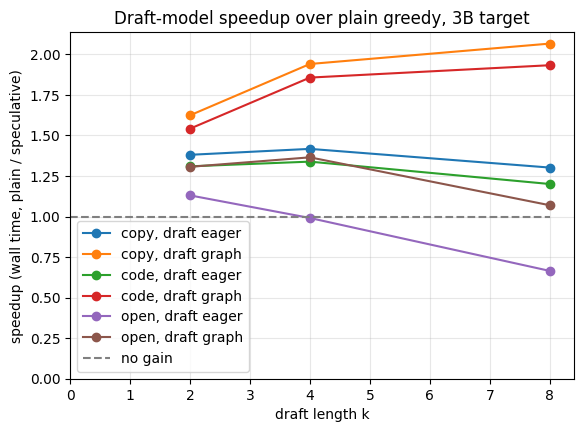

,target,workload,proposer,k,speedup_x,predicted_x,overhead_x,alpha,tokens_per_step,c_micro,c_run,v
4,1p5b,copy,draft eager,2,0.94,0.95,1.01,0.87,2.62,0.84,0.85,1.10
5,1p5b,copy,draft eager,4,0.88,0.90,1.02,0.88,3.88,0.84,0.83,1.10
6,1p5b,copy,draft eager,8,0.71,0.74,1.05,0.88,5.40,0.84,0.82,1.11
7,1p5b,copy,draft graph,2,1.07,1.40,1.30,0.87,2.62,0.39,0.64,1.10
8,1p5b,copy,draft graph,4,1.23,1.50,1.22,0.88,3.88,0.39,0.49,1.10
9,1p5b,copy,draft graph,8,1.18,1.37,1.15,0.88,5.40,0.39,0.42,1.11
14,1p5b,code,draft eager,2,1.03,1.02,1.00,0.94,2.81,0.84,0.83,1.10
15,1p5b,code,draft eager,4,1.00,0.99,0.99,0.93,4.23,0.84,0.79,1.10
16,1p5b,code,draft eager,8,0.91,0.90,0.99,0.94,6.51,0.84,0.76,1.11
17,1p5b,code,draft graph,2,1.25,1.51,1.20,0.94,2.81,0.39,0.59,1.10


In [31]:
for tag in TAGS_RUN:
    d = sweep_df[(sweep_df.target == tag) & sweep_df.proposer.str.startswith("draft") & (sweep_df.k > 0)].copy()
    d["line"] = d.workload + ", " + d.proposer
    d = pd.concat([d, pd.DataFrame({"line": "no gain", "k": [0, max(KS)], "speedup_x": 1.0})])
    line_groups(d, "k", "speedup_x", "line", f"Draft-model speedup over plain greedy, {NAMES[tag]} target",
                "speedup (wall time, plain / speculative)", xlabel="draft length k", dashed=("no gain",), save=f"stage7_speedup_{tag}")
sweep_df[(sweep_df.k > 0) & sweep_df.proposer.str.startswith("draft")][["target", "workload", "proposer", "k", "speedup_x", "predicted_x", "overhead_x", "alpha", "tokens_per_step", "c_micro", "c_run", "v"]].round(2)

### 5.2 Measured against predicted

The prediction uses three measured inputs: `a` from the run, `c` from the micro-benchmark and `v` from `verify_cost`. If the model is right, measured speedup falls on the line *predicted = measured*. `c_run` is `c` recomputed from the run itself, the mean guess time per round over `k` plain target steps. Only draft-model rows are plotted: the n-gram proposer has no fixed `k` (it proposes fewer tokens, or none), so the closed form does not apply to it.

**What the run showed.**

- **For the eager draft the prediction is accurate,** and the micro-benchmark `c` and `c_run` agree: a round is `k` ordinary draft steps. Predicted over measured is 0.86 to 1.06 with the micro-benchmark `c` and 0.93 to 1.07 with `c_run`.
- **For the graph draft the micro-benchmark `c` overstates the gain** (the points sit above the line on average: predicted over measured is 0.99 to 1.30, mean 1.11), and `c_run` is clearly higher than `c_micro`. The guess time shows why: a round's guess time was one eager step plus `k - 1` graph steps, to within about a tenth at every `k` and target (for the 1.5B target at `k = 4`, about 51 ms measured against 21 + 3 x 9.9 = 51 ms from the two step times alone). The first guess of a round feeds the new tokens (the bonus token, and sometimes the last accepted guess) through an ordinary pass, which the graph does not cover. Given `c_run`, predicted over measured is 0.93 to 1.07 for the eager draft and 0.92 to 1.09 for the graph draft.
- **The remaining noise is mostly in the plain baseline.** It is timed once per workload and it moved between runs of this notebook: the 3B `copy` baseline was about 54 ms in the first run and about 41 ms in each of the two reruns, which took the best 3B `copy` n-gram speedup from about 5.65x to about 4.1x and then 4.0x, and in the first run it dragged predicted over measured down to 0.79 for those rows. The 3B baselines were above the 3B micro-benchmark step in all three runs, by a few percent to about a half, for a reason this notebook does not locate; the 1.5B baselines were not. The cost ratios, the ratios between proposers and the projections moved much less. A steadier baseline (several timings, the median) is exercise 8.
- **A single mean hides the error.** With the micro-benchmark `c` the eager and graph errors have opposite signs, so one mean over all draft rows can look close to one while neither proposer is. The cell below prints each proposer separately, and with `c_run`.

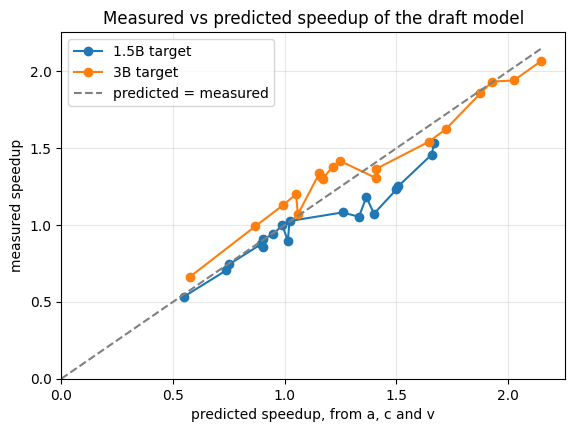

draft eager  predicted / measured (1.00 is perfect): c from the micro-benchmark 0.86 to 1.06 (mean 0.95), c from the run 0.93 to 1.07 (mean 1.00)
draft graph  predicted / measured (1.00 is perfect): c from the micro-benchmark 0.99 to 1.30 (mean 1.11), c from the run 0.92 to 1.09 (mean 1.00)


In [32]:
dm = sweep_df[sweep_df.proposer.str.startswith("draft") & (sweep_df.k > 0)].copy()
dm["predicted_run_x"] = dm.expected_tokens / (dm.k * dm.c_run + dm.v)       # the same model, with the cost per guess seen in the run
top = float(max(dm.predicted_x.max(), dm.speedup_x.max()))
parts = []
for tag in TAGS_RUN:
    d = dm[dm.target == tag].sort_values("predicted_x")
    parts.append(pd.DataFrame({"group": f"{NAMES[tag]} target", "predicted": d.predicted_x, "measured": d.speedup_x}))
parts.append(pd.DataFrame({"group": "predicted = measured", "predicted": [0.0, top], "measured": [0.0, top]}))
pm = pd.concat(parts)
line_groups(pm, "predicted", "measured", "group", "Measured vs predicted speedup of the draft model",
            "measured speedup", xlabel="predicted speedup, from a, c and v", dashed=("predicted = measured",), save="stage7_predicted_vs_measured")
for name, g in dm.groupby("proposer", sort=False):
    micro, run = g.predicted_x / g.speedup_x, g.predicted_run_x / g.speedup_x
    print(f"{name:12s} predicted / measured (1.00 is perfect): c from the micro-benchmark {micro.min():.2f} to {micro.max():.2f} (mean {micro.mean():.2f}), "
          f"c from the run {run.min():.2f} to {run.max():.2f} (mean {run.mean():.2f})")

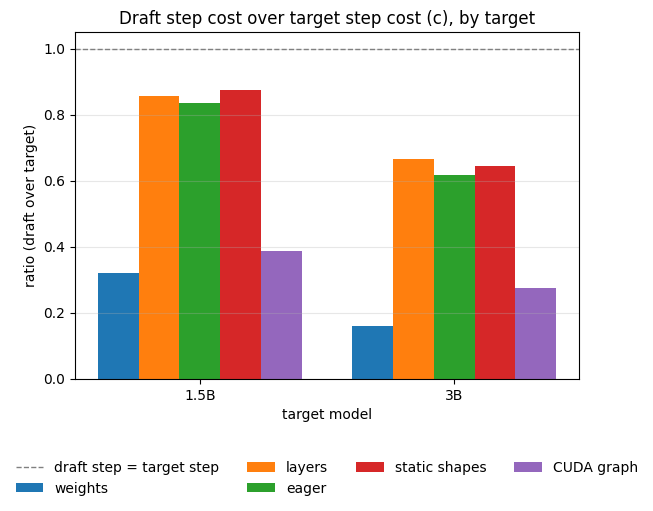

,target,requested,mode,draft_ms,target_ms,c,weight_ratio,layer_ratio
0,1p5b,eager,eager,21.288,25.484,0.835,0.32,0.857
1,1p5b,static,static,22.314,25.484,0.876,0.32,0.857
2,1p5b,graph,graph,9.899,25.484,0.388,0.32,0.857
3,3b,eager,eager,21.352,34.660,0.616,0.16,0.667
4,3b,static,static,22.336,34.660,0.644,0.16,0.667
5,3b,graph,graph,9.523,34.660,0.275,0.16,0.667


In [33]:
cost_view = cost_df.copy()
grouped_bar([NAMES[t] for t in TAGS_RUN],
            {"weights": [cost_view[cost_view.target == t].weight_ratio.iloc[0] for t in TAGS_RUN],
             "layers": [cost_view[cost_view.target == t].layer_ratio.iloc[0] for t in TAGS_RUN],
             **{lbl: [float(cost_view[(cost_view.target == t) & (cost_view.requested == req)].c.iloc[0]) for t in TAGS_RUN]
                for lbl, req in (("eager", "eager"), ("static shapes", "static"), ("CUDA graph", "graph"))}},
            "Draft step cost over target step cost (c), by target", "ratio (draft over target)", hline=1.0,
            hline_label="draft step = target step", xlabel="target model", save="stage7_cost_by_target")
cost_df[["target", "requested", "mode", "draft_ms", "target_ms", "c", "weight_ratio", "layer_ratio"]].round(3)

### 5.3 Under batching: a projection

**Concept.** As in Stage 6, we have not built batched draft-model speculation (every sequence has its own draft cache and accepts a different number of tokens, exercise 2), so this is a **projection** from measurements, not a measurement. Per sequence, a round yields `tokens_per_step` tokens (section 4) and costs `k` draft steps plus one checking pass, both at batch size `B`:

```
projected speedup at batch B  =  tokens per round / ( k * c_B + v_B )
    c_B = draft step time at batch B / target step time at batch B       (eager, from verify_cost of each model)
    v_B = checking pass of k + 1 tokens over a one-token step at batch B  (verify_cost of the target)
```

For the n-gram proposer `c_B` is taken as zero. It assumes every sequence in the batch behaves like the single sequences measured in section 4 and ignores raggedness, so it overstates the real gain. It is reliable for the *trend*. The CUDA graph is not projected: its step is captured for batch 1, so how its advantage changes with batch size is not measured here.

> **Predict:** the gain of both proposers falls as the batch grows, because the spare compute that speculation spends is the same spare compute that batching uses (Stage 6). The draft model should fall faster at first, since each of its `k` draft steps is a full step that gets heavier with batch size. At large batch the draft step becomes bandwidth-bound or compute-bound and `c_B` falls toward the weight ratio, which partly offsets this. Which effect wins is the thing to read.

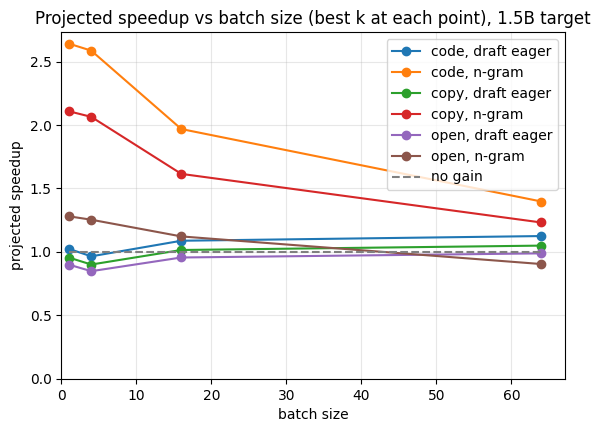

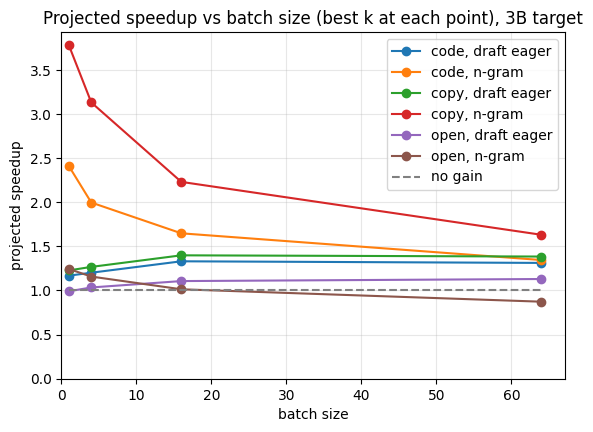

,target,workload,proposer,batch,k,tokens_per_step,c_b,v_b,projected_x
36,1p5b,code,draft eager,1,2,2.81,0.82,1.10,1.02
37,1p5b,code,draft eager,4,2,2.81,0.91,1.09,0.96
38,1p5b,code,draft eager,16,2,2.81,0.71,1.16,1.09
39,1p5b,code,draft eager,64,2,2.81,0.53,1.44,1.12
32,1p5b,code,n-gram,1,8,2.92,0.00,1.11,2.64
33,1p5b,code,n-gram,4,8,2.92,0.00,1.13,2.59
30,1p5b,code,n-gram,16,4,2.53,0.00,1.28,1.97
27,1p5b,code,n-gram,64,2,2.01,0.00,1.44,1.40
12,1p5b,copy,draft eager,1,2,2.62,0.82,1.10,0.96
13,1p5b,copy,draft eager,4,2,2.62,0.91,1.09,0.90


In [34]:
proj_rows = []
for tag in TAGS_RUN:
    vt, vd = vct_df[vct_df.target == tag], vcd_df[vcd_df.target == tag]
    base = sweep_df[(sweep_df.target == tag) & (sweep_df.k > 0) & sweep_df.proposer.isin(["n-gram", "draft eager"])]
    for r in base.itertuples():
        for b in VERIFY_BATCHES:
            v_b = float(vt[(vt.batch == b) & (vt.tokens_per_seq == r.k + 1)].rel_to_one_token.iloc[0])
            c_b = 0.0 if r.proposer == "n-gram" else float(vd[vd.batch == b].ms.iloc[0] / vt[(vt.batch == b) & (vt.tokens_per_seq == 1)].ms.iloc[0])
            proj_rows.append({"target": tag, "workload": r.workload, "proposer": r.proposer, "k": r.k, "batch": b,
                              "tokens_per_step": r.tokens_per_step, "c_b": c_b, "v_b": v_b,
                              "projected_x": r.tokens_per_step / (r.k * c_b + v_b)})
proj_df = pd.DataFrame(proj_rows)
proj_best = proj_df.loc[proj_df.groupby(["target", "workload", "proposer", "batch"]).projected_x.idxmax()]     # best k for each point
for tag in TAGS_RUN:
    d = proj_best[proj_best.target == tag].copy()
    d["line"] = d.workload + ", " + d.proposer
    d = pd.concat([d[["line", "batch", "projected_x"]], pd.DataFrame({"line": "no gain", "batch": VERIFY_BATCHES, "projected_x": 1.0})])
    line_groups(d, "batch", "projected_x", "line", f"Projected speedup vs batch size (best k at each point), {NAMES[tag]} target",
                "projected speedup", xlabel="batch size", dashed=("no gain",), save=f"stage7_batch_projection_{tag}")
proj_best[["target", "workload", "proposer", "batch", "k", "tokens_per_step", "c_b", "v_b", "projected_x"]].round(2)

**How to read it.**

- **Measured against the cost model.** See 5.2: the three inputs (`a`, `c`, `v`) explain the eager draft, and explain the graph draft once `c` is the cost per guess seen in the run. The eager draft was slower than plain decoding with the 1.5B target at the longest `k` on every workload, so the verdict of section 1 held: the draft step is too expensive when it runs eagerly.
- **What the graph changed.** The eager and graph rows have the same `a` and differ only in `c`, so the difference in speedup is the CUDA graph's effect on the guessing time. The graph draft was faster than the eager draft at every `k`, workload and target (by about 1.1 to 1.7 times), and its best `k` was longer. The `c` chart shows where the graph leaves `c`: much nearer the weights ratio than the layers ratio, and the first guess of each round is the cost left over.
- **The optimum `k`.** For the eager draft the best `k` was the smallest or the next one. For the graph draft it was 4 or 8. For the n-gram lookup the speedup was still rising at the largest `k` tried on every workload, so its optimum is beyond the range.
- **The projection (5.3).** The n-gram lookup's projected gain eroded with batch size: on open text it was at or below one at the largest batch. The draft model's projected gain held up or rose, which is the opposite of the prediction above. The draft step's cost relative to the target's fell with batch size (from about 0.8 to 0.5 with the 1.5B target, from about 0.6 to 0.3 with the 3B target), because the target's step time grew faster with batch size than the draft's (roughly 2 to 3 times by batch 64, against about 1.6 times). With the 3B target the draft overtook the lookup on open text by batch 16 in the projection. The notebook does not break either step down further, so that is read off the measured step times.
- **The projection is a trend.** It is built from single-sequence acceptance, an eager draft and a verifier measured at fixed context, and ignores raggedness and the need for one draft cache per sequence, so do not read its numbers as predictions of a batched server.

---
## 6. Head to head: n-gram against draft model

**Goal:** the comparison the stage exists for. Both proposers feed the *same* checker, on the same prompts, in the same session, so any difference is the proposer's.

**What is compared.** For each workload and target we take, per proposer, the draft length `k` with the best measured speedup, and put the proposers side by side (the draft model in its eager and its graph form, because they can win in different places). The time-split chart shows what each round costs: the time spent guessing against the time spent in the target's checking pass, at one draft length.

> **Predict** (the story to test, not to assert): the n-gram proposer should win on `copy`, where guessing is free and almost always right, and the draft model should win on ordinary prose, where the context offers less to copy. Stage 6 found that the n-gram proposer gained on `open` too, so that last part is the least certain. `code` is the interesting case between them. A draft model that is not cheap enough (`c` near one) can lose even on `open`, which would make the n-gram proposer the practical choice everywhere on this hardware.

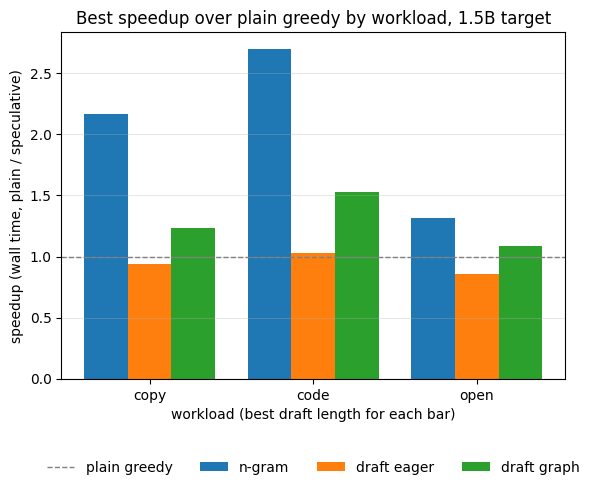

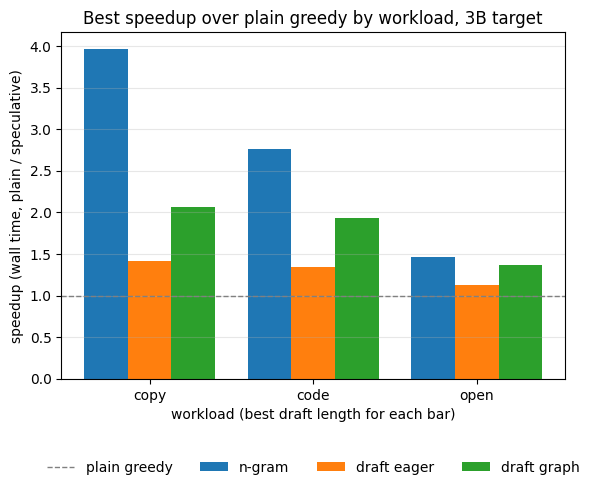

,target,workload,proposer,best_k,speedup_x,alpha,tokens_per_step,guess_ms,target_ms
0,1p5b,copy,n-gram,8,2.17,0.76,2.33,0.03,27.43
1,1p5b,copy,draft eager,2,0.94,0.87,2.62,43.87,28.17
2,1p5b,copy,draft graph,4,1.23,0.88,3.88,51.28,29.88
3,1p5b,code,n-gram,8,2.70,0.77,2.92,0.03,28.66
4,1p5b,code,draft eager,2,1.03,0.94,2.81,45.22,28.72
5,1p5b,code,draft graph,8,1.53,0.94,6.51,85.45,29.10
6,1p5b,open,n-gram,8,1.32,0.53,1.42,0.02,27.34
7,1p5b,open,draft eager,2,0.85,0.82,2.47,44.95,29.13
8,1p5b,open,draft graph,4,1.08,0.80,3.32,49.92,28.72
9,3b,copy,n-gram,8,3.97,0.92,4.06,0.03,40.32


In [35]:
best_rows = []
for tag in TAGS_RUN:
    for wl in PROMPT_IDS:
        for p in PROPOSERS:
            d = sweep_df[(sweep_df.target == tag) & (sweep_df.workload == wl) & (sweep_df.proposer == p) & (sweep_df.k > 0)]
            r = d.loc[d.speedup_x.idxmax()]
            best_rows.append({"target": tag, "workload": wl, "proposer": p, "best_k": int(r.k), "speedup_x": r.speedup_x, "alpha": r.alpha,
                              "tokens_per_step": r.tokens_per_step, "guess_ms": r.guess_ms, "target_ms": r.target_ms})
best_df = pd.DataFrame(best_rows)
for tag in TAGS_RUN:
    d = best_df[best_df.target == tag]
    grouped_bar(list(PROMPT_IDS), {p: [float(d[(d.workload == w) & (d.proposer == p)].speedup_x.iloc[0]) for w in PROMPT_IDS] for p in PROPOSERS},
                f"Best speedup over plain greedy by workload, {NAMES[tag]} target", "speedup (wall time, plain / speculative)",
                hline=1.0, hline_label="plain greedy", xlabel="workload (best draft length for each bar)", save=f"stage7_head_to_head_{tag}")
best_df.round(2)

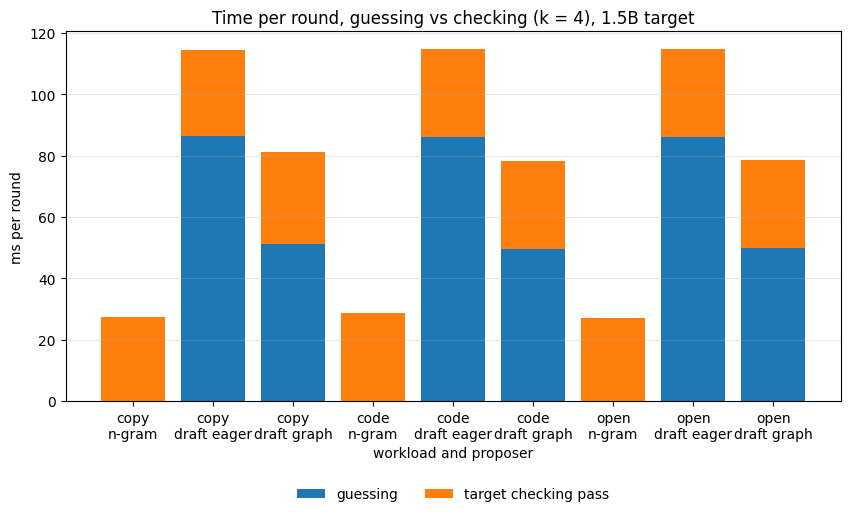

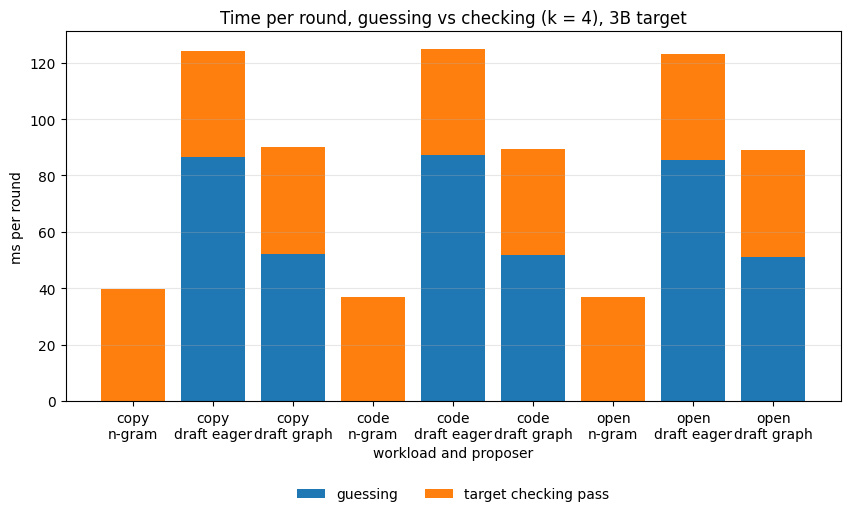

In [36]:
for tag in TAGS_RUN:
    d = sweep_df[(sweep_df.target == tag) & (sweep_df.k == KREF)]
    order = [(w, p) for w in PROMPT_IDS for p in PROPOSERS]
    rows = [d[(d.workload == w) & (d.proposer == p)].iloc[0] for w, p in order]
    stacked_bar([f"{w}\n{p}" for w, p in order], {"guessing": [r.guess_ms for r in rows], "target checking pass": [r.target_ms for r in rows]},
                f"Time per round, guessing vs checking (k = {KREF}), {NAMES[tag]} target", "ms per round", xlabel="workload and proposer",
                figsize=(10, 4.8), save=f"stage7_time_split_{tag}")

**How to read it.**

- **Who wins where.** The n-gram lookup had the tallest bar on every workload with both targets. The prediction was n-gram on `copy` and draft model on `open`; the first half held. On `open` the lookup also won, clearly with the 1.5B target (about 1.3x against about 1.1x for the graph draft) and narrowly with the 3B target (about 1.5x against about 1.4x). Stage 6 had found the lookup gains on open text too, probably because it also searches the model's own output. So the draft model's higher `a` is real and still not enough: its guesses are not free.
- **The time split explains the bars.** For the n-gram proposer the guessing slice is negligible, so a round costs about one checking pass. For the draft model the guessing slice was comparable to or taller than the checking pass for every setting. When the slice is as tall as the pass, the draft model has to produce about twice the tokens per round of the lookup just to break even, and it did not.
- **Eager against graph.** Same `a`, different guessing slice: removing the launch overhead of the draft step is what separates a slowdown from a gain for the 1.5B target, and it was not enough to beat the lookup.
- **The two targets.** The bigger target made the draft relatively cheaper (lower `c`) and the gap to the lookup on open text narrower. The plain baseline is timed once per workload and it moved between runs of this notebook (the 3B `copy` baseline was about 54 ms in the first run and about 41 ms in each of the two reruns), so a single 3B speedup is good to about a quarter. Compare proposers within a workload, which share the baseline, and not 3B speedups across runs or with 1.5B ones.
- **A hybrid.** The lookup wins at batch size one everywhere on this GPU, so a proposer that tries the lookup first and falls back to the draft model only when there is no match is the version worth building (exercise 3). This notebook does not measure it.

---
## 7. Save results

`results/stage7.json` holds everything needed to re-plot without re-running:

- `env` and `config`: GPU, library versions, model revisions, and every experiment parameter,
- `cost`: `c` for every draft mode and target, with the weights ratio, the layers ratio and any graph-capture error,
- `gate`: the go/no-go numbers of section 1 (`a`, `v`, `c` and the predicted speedup per mode),
- `verify_cost`: the cost of a checking pass for each target and of a draft step, by batch size,
- `sweep`: sections 4 to 6 (plain decoding and every proposer, by target, workload and `k`, with the prediction),
- `projection`: section 5.3.

Final published numbers should come from one consistent environment.

In [37]:
def records(df):
    # JSON has no NaN: missing values become null
    return df.round(4).astype(object).where(pd.notnull(df), None).to_dict(orient="records")

ENV["model_revision"] = "; ".join(f"{m.split('/')[-1]} {str(h)[:8]}" for m, h in ENV["revisions"].items())   # every model loaded by now
out = {
    "env": {**ENV, "max_pos": MAX_POS},
    "config": {
        "seed": SEED, "quick": QUICK, "draft": DRAFT_ID, "targets": TARGET_IDS, "context": CTX, "draft_max_len": DRAFT_MAX_LEN,
        "gate": {"k": GATE_K, "max_new": GATE_NEW, "workload": "open"},
        "sweep": {"max_new": MAX_NEW, "ks": KS, "proposers": list(PROPOSERS), "ngram": "prompt lookup (ngram_max 3, ngram_min 1)",
                  "prompts": {name: len(plist) for name, plist in PROMPT_IDS.items()}},
        "verify_cost": {"context": CTX, "batches": VERIFY_BATCHES},
    },
    "cost": records(cost_df),
    "gate": {"target": TAGS_RUN[0], "k": GATE_K, "alpha_open": round(alpha_open, 4), "v": round(v_gate, 4),
             "tokens_per_round": round(tokens_round, 4), "rounds": len(steps), "rows": records(gate_df)},
    "verify_cost": records(pd.concat([vct_df.assign(model="target"), vcd_df.assign(model="draft")], ignore_index=True)),
    "sweep": records(sweep_df),
    "projection": records(proj_df),
}
save_results("results/stage7.json", out)

saved results/stage7.json


### Figure inventory

Every figure was written to `results/` by the cell that produced it. This cell lists them and fails if one is missing.

In [38]:
FIGURES = {
    "stage7_cost_ratio.png": "Draft step cost over target step cost: weights, layers and each execution mode (section 1)",
    "stage7_predicted_vs_c.png": "Predicted speedup vs the cost ratio c, with the measured modes marked (section 1)",
    "stage7_cost_by_target.png": "The cost ratio c by target model (section 5)",
    "stage7_predicted_vs_measured.png": "Measured vs predicted speedup of the draft model (section 5)",
}
for tag in TAGS_RUN:
    FIGURES.update({
        f"stage7_acceptance_{tag}.png": f"Acceptance and tokens per pass, n-gram and draft model, {NAMES[tag]} target (section 4)",
        f"stage7_speedup_{tag}.png": f"Draft-model speedup vs draft length, {NAMES[tag]} target (section 5)",
        f"stage7_batch_projection_{tag}.png": f"Projected speedup vs batch size, {NAMES[tag]} target (section 5)",
        f"stage7_head_to_head_{tag}.png": f"Best speedup by workload and proposer, {NAMES[tag]} target (section 6)",
        f"stage7_time_split_{tag}.png": f"Time per round, guessing vs checking, {NAMES[tag]} target (section 6)",
    })
missing = [f for f in FIGURES if not os.path.exists(f"results/{f}")]
assert not missing, f"missing figures: {missing}"
pd.DataFrame({"file": list(FIGURES), "what it shows": list(FIGURES.values())})

,file,what it shows
0,stage7_cost_ratio.png,Draft step cost over target step cost: weights...
1,stage7_predicted_vs_c.png,"Predicted speedup vs the cost ratio c, with th..."
2,stage7_cost_by_target.png,The cost ratio c by target model (section 5)
3,stage7_predicted_vs_measured.png,Measured vs predicted speedup of the draft mod...
4,stage7_acceptance_1p5b.png,"Acceptance and tokens per pass, n-gram and dra..."
5,stage7_speedup_1p5b.png,"Draft-model speedup vs draft length, 1.5B targ..."
6,stage7_batch_projection_1p5b.png,"Projected speedup vs batch size, 1.5B target (..."
7,stage7_head_to_head_1p5b.png,"Best speedup by workload and proposer, 1.5B ta..."
8,stage7_time_split_1p5b.png,"Time per round, guessing vs checking, 1.5B tar..."
9,stage7_acceptance_3b.png,"Acceptance and tokens per pass, n-gram and dra..."


---
## Publish results (and code, if this is the newest notebook) to GitHub (optional)

Set `PUSH = True` to push this run to your repo. The cell below is identical in every notebook of the series except `PUSH` and `COMMIT_MSG`. It calls `publish()` from `bench/publish.py`, which clones the repo, pulls, copies `results/` in, and copies `minivllm/` and `bench/` in only if this notebook's stage is at least the stage recorded in the repo (`minivllm/STAGE`). It then commits and pushes, printing git's output and raising an error if any git step fails. This is the newest notebook, so it publishes code as well as results. An older notebook rerun later pushes results only and cannot overwrite this code.

It needs a Kaggle secret named `minivllm-github-token` holding a GitHub token with write access. The repo name and git identity are constants at the top of `bench/publish.py`. The token is used only for the clone, pull and push commands and is not stored in the repo's git config.

In [39]:
PUSH = True                              # True: publish to GitHub at the end of the run
COMMIT_MSG = "Stage 7: draft-model speculation"   # the only other line that differs between notebooks
FORCE_CODE = False                       # leave False: code is published automatically from the newest stage

if PUSH:
    from kaggle_secrets import UserSecretsClient
    from bench.publish import publish, SECRET_NAME
    publish(token=UserSecretsClient().get_secret(SECRET_NAME), message=COMMIT_MSG, force_code=FORCE_CODE)

Cloning into 'mini-vllm'...
remote: Enumerating objects: 1037, done.        
remote: Counting objects: 100% (169/169), done.        
remote: Compressing objects: 100% (122/122), done.        
remote: Total 1037 (delta 82), reused 113 (delta 44), pack-reused 868 (from 2)        
Receiving objects: 100% (1037/1037), 22.16 MiB | 37.51 MiB/s, done.
Resolving deltas: 100% (518/518), done.
Already up to date.
From https://github.com/chizkidd/minivllm
 * branch            HEAD       -> FETCH_HEAD
notebook stage 7, repo code stage 7: publishing code and results
[main 60aafa3] Stage 7: draft-model speculation
 13 files changed, 903 insertions(+), 903 deletions(-)
Enumerating objects: 31, done.
Counting objects: 100% (31/31), done.
Delta compression using up to 4 threads
Compressing objects: 100% (16/16), done.
Writing objects: 100% (16/16), 692.16 KiB | 16.48 MiB/s, done.
Total 16 (delta 3), reused 0 (delta 0), pack-reused 0
To https://github.com/chizkidd/minivllm.git
   1bcf3a9..60aafa3  HEAD 

---
## 8. Summary and lessons

In [40]:
from IPython.display import Markdown, display

def show_table(rows, headers=("Metric", "Result", "Note")):
    esc = lambda c: str(c).replace("|", "\\|")   # a literal | would break the table
    out_ = ["| " + " | ".join(headers) + " |", "|" + "|".join(["---"] * len(headers)) + "|"]
    for r in rows:
        out_.append("| " + " | ".join([f"**{esc(r[0])}**"] + [esc(c) for c in r[1:]]) + " |")
    display(Markdown("\n".join(out_)))

g = {r.requested: r for r in gate_df.itertuples()}
rows = [
    (f"Cost ratio c, {NAMES[TAGS_RUN[0]]} target", f"eager {g['eager'].c:.2f}, static shapes {g['static'].c:.2f}, CUDA graph {g['graph'].c:.2f}",
     f"weights ratio {g['eager'].weight_ratio:.2f}, layers ratio {g['eager'].layer_ratio:.2f}; graph mode ran as {g['graph'].mode}"),
    ("Acceptance a on open text (gate)", f"{alpha_open:.2f} at k = {GATE_K}", f"{tokens_round:.2f} tokens per round predicted, v = {v_gate:.2f}"),
    ("Gate verdict", f"best predicted speedup {gate_df.predicted_x.max():.2f}x ({gate_df.loc[gate_df.predicted_x.idxmax()].requested})",
     "go" if gate_df.predicted_x.max() > 1 else "no-go for open text on this hardware"),
]
for tag in TAGS_RUN:
    for wl in PROMPT_IDS:
        d = best_df[(best_df.target == tag) & (best_df.workload == wl)]
        cell = ", ".join(f"{r.proposer} {r.speedup_x:.2f}x (k = {r.best_k})" for r in d.itertuples())
        win = d.loc[d.speedup_x.idxmax()]
        rows.append((f"{NAMES[tag]} target, {wl}", cell, f"best: {win.proposer}"))
ex = sweep_df[sweep_df.k > 0]
rows.append(("Exactness", f"{int(ex.n_exact.sum())} of {int(ex.n_prompts.sum())} outputs identical to plain greedy", "the rest differ late in the generation, probably an fp16 near-tie (not located)"))
show_table(rows)

| Metric | Result | Note |
|---|---|---|
| **Cost ratio c, 1.5B target** | eager 0.81, static shapes 0.86, CUDA graph 0.34 | weights ratio 0.32, layers ratio 0.86; graph mode ran as graph |
| **Acceptance a on open text (gate)** | 0.77 at k = 4 | 3.15 tokens per round predicted, v = 1.11 |
| **Gate verdict** | best predicted speedup 1.28x (graph) | go |
| **1.5B target, copy** | n-gram 2.17x (k = 8), draft eager 0.94x (k = 2), draft graph 1.23x (k = 4) | best: n-gram |
| **1.5B target, code** | n-gram 2.70x (k = 8), draft eager 1.03x (k = 2), draft graph 1.53x (k = 8) | best: n-gram |
| **1.5B target, open** | n-gram 1.32x (k = 8), draft eager 0.85x (k = 2), draft graph 1.08x (k = 4) | best: n-gram |
| **3B target, copy** | n-gram 3.97x (k = 8), draft eager 1.42x (k = 4), draft graph 2.07x (k = 8) | best: n-gram |
| **3B target, code** | n-gram 2.77x (k = 8), draft eager 1.34x (k = 4), draft graph 1.93x (k = 8) | best: n-gram |
| **3B target, open** | n-gram 1.46x (k = 8), draft eager 1.13x (k = 2), draft graph 1.37x (k = 4) | best: n-gram |
| **Exactness** | 201 of 216 outputs identical to plain greedy | the rest differ late in the generation, probably an fp16 near-tie (not located) |

### What we learned

#### Questions

- **Is the draft step cheap?** (Section 1 and the `c` chart: `c` in eager, static and graph form, against the weights ratio and the layers ratio.)
- **Is the draft right?** (Section 4: `a` by workload, `k` and proposer.)
- **Does the cost model explain the speedup?** (Section 5: measured against predicted.)
- **What did the CUDA graph change?** (Sections 1, 5 and 6: `c`, and the speedup of the graph draft against the eager one.)
- **Who wins where?** (Section 6: n-gram against draft model by workload and target.)
- **Does it survive batching?** (Section 5.3: a projection.)

#### Answers

- **Is the draft step cheap?** Not when it runs eagerly. Its cost followed the share of layers (about 0.84 and 0.62 of a target step), not the share of weights (about 0.32 and 0.16): the step is launch-bound. A CUDA graph cut it to about half or less, to about 0.39 and 0.27.
- **Is the draft right?** Yes, more often than the n-gram lookup on every workload and target, with the widest gap on open text, and its acceptance barely moved with the draft length.
- **Does the cost model explain the speedup?** Yes, once it is given the cost per guess the run actually paid. The micro-benchmark cost ratio overstates the graph draft's gain, because a round is one eager pass (the first guess, which feeds the new tokens) plus `k - 1` graph replays.
- **What did the CUDA graph change?** It turned the gate from a no-go into a go, made the graph draft faster than the eager draft at every setting, and moved its best draft length up. It did not make the draft model beat the n-gram lookup.
- **Who wins where?** The n-gram lookup, on every workload and both targets, at batch size one on this GPU; narrowest on open text with the 3B target. The draft model is the better guesser and a worse decoder, because its guesses cost about as much as the checking pass. (The plain baseline is timed once and moved between runs, so a single 3B speedup is good to about a quarter; only comparisons within a workload are safe.)
- **Does it survive batching?** In the projection the lookup's gain erodes with batch size and the draft's holds up, because the target's step grows with batch size faster than the draft's. With the 3B target the draft overtakes the lookup on open text at the larger batches. It is a projection, not a measurement.

### Next: the engine outside the notebook

Seven stages built the engine one idea at a time: a KV cache, batching, continuous scheduling, a paged cache, an n-gram guesser and a draft-model guesser over one generic verifier. Every `%%writefile` module is now the final source. The next step is to leave the notebook: package the engine, add what a server needs (a real request loop on a real clock, end-of-sequence stopping, sampling), run it on a bigger GPU where decode is bandwidth-bound and a small model is proportionally cheaper, and compare it with an established serving system on the same traces and metrics. That is also the place for **weight quantization**, which pays off once the step is limited by reading the weights rather than by launching kernels.

### Exercises

1. **Speculative sampling.** Greedy checking accepts a draft token only if it equals the target's argmax. For sampling at a temperature above zero, accept a draft token with probability `min(1, p_target / p_draft)` and, on rejection, resample from the residual distribution `max(0, p_target - p_draft)` normalised. Implement it behind the same `proposer` interface (the proposer must now return the draft's probabilities too). Why does this keep the output distribution exactly the target's? Check it by sampling many short continuations and comparing frequencies with the target alone.
2. **Batched draft-model speculation.** Run speculation inside the continuous or paged scheduler: one draft cache per running sequence (or a paged one), a ragged accept length per sequence per round. What has to change in the draft's decode view? Compare the measured speedup with the projection of section 5.3.
3. **A hybrid proposer.** Try the n-gram match first and call the draft model only when there is no match (or when the match is shorter than `k`). When does it beat both proposers? Measure how often each side is used per workload.
4. **Self-speculation.** Use the first few layers of the target as the draft (no second model, shared weights and cache). The draft step now costs a fixed share of the target's layers. How does `a` depend on how many layers you keep, and where does the product of `a` and `c` peak?
5. **Adaptive `k`.** Choose `k` per round from the running acceptance estimate and the measured `c` and `v`, by maximising `predicted_speedup`. Does it beat the best fixed `k` of section 5 on a mixed workload?
6. **A cheaper draft.** Quantize the draft's weights, or share its embedding table, and measure `c` again. Which part of the draft step moves, given what section 1 found about where its time goes?
7. **Graph the first guess too.** Capture the first guess of each round in a CUDA graph as well. Its input has a variable length (the bonus token, and sometimes the last accepted guess), so try one graph per length, or always feed the same number of tokens and mask the extra. How much of the gap between the micro-benchmark `c` and the cost per guess seen in the run does it close?
8. **A steadier baseline.** `sweep_proposers` times each plain baseline once. Time it several times, take the median, and rerun the 3B target. How much of the 3B `copy` speedup was a slow baseline?

### References

- Leviathan et al., *Fast Inference from Transformers via Speculative Decoding*: https://arxiv.org/abs/2211.17192
- Chen et al., *Accelerating Large Language Model Decoding with Speculative Sampling*: https://arxiv.org/abs/2302.01318
- Saxena, *Prompt Lookup Decoding*: https://github.com/apoorvumang/prompt-lookup-decoding
- Qwen2.5 technical report: https://arxiv.org/abs/2412.15115
- PyTorch, *Accelerating PyTorch with CUDA Graphs*: https://pytorch.org/blog/accelerating-pytorch-with-cuda-graphs/
- Kwon et al., *Efficient Memory Management for LLM Serving with PagedAttention* (vLLM): https://arxiv.org/abs/2309.06180

---

# Appendix

Refer to the simple examples below to see how the cost model behaves. Nothing here is measured: it is the formula of section 1 evaluated on a grid.

## A.1. Predicted speedup for a grid of acceptance and cost ratio

Draft length `k = 4`, checking pass cost `v = 1`. Read down a column to see how acceptance pays, and along a row to see what a more expensive draft step costs. The sign of the verdict changes along a diagonal: a cheap draft can afford a modest acceptance, an expensive one needs a very high acceptance.

In [41]:
A_GRID = [0.3, 0.5, 0.7, 0.9]
C_GRID = [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]
grid = pd.DataFrame({f"c = {c}": [predicted_speedup(a, 4, c, 1.0) for a in A_GRID] for c in C_GRID}, index=[f"a = {a}" for a in A_GRID])
grid.round(2)

,c = 0.1,c = 0.2,c = 0.4,c = 0.6,c = 0.8,c = 1.0
a = 0.3,1.02,0.79,0.55,0.42,0.34,0.29
a = 0.5,1.38,1.08,0.75,0.57,0.46,0.39
a = 0.7,1.98,1.54,1.07,0.82,0.66,0.55
a = 0.9,2.93,2.28,1.58,1.20,0.98,0.82


## A.2. The best draft length for each point

The `k` that maximises the predicted speedup, searched from 1 to 16. A costly draft step (large `c`) pushes the best `k` down because each extra guess is paid for in full; a high acceptance pushes it up because the extra guess is likely right. `n/a` marks points where no `k` beats plain decoding (the best predicted speedup is not above one).

In [42]:
def best_k(a, c, v=1.0, kmax=16):
    k = max(range(1, kmax + 1), key=lambda k: predicted_speedup(a, k, c, v))
    return k if predicted_speedup(a, k, c, v) > 1.0 else "n/a"
pd.DataFrame({f"c = {c}": [best_k(a, c) for a in A_GRID] for c in C_GRID}, index=[f"a = {a}" for a in A_GRID])

,c = 0.1,c = 0.2,c = 0.4,c = 0.6,c = 0.8,c = 1.0
a = 0.3,1,1,n/a,n/a,n/a,n/a
a = 0.5,2,1,1,n/a,n/a,n/a
a = 0.7,4,3,2,1,n/a,n/a
a = 0.9,10,7,4,2,1,n/a
